
# ReliableVAEP — Universal Bootstrap Minimum Test (self-contained Kaggle version)

This notebook has **one job only**: determine a defensible common number of player-preserving match-bootstrap draws \(B\) for ReliableVAEP.

The previous version failed because it expected pre-generated `player_match_vaep.csv` and cohort files to already exist in Kaggle. **This version removes that dependency.** With Kaggle Internet enabled, it rebuilds the required player-match VAEP inputs from the same final analysis pipelines for:

1. Premier League 2015/16;
2. Barcelona 2015/16–2019/20;
3. Barcelona 2008/09–2012/13;
4. Bayer Leverkusen 2023/24;
5. FA Women's Super League 2018/19–2020/21.

It then tests only the **bootstrap Monte Carlo size**. It does not select \(B\) because a round number looks convenient.

## Selection rule

ReliableVAEP uses pairwise support at \(P_{ij}\ge0.90\) (or \(\le0.10\)). We predeclare a 95% Monte Carlo half-width target of **0.01** at the 0.90 decision boundary. This is one percentage point, i.e. 10% of the distance from 0.90 to 1.00. The corresponding Wilson-score calculation gives a finite analytical lower bound.

From that lower bound upward, candidate \(B\) values are tested under independent random seeds. A dataset passes only if:

- median absolute change in 2.5th/97.5th rank-interval endpoints across seeds is ≤ **1 rank**;
- the 95th percentile of endpoint changes is ≤ **2 ranks**;
- median Spearman agreement of bootstrap-median player ordering across seeds is ≥ **0.995**;
- supported/unresolved pair classifications agree across seeds for ≥ **99%** of diagnostic pairs.

To avoid accepting an accidental one-point crossing, the criteria must hold for **three consecutive tested \(B\) values**.

The final value is the **smallest common \(B\)** satisfying the analytical precision rule and sustained empirical convergence in every dataset.

> Important: the repeated convergence test is performed on the bootstrap primitives (rank distributions and pairwise support decisions), not on the downstream Bradley–Terry/RAR output. This avoids choosing \(B\) to make RAR itself look favorable.

### Before running

- Use a Kaggle Python runtime **≤ 3.12**.
- Turn **Internet ON**.
- A GPU is not required.
- The first run is computationally heavy because the notebook reconstructs the canonical VAEP player-match tables. Cached files in `/kaggle/working` are reused if you rerun in the same saved Kaggle version/session.


In [17]:

# ================================================================
# CELL 1 — KAGGLE-SAFE ISOLATED ENVIRONMENT
# ================================================================
#
# IMPORTANT:
# Kaggle Internet must be ON.
#
# This setup:
#   1. uses /kaggle/working only;
#   2. installs only the small pure-Python "virtualenv" helper into
#      Kaggle's host environment if it is missing;
#   3. creates /kaggle/working/rv_vaep_env;
#   4. installs the complete VAEP stack INSIDE that environment;
#   5. leaves Kaggle's NumPy/pandas/scipy/sklearn untouched.
#
# No runtime restart is required.
# ================================================================

import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

if not Path("/kaggle/working").exists():
    raise RuntimeError(
        "This notebook is the Kaggle-specific version, but /kaggle/working "
        "was not found. Please run it inside a Kaggle Notebook."
    )

if sys.version_info >= (3, 13):
    raise RuntimeError(
        "Please use a Kaggle Python runtime <= 3.12. "
        "socceraction 1.5.3 is not designed for Python 3.13."
    )

BASE_DIR = Path("/kaggle/working")
ENV_DIR = BASE_DIR / "rv_vaep_env"
ENV_PY = ENV_DIR / "bin" / "python"
ENV_PIP = ENV_DIR / "bin" / "pip"
READY = ENV_DIR / ".reliablevaep_bootstrap_minimum_ready_v2"

IMPORT_TEST = r"""
import numpy
import pandas
import scipy
import sklearn
import xgboost
import socceraction

from socceraction.data.statsbomb import StatsBombLoader
from socceraction.vaep import VAEP
import socceraction.spadl as spadl

print("numpy        =", numpy.__version__)
print("pandas       =", pandas.__version__)
print("scipy        =", scipy.__version__)
print("sklearn      =", sklearn.__version__)
print("xgboost      =", xgboost.__version__)
print("socceraction =", getattr(socceraction, "__version__", "installed"))

# NumPy/pandas binary compatibility smoke test.
df = pandas.DataFrame({"x": numpy.arange(5, dtype=float)})
assert float(df["x"].sum()) == 10.0

print("KAGGLE_ISOLATED_ENV_OK")
"""


def run_capture(args, timeout=None):
    clean_env = os.environ.copy()
    clean_env.pop("PYTHONPATH", None)
    clean_env["PYTHONNOUSERSITE"] = "1"
    return subprocess.run(
        [str(x) for x in args],
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        timeout=timeout,
        env=clean_env,
    )


def environment_is_healthy():
    if not (
        ENV_PY.exists()
        and ENV_PIP.exists()
        and READY.exists()
    ):
        return False

    test = run_capture(
        [ENV_PY, "-c", IMPORT_TEST]
    )

    if (
        test.returncode == 0
        and "KAGGLE_ISOLATED_ENV_OK" in test.stdout
    ):
        print("Existing isolated environment verified:")
        print(test.stdout)
        return True

    print("Existing isolated environment is incomplete/unhealthy.")
    print(test.stdout)
    return False


if not environment_is_healthy():

    # Remove only our own previous environment.
    if ENV_DIR.exists():
        print("Removing incomplete ReliableVAEP environment:", ENV_DIR)
        shutil.rmtree(ENV_DIR, ignore_errors=True)

    # ------------------------------------------------------------
    # Install virtualenv only if unavailable.
    # virtualenv is pure Python and does not alter NumPy/pandas.
    # ------------------------------------------------------------
    if importlib.util.find_spec("virtualenv") is None:
        print("Installing the lightweight virtualenv helper into Kaggle...")
        helper = run_capture([
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--no-cache-dir",
            "virtualenv==20.28.0",
        ])

        print(helper.stdout)

        if helper.returncode != 0:
            raise RuntimeError(
                "Could not install virtualenv.\n"
                "Make sure Kaggle Internet is ON.\n\n"
                + helper.stdout
            )
    else:
        print("virtualenv helper is already available.")

    # ------------------------------------------------------------
    # Create isolated environment using virtualenv.
    # This avoids system ensurepip entirely.
    # ------------------------------------------------------------
    print("\nCreating isolated environment:", ENV_DIR)

    create = run_capture([
        sys.executable,
        "-m",
        "virtualenv",
        "--clear",
        str(ENV_DIR),
    ])

    print(create.stdout)

    if (
        create.returncode != 0
        or not ENV_PY.exists()
        or not ENV_PIP.exists()
    ):
        raise RuntimeError(
            "virtualenv could not create the isolated environment.\n\n"
            + create.stdout
        )

    # ------------------------------------------------------------
    # Install one internally consistent stack.
    # These packages exist ONLY inside /kaggle/working/rv_vaep_env.
    # ------------------------------------------------------------
    packages = [
        "numpy==1.26.4",
        "pandas==2.1.4",
        "scipy==1.13.1",
        "scikit-learn==1.5.2",
        "xgboost==2.1.4",
        "matplotlib==3.9.2",
        "tqdm==4.66.5",
        "multimethod==1.10",
        "pandera==0.17.2",
        "socceraction[statsbomb]==1.5.3",
    ]

    print("\nInstalling the isolated ReliableVAEP stack...")
    print("This can take a few minutes on the first run.")

    install = run_capture([
        ENV_PY,
        "-m",
        "pip",
        "install",
        "--no-cache-dir",
        *packages,
    ])

    print(install.stdout)

    if install.returncode != 0:
        raise RuntimeError(
            "Package installation failed INSIDE the isolated environment.\n"
            "Kaggle's host NumPy/pandas environment has not been changed.\n\n"
            + install.stdout
        )

    # ------------------------------------------------------------
    # Verify dependency consistency.
    # ------------------------------------------------------------
    print("\nChecking isolated dependency consistency...")

    check = run_capture([
        ENV_PY,
        "-m",
        "pip",
        "check",
    ])

    print(
        check.stdout
        if check.stdout.strip()
        else "pip check: no dependency conflicts"
    )

    if check.returncode != 0:
        raise RuntimeError(
            "Dependency conflicts remain inside the isolated environment.\n\n"
            + check.stdout
        )

    # ------------------------------------------------------------
    # Import and binary compatibility test.
    # ------------------------------------------------------------
    print("\nVerifying isolated imports...")

    verify = run_capture([
        ENV_PY,
        "-c",
        IMPORT_TEST,
    ])

    print(verify.stdout)

    if (
        verify.returncode != 0
        or "KAGGLE_ISOLATED_ENV_OK" not in verify.stdout
    ):
        raise RuntimeError(
            "The isolated environment was created, but its scientific stack "
            "failed verification.\n\n"
            + verify.stdout
        )

    READY.write_text("ready", encoding="utf-8")

    print("\nKaggle isolated environment setup completed successfully.")

else:
    print("\nReusing the verified Kaggle isolated environment.")

print("\nAnalysis Python:", ENV_PY)
print("Kaggle host scientific packages were NOT downgraded or replaced.")


Installing the lightweight virtualenv helper into Kaggle...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 291.2 MB/s eta 0:00:00


Creating isolated environment: /kaggle/working/rv_vaep_env
created virtual environment CPython3.12.13.final.0-64 in 356ms
  creator CPython3Posix(dest=/kaggle/working/rv_vaep_env, clear=True, no_vcs_ignore=False, global=False)
  seeder FromAppData(download=False, pip=bundle, via=copy, app_data_dir=/root/.local/share/virtualenv)
    added seed packages: pip==24.3.1
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator


Installing the isolated ReliableVAEP stack...
This can take a few minutes on the first run.
Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other 

In [18]:

# ================================================================
# CELL 2 — TEST CONFIGURATION + ANALYTICAL LOWER BOUND
# ================================================================

from pathlib import Path
from statistics import NormalDist
import itertools
import math
import os
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

PAIRWISE_SUPPORT = 0.90

# A priori Monte Carlo precision target:
# 95% half-width <= 0.01 at the 0.90 decision boundary.
MC_CONFIDENCE = 0.95
MC_HALF_WIDTH_TARGET = 0.01

# Cross-seed empirical convergence criteria.
N_REPLICATES = 8
SUSTAINED_B_POINTS = 3
MEDIAN_ENDPOINT_DEV_MAX = 1.0
P95_ENDPOINT_DEV_MAX = 2.0
MEDIAN_RANK_SPEARMAN_MIN = 0.995
PAIR_CLASS_AGREEMENT_MIN = 0.99

# Search ceiling. If no sustained common solution is found, increase MAX_B
# and rerun rather than manually picking a larger number.
MAX_B = 6000
GRID_STEP = 100

# For very large cohorts, evaluating every pair under 8 independent
# 6000-draw streams would be unnecessarily expensive. We therefore
# include every adjacent raw-rank pair plus a fixed diagnostic sample.
PAIR_SAMPLE_SIZE = 10_000
PAIR_DIAGNOSTIC_SEED = 88021
PAIR_BLOCK_SIZE = 1000

BASE_SEED = 20260928

INPUT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_inputs")
RESULT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_results")
SCRIPT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_builder_scripts")

INPUT_ROOT.mkdir(parents=True, exist_ok=True)
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
SCRIPT_ROOT.mkdir(parents=True, exist_ok=True)


def wilson_half_width(n, p, confidence=0.95):
    z = NormalDist().inv_cdf(0.5 + confidence / 2.0)
    n = float(n)
    denom = 1.0 + z*z/n
    return (
        z / denom
        * math.sqrt(p * (1.0 - p) / n + z*z / (4.0 * n*n))
    )


def minimum_n_for_half_width(p, target_half_width, confidence=0.95):
    lo, hi = 1, 2
    while wilson_half_width(hi, p, confidence) > target_half_width:
        hi *= 2

    while lo < hi:
        mid = (lo + hi) // 2
        if wilson_half_width(mid, p, confidence) <= target_half_width:
            hi = mid
        else:
            lo = mid + 1
    return lo


B_MC = minimum_n_for_half_width(
    PAIRWISE_SUPPORT,
    MC_HALF_WIDTH_TARGET,
    MC_CONFIDENCE,
)

# Exact analytical boundary plus the regular 100-draw grid above it.
first_grid = int(math.ceil(B_MC / GRID_STEP) * GRID_STEP)
CANDIDATE_B = [B_MC] + list(range(first_grid, MAX_B + 1, GRID_STEP))
CANDIDATE_B = sorted(set(x for x in CANDIDATE_B if x <= MAX_B))

print("=" * 88)
print("PREDECLARED MONTE CARLO PRECISION RULE")
print("=" * 88)
print(f"Pairwise support threshold              : {PAIRWISE_SUPPORT:.2f}")
print(f"Required {MC_CONFIDENCE:.0%} half-width at p=.90    : <= {MC_HALF_WIDTH_TARGET:.3f}")
print(f"Analytical minimum B (Wilson criterion) : {B_MC}")
print(f"Half-width at B={B_MC}                  : {wilson_half_width(B_MC, PAIRWISE_SUPPORT):.6f}")
print(f"Candidate B range                       : {CANDIDATE_B[0]} to {CANDIDATE_B[-1]}")
print(f"Independent seeds per dataset           : {N_REPLICATES}")
print(f"Sustained consecutive passing points    : {SUSTAINED_B_POINTS}")


PREDECLARED MONTE CARLO PRECISION RULE
Pairwise support threshold              : 0.90
Required 95% half-width at p=.90    : <= 0.010
Analytical minimum B (Wilson criterion) : 3461
Half-width at B=3461                  : 0.009999
Candidate B range                       : 3461 to 6000
Independent seeds per dataset           : 8
Sustained consecutive passing points    : 3


In [19]:

# ================================================================
# CELL 3 — HELPER FOR CANONICAL PLAYER-MATCH BUILDERS
# ================================================================

def run_builder(label, script_name, script_text, required_outputs):
    """
    Write and run one canonical data-building script inside the isolated
    ReliableVAEP environment. If all required outputs already exist and
    are non-empty, reuse them.
    """
    required_outputs = [Path(x) for x in required_outputs]

    if all(p.exists() and p.stat().st_size > 0 for p in required_outputs):
        print(f"\n[{label}] Reusing existing bootstrap-input files.")
        for p in required_outputs:
            print("  ", p, f"({p.stat().st_size/1024:.1f} KB)")
        return

    script_path = SCRIPT_ROOT / script_name
    script_path.write_text(script_text, encoding="utf-8")

    # Syntax check in the same isolated Python that will execute it.
    check = run_capture([
        ENV_PY,
        "-m",
        "py_compile",
        script_path,
    ])
    if check.returncode != 0:
        raise RuntimeError(
            f"{label}: generated builder script failed syntax check.\n\n"
            + check.stdout
        )

    print("\n" + "=" * 96)
    print("BUILDING BOOTSTRAP INPUT:", label)
    print("=" * 96)
    print("Script:", script_path)

    clean_env = os.environ.copy()
    clean_env.pop("PYTHONPATH", None)
    clean_env["PYTHONNOUSERSITE"] = "1"
    clean_env["MPLBACKEND"] = "Agg"

    proc = subprocess.Popen(
        [str(ENV_PY), str(script_path)],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=clean_env,
    )

    captured = []
    assert proc.stdout is not None
    for line in proc.stdout:
        print(line, end="")
        captured.append(line)

    rc = proc.wait()

    if rc != 0:
        tail = "".join(captured[-120:])
        raise RuntimeError(
            f"{label}: canonical player-match build failed with exit code {rc}.\n"
            "The last output lines were:\n\n"
            + tail
        )

    missing = [
        p for p in required_outputs
        if not (p.exists() and p.stat().st_size > 0)
    ]
    if missing:
        raise RuntimeError(
            f"{label}: builder completed but required files were not created: "
            + ", ".join(str(p) for p in missing)
        )

    print(f"\n[{label}] Bootstrap input ready.")
    for p in required_outputs:
        print("  ", p, f"({p.stat().st_size/1024:.1f} KB)")


In [20]:
# ================================================================
# BUILD INPUT — Premier League 2015/16
# ================================================================
_builder_script = '\n# ================================================================\n# ReliableVAEP — Premier League 2015/16 PCS/RAR Stress Test\n# FULLY STANDALONE KAGGLE ANALYSIS\n# ================================================================\n\nimport json\nimport os\nimport shutil\nimport time\nimport urllib.request\nimport warnings\nfrom pathlib import Path\n\n# Kaggle exports a notebook-only matplotlib backend.  The analysis\n# runs in an isolated subprocess, so force a normal file backend first.\nos.environ["MPLBACKEND"] = "Agg"\n\nimport matplotlib\nmatplotlib.use("Agg", force=True)\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport xgboost as xgb\n\nfrom scipy.optimize import minimize\nfrom scipy.special import expit, logit\nfrom scipy.stats import spearmanr, wilcoxon\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score\nfrom sklearn.model_selection import GroupKFold, GroupShuffleSplit\nfrom tqdm.auto import tqdm\n\nfrom socceraction.data.statsbomb import StatsBombLoader\nimport socceraction.spadl as spadl\nfrom socceraction.vaep import VAEP\nfrom socceraction.vaep import formula as vaep_formula\n\nwarnings.filterwarnings("ignore")\n\n# ----------------------------------------------------------------\n# Reproducibility and analysis settings\n# ----------------------------------------------------------------\nSEED = 20260905\nnp.random.seed(SEED)\n\nCOMPETITION_ID = 2\nSEASON_ID = 27\nDATASET_LABEL = "Premier League 2015/16"\n\n# Same eligibility rule used in the earlier ReliableVAEP PL study.\nMIN_MATCHES = 5\nMIN_MINUTES = 300\nMIN_ACTIONS = 150\n\n# Full static ReliableVAEP / PCS / RAR analysis.\nFULL_BOOTSTRAP_B = 2000\nPAIRWISE_SUPPORT = 0.90\nBT_RIDGE = 1e-4\n\n# Independent reproducibility stress test.\n# Fixed cohort: players with at least 30 observed matches.\n# Therefore n=5, 10, 15 can all be tested with non-overlapping samples.\nVALIDATION_MIN_MATCHES = 30\nVALIDATION_N_VALUES = [5, 10, 15]\nVALIDATION_REPS = 200\nINNER_BOOTSTRAP_B = 300\n\nOUTER_FOLDS = 5\nCALIBRATION_MATCH_FRACTION = 0.20\n\nROOT = Path("/kaggle/working")\nCACHE_ROOT = ROOT / "rv_pl1516_cache"\nOUT_ROOT = ROOT / "rv_pl1516_pcs_rar_outputs"\n\nCACHE_ROOT.mkdir(parents=True, exist_ok=True)\nOUT_ROOT.mkdir(parents=True, exist_ok=True)\n\nBASE_URL = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"\n\nprint("=" * 96)\nprint("ReliableVAEP Premier League 2015/16 PCS/RAR stress test")\nprint("=" * 96)\nprint("Eligibility:", f">={MIN_MATCHES} matches, >={MIN_MINUTES} minutes, >={MIN_ACTIONS} actions")\nprint("Full-data bootstrap draws:", FULL_BOOTSTRAP_B)\nprint("Pairwise support threshold:", PAIRWISE_SUPPORT)\nprint("Validation fixed cohort: >=", VALIDATION_MIN_MATCHES, "matches")\nprint("Validation n values:", VALIDATION_N_VALUES)\nprint("Validation repetitions per n:", VALIDATION_REPS)\nprint()\nprint(\n    "Reference only: the earlier PL analysis had about 325 eligible players and "\n    "a median 95% bootstrap rank-interval width of about 52. "\n    "This notebook recomputes everything canonically and does NOT force those values."\n)\nprint()\n\n\n# ================================================================\n# Utility functions\n# ================================================================\n\ndef get_json(url, path, retries=5):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n\n    if path.exists():\n        try:\n            with open(path, encoding="utf-8") as f:\n                return json.load(f)\n        except Exception:\n            path.unlink(missing_ok=True)\n\n    for attempt in range(1, retries + 1):\n        try:\n            req = urllib.request.Request(\n                url,\n                headers={"User-Agent": "ReliableVAEP-PL1516/1.0"},\n            )\n            with urllib.request.urlopen(req, timeout=120) as response:\n                obj = json.loads(response.read().decode("utf-8"))\n            with open(path, "w", encoding="utf-8") as f:\n                json.dump(obj, f)\n            return obj\n        except Exception as exc:\n            if attempt == retries:\n                raise RuntimeError(f"Download failed: {url}") from exc\n            time.sleep(min(2 ** attempt, 15))\n\n\ndef make_model(seed):\n    return xgb.XGBClassifier(\n        n_estimators=180,\n        max_depth=3,\n        learning_rate=0.05,\n        min_child_weight=5,\n        subsample=0.85,\n        colsample_bytree=0.85,\n        reg_lambda=2.0,\n        objective="binary:logistic",\n        eval_metric="logloss",\n        tree_method="hist",\n        random_state=seed,\n        n_jobs=-1,\n    )\n\n\ndef fit_platt(prob, y):\n    prob = np.asarray(prob, dtype=float)\n    y = np.asarray(y, dtype=int)\n    if len(np.unique(y)) < 2:\n        return None\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    model = LogisticRegression(solver="lbfgs", max_iter=1000)\n    model.fit(z, y)\n    return model\n\n\ndef apply_platt(model, prob):\n    prob = np.asarray(prob, dtype=float)\n    if model is None:\n        return prob.copy()\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    return model.predict_proba(z)[:, 1]\n\n\ndef safe_auc(y, p):\n    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else np.nan\n\n\ndef baseline_brier(y):\n    y = np.asarray(y, dtype=float)\n    return float(np.mean((y - y.mean()) ** 2))\n\n\ndef vaep90(q):\n    minutes = float(q["minutes_played"].sum())\n    if minutes <= 0:\n        return np.nan\n    return float(90.0 * q["vaep"].sum() / minutes)\n\n\ndef ranks_desc(values):\n    return (\n        pd.Series(np.asarray(values, dtype=float))\n        .rank(ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n\ndef player_id_to_jsonable(x):\n    if isinstance(x, (np.integer, int)):\n        return int(x)\n    try:\n        xf = float(x)\n        if xf.is_integer():\n            return int(xf)\n        return xf\n    except Exception:\n        return str(x)\n\n\nSBL = StatsBombLoader(getter="remote", creds=None)\n\n\n# ================================================================\n# STEP 1 — Canonical Premier League 2015/16 player-match VAEP\n# ================================================================\n\ndef build_pl_player_match():\n    dataset_dir = OUT_ROOT / "canonical_build"\n    dataset_dir.mkdir(parents=True, exist_ok=True)\n\n    marker = dataset_dir / "BUILD_COMPLETE.json"\n    pm_pickle = dataset_dir / "player_match_vaep.pkl"\n    cohort_csv = dataset_dir / "eligible_cohort.csv"\n    metrics_csv = dataset_dir / "crossfit_model_metrics.csv"\n\n    if marker.exists() and pm_pickle.exists() and cohort_csv.exists() and metrics_csv.exists():\n        try:\n            meta = json.loads(marker.read_text(encoding="utf-8"))\n            pm = pd.read_pickle(pm_pickle)\n            cohort = pd.read_csv(cohort_csv)\n            metrics = pd.read_csv(metrics_csv)\n            print("Loading completed cached canonical PL build.")\n            print("Matches:", meta["matches"])\n            print("Eligible players:", meta["eligible_players"])\n            return pm, cohort, metrics, meta\n        except Exception as exc:\n            print("Cached build could not be loaded; rebuilding:", exc)\n\n    # ------------------------------------------------------------\n    # Match list\n    # ------------------------------------------------------------\n    match_file = CACHE_ROOT / "matches" / f"{COMPETITION_ID}_{SEASON_ID}.json"\n    matches_raw = get_json(\n        f"{BASE_URL}/matches/{COMPETITION_ID}/{SEASON_ID}.json",\n        match_file,\n    )\n\n    games = pd.DataFrame([\n        {\n            "game_id": int(m["match_id"]),\n            "game_date": pd.to_datetime(m["match_date"]),\n            "home_team_id": int(m["home_team"]["home_team_id"]),\n            "away_team_id": int(m["away_team"]["away_team_id"]),\n            "home_team_name": str(m["home_team"]["home_team_name"]),\n            "away_team_name": str(m["away_team"]["away_team_name"]),\n        }\n        for m in matches_raw\n    ]).sort_values(["game_date", "game_id"]).reset_index(drop=True)\n\n    print("StatsBomb PL matches found:", games["game_id"].nunique())\n\n    if games["game_id"].nunique() < 300:\n        raise RuntimeError(\n            "Unexpectedly few Premier League 2015/16 matches were found. "\n            "Check competition/season IDs or StatsBomb availability."\n        )\n\n    games.to_csv(dataset_dir / "game_list.csv", index=False)\n\n    # ------------------------------------------------------------\n    # SPADL actions + official player minutes\n    # ------------------------------------------------------------\n    store = {}\n\n    for g in tqdm(\n        games.itertuples(index=False),\n        total=len(games),\n        desc="PL 2015/16: SPADL",\n        unit="match",\n    ):\n        gid = int(g.game_id)\n\n        action_path = CACHE_ROOT / "spadl" / f"{gid}.pkl"\n        player_path = CACHE_ROOT / "players" / f"{gid}.pkl"\n        action_path.parent.mkdir(parents=True, exist_ok=True)\n        player_path.parent.mkdir(parents=True, exist_ok=True)\n\n        if action_path.exists():\n            actions = pd.read_pickle(action_path)\n        else:\n            events = SBL.events(game_id=gid)\n            actions = (\n                spadl.statsbomb.convert_to_actions(\n                    events=events,\n                    home_team_id=int(g.home_team_id),\n                )\n                .reset_index(drop=True)\n            )\n            actions.to_pickle(action_path)\n\n        if player_path.exists():\n            players = pd.read_pickle(player_path)\n        else:\n            players = SBL.players(game_id=gid)\n            players.to_pickle(player_path)\n\n        if len(actions) == 0:\n            raise RuntimeError(f"No SPADL actions in match {gid}.")\n\n        store[gid] = {\n            "game": pd.Series({\n                "game_id": gid,\n                "home_team_id": int(g.home_team_id),\n                "away_team_id": int(g.away_team_id),\n                "game_date": g.game_date,\n            }),\n            "actions": actions,\n            "players": players,\n        }\n\n    # ------------------------------------------------------------\n    # Canonical VAEP features and labels\n    # ------------------------------------------------------------\n    template = VAEP()\n\n    X_parts = []\n    Y_parts = []\n    row_parts = []\n\n    for gid, item in tqdm(store.items(), desc="Canonical VAEP features", unit="match"):\n        Xg = template.compute_features(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        Yg = template.compute_labels(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        if len(Xg) != len(item["actions"]) or len(Yg) != len(item["actions"]):\n            raise RuntimeError(f"Feature/label/action alignment failed in match {gid}.")\n\n        X_parts.append(Xg)\n        Y_parts.append(Yg)\n        row_parts.append(\n            pd.DataFrame({\n                "game_id": gid,\n                "action_row": np.arange(len(Xg)),\n            })\n        )\n\n    X = pd.concat(X_parts, ignore_index=True)\n    Y = pd.concat(Y_parts, ignore_index=True)\n    ROW = pd.concat(row_parts, ignore_index=True)\n\n    # Convert any nonnumeric encoded feature columns to numeric forms.\n    for col in X.columns:\n        if pd.api.types.is_bool_dtype(X[col]):\n            X[col] = X[col].astype(np.uint8)\n        elif isinstance(X[col].dtype, pd.CategoricalDtype):\n            X[col] = X[col].cat.codes.astype(np.int32)\n        elif pd.api.types.is_object_dtype(X[col]):\n            X[col] = pd.factorize(X[col].astype(str))[0].astype(np.int32)\n\n    bad_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]\n    if bad_features:\n        raise TypeError(f"Non-numeric VAEP feature columns remain: {bad_features}")\n\n    print(\n        f"Action rows={len(X):,}, features={X.shape[1]}, "\n        f"score rate={Y[\'scores\'].mean():.4f}, concede rate={Y[\'concedes\'].mean():.4f}"\n    )\n\n    # ------------------------------------------------------------\n    # Match-level out-of-fold prediction + inner calibration\n    # ------------------------------------------------------------\n    groups = ROW["game_id"].to_numpy()\n    unique_matches = np.unique(groups)\n    n_folds = min(OUTER_FOLDS, len(unique_matches))\n\n    outer = GroupKFold(n_splits=n_folds)\n\n    oof = {\n        "scores_raw": np.full(len(X), np.nan),\n        "scores_cal": np.full(len(X), np.nan),\n        "concedes_raw": np.full(len(X), np.nan),\n        "concedes_cal": np.full(len(X), np.nan),\n    }\n\n    metric_rows = []\n\n    for fold, (train_idx, test_idx) in enumerate(\n        outer.split(X, groups=groups),\n        start=1,\n    ):\n        inner = GroupShuffleSplit(\n            n_splits=1,\n            test_size=CALIBRATION_MATCH_FRACTION,\n            random_state=SEED + fold,\n        )\n\n        fit_rel, cal_rel = next(\n            inner.split(\n                X.iloc[train_idx],\n                groups=groups[train_idx],\n            )\n        )\n\n        fit_idx = train_idx[fit_rel]\n        cal_idx = train_idx[cal_rel]\n\n        row = {\n            "fold": fold,\n            "fit_matches": len(np.unique(groups[fit_idx])),\n            "calibration_matches": len(np.unique(groups[cal_idx])),\n            "test_matches": len(np.unique(groups[test_idx])),\n        }\n\n        for target in ["scores", "concedes"]:\n            model = make_model(\n                SEED + fold * 10 + (1 if target == "scores" else 2)\n            )\n\n            model.fit(\n                X.iloc[fit_idx],\n                Y.iloc[fit_idx][target].astype(int),\n            )\n\n            p_cal_raw = model.predict_proba(X.iloc[cal_idx])[:, 1]\n            calibrator = fit_platt(\n                p_cal_raw,\n                Y.iloc[cal_idx][target].astype(int),\n            )\n\n            p_test_raw = model.predict_proba(X.iloc[test_idx])[:, 1]\n            p_test_cal = apply_platt(calibrator, p_test_raw)\n\n            oof[f"{target}_raw"][test_idx] = p_test_raw\n            oof[f"{target}_cal"][test_idx] = p_test_cal\n\n            y_test = Y.iloc[test_idx][target].astype(int).to_numpy()\n            base = baseline_brier(y_test)\n\n            row[f"{target}_auc"] = safe_auc(y_test, p_test_cal)\n            row[f"{target}_ap"] = float(average_precision_score(y_test, p_test_cal))\n            row[f"{target}_brier_baseline"] = base\n            row[f"{target}_brier_raw"] = float(brier_score_loss(y_test, p_test_raw))\n            row[f"{target}_brier_cal"] = float(brier_score_loss(y_test, p_test_cal))\n            row[f"{target}_brier_skill_cal"] = (\n                1.0 - row[f"{target}_brier_cal"] / base if base > 0 else np.nan\n            )\n\n        metric_rows.append(row)\n\n    for key, values in oof.items():\n        if np.isnan(values).any():\n            raise RuntimeError(f"Incomplete OOF predictions: {key}")\n\n    metrics = pd.DataFrame(metric_rows)\n    metrics.to_csv(metrics_csv, index=False)\n\n    print("\\nCross-fit model means:")\n    print(\n        metrics.mean(numeric_only=True)\n        .round(4)\n        .to_string()\n    )\n\n    # ------------------------------------------------------------\n    # Canonical action VAEP\n    # ------------------------------------------------------------\n    scored_parts = []\n    cursor = 0\n\n    for gid, item in tqdm(store.items(), desc="Canonical action VAEP", unit="match"):\n        actions = item["actions"].reset_index(drop=True)\n        n_actions = len(actions)\n\n        ps = pd.Series(oof["scores_cal"][cursor:cursor + n_actions])\n        pc = pd.Series(oof["concedes_cal"][cursor:cursor + n_actions])\n\n        named = spadl.add_names(actions.copy()).reset_index(drop=True)\n        values = vaep_formula.value(named, ps, pc).reset_index(drop=True)\n\n        z = named.copy()\n        z["game_id"] = gid\n        z["game_date"] = item["game"]["game_date"]\n        z["p_score"] = ps.to_numpy()\n        z["p_concede"] = pc.to_numpy()\n\n        for col in ["offensive_value", "defensive_value", "vaep_value"]:\n            z[col] = values[col].to_numpy()\n\n        scored_parts.append(z)\n        cursor += n_actions\n\n    if cursor != len(X):\n        raise RuntimeError("OOF probability/action alignment failed.")\n\n    scored = pd.concat(scored_parts, ignore_index=True)\n\n    # ------------------------------------------------------------\n    # Goal sanity check\n    # ------------------------------------------------------------\n    goal_mask = (\n        scored["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n        & scored["result_name"].eq("success")\n    )\n\n    if int(goal_mask.sum()) == 0:\n        raise RuntimeError("No successful goals detected for VAEP sanity checking.")\n\n    goal_values = scored.loc[goal_mask, "vaep_value"]\n    median_goal_vaep = float(goal_values.median())\n    positive_goal_fraction = float((goal_values > 0).mean())\n\n    print(\n        "\\nGoal-value sanity check:",\n        f"n={int(goal_mask.sum())}, "\n        f"median successful-goal VAEP={median_goal_vaep:.4f}, "\n        f"positive fraction={positive_goal_fraction:.3f}"\n    )\n\n    if median_goal_vaep <= 0:\n        raise RuntimeError(\n            "Canonical VAEP sanity check failed: median successful-goal value is not positive."\n        )\n\n    # ------------------------------------------------------------\n    # Player-match aggregation for ALL teams\n    # ------------------------------------------------------------\n    pm_parts = []\n\n    keeper_types = {\n        "keeper_save",\n        "keeper_claim",\n        "keeper_punch",\n        "keeper_pick_up",\n    }\n\n    keeper_action_ids = set(\n        scored.loc[\n            scored["type_name"].isin(keeper_types),\n            "player_id",\n        ]\n        .dropna()\n        .tolist()\n    )\n\n    for gid, item in tqdm(store.items(), desc="Player-match VAEP", unit="match"):\n        players = item["players"].copy()\n        players = players[\n            players["minutes_played"].fillna(0) > 0\n        ].copy()\n\n        ga = scored[scored["game_id"] == gid].copy()\n\n        agg = (\n            ga.dropna(subset=["player_id"])\n            .groupby("player_id", as_index=False)\n            .agg(\n                vaep=("vaep_value", "sum"),\n                offensive_value=("offensive_value", "sum"),\n                defensive_value=("defensive_value", "sum"),\n                actions=("action_id", "size"),\n            )\n        )\n\n        goals = (\n            ga[\n                ga["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n                & ga["result_name"].eq("success")\n            ]\n            .dropna(subset=["player_id"])\n            .groupby("player_id")\n            .size()\n            .rename("goals")\n            .reset_index()\n        )\n\n        agg = agg.merge(goals, on="player_id", how="left")\n        agg["goals"] = agg["goals"].fillna(0).astype(int)\n\n        q = players.merge(agg, on="player_id", how="left")\n\n        for col in ["vaep", "offensive_value", "defensive_value"]:\n            q[col] = q[col].fillna(0.0)\n\n        for col in ["actions", "goals"]:\n            q[col] = q[col].fillna(0).astype(int)\n\n        q["game_id"] = gid\n        q["game_date"] = item["game"]["game_date"]\n        q["vaep90_match"] = (\n            90.0 * q["vaep"] / q["minutes_played"]\n        )\n\n        if "starting_position_name" in q.columns:\n            q["is_goalkeeper_position"] = (\n                q["starting_position_name"]\n                .astype(str)\n                .str.contains("Goalkeeper", case=False, na=False)\n            )\n        else:\n            q["is_goalkeeper_position"] = False\n\n        q["is_goalkeeper"] = (\n            q["is_goalkeeper_position"].astype(bool)\n            | q["player_id"].isin(keeper_action_ids)\n        )\n\n        pm_parts.append(q)\n\n    pm = pd.concat(pm_parts, ignore_index=True)\n\n    # ------------------------------------------------------------\n    # Eligibility\n    # ------------------------------------------------------------\n    cohort = (\n        pm.groupby(["player_id", "player_name"], as_index=False)\n        .agg(\n            total_matches=("game_id", "nunique"),\n            total_minutes=("minutes_played", "sum"),\n            total_actions=("actions", "sum"),\n            total_vaep=("vaep", "sum"),\n            offensive_value=("offensive_value", "sum"),\n            defensive_value=("defensive_value", "sum"),\n            goals=("goals", "sum"),\n            goalkeeper_match_rows=("is_goalkeeper", "sum"),\n        )\n    )\n\n    cohort["vaep90"] = (\n        90.0 * cohort["total_vaep"] / cohort["total_minutes"]\n    )\n\n    cohort["is_goalkeeper"] = cohort["goalkeeper_match_rows"] > 0\n\n    cohort = cohort[\n        (cohort["total_matches"] >= MIN_MATCHES)\n        & (cohort["total_minutes"] >= MIN_MINUTES)\n        & (cohort["total_actions"] >= MIN_ACTIONS)\n    ].copy()\n\n    cohort = (\n        cohort.sort_values("vaep90", ascending=False)\n        .reset_index(drop=True)\n    )\n\n    cohort["raw_VAEP_rank"] = np.arange(1, len(cohort) + 1)\n\n    print("\\nEligible players:", len(cohort))\n    print("Goalkeepers among eligible players:", int(cohort["is_goalkeeper"].sum()))\n\n    if len(cohort) < 200:\n        print(\n            "WARNING: fewer than 200 eligible players were produced. "\n            "The notebook will continue, but compare eligibility with the earlier PL run."\n        )\n\n    pm.to_pickle(pm_pickle)\n    pm.to_csv(dataset_dir / "player_match_vaep.csv", index=False)\n    cohort.to_csv(cohort_csv, index=False)\n\n    meta = {\n        "competition_id": COMPETITION_ID,\n        "season_id": SEASON_ID,\n        "matches": int(games["game_id"].nunique()),\n        "eligible_players": int(len(cohort)),\n        "eligible_goalkeepers": int(cohort["is_goalkeeper"].sum()),\n        "median_successful_goal_vaep": median_goal_vaep,\n        "positive_goal_fraction": positive_goal_fraction,\n    }\n\n    marker.write_text(json.dumps(meta, indent=2), encoding="utf-8")\n\n    return pm, cohort, metrics, meta\n\n\n# ================================================================\n# STEP 2 — Full-data match bootstrap\n# ================================================================\n\ndef bootstrap_full_cohort(pm, cohort, B=FULL_BOOTSTRAP_B, seed=SEED + 100):\n    player_ids = cohort["player_id"].tolist()\n    K = len(player_ids)\n\n    grouped = {\n        pid: q.reset_index(drop=True)\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    V = np.empty((B, K), dtype=float)\n\n    rng = np.random.default_rng(seed)\n\n    for j, pid in enumerate(\n        tqdm(player_ids, desc="Full-cohort match bootstrap", unit="player")\n    ):\n        q = grouped[pid]\n        va = q["vaep"].to_numpy(dtype=float)\n        mi = q["minutes_played"].to_numpy(dtype=float)\n        m = len(q)\n\n        idx = rng.integers(0, m, size=(B, m))\n        total_v = va[idx].sum(axis=1)\n        total_m = mi[idx].sum(axis=1)\n\n        V[:, j] = (\n            90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n        )\n\n    if not np.isfinite(V).all():\n        raise RuntimeError("Non-finite bootstrap VAEP/90 values detected.")\n\n    # Rank every bootstrap leaderboard across all eligible players.\n    rank_draws = (\n        pd.DataFrame(V)\n        .rank(axis=1, ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n    return player_ids, V, rank_draws\n\n\ndef pairwise_probability_matrix(V):\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in tqdm(range(K), desc="Pairwise probabilities", unit="player"):\n        for j in range(i + 1, K):\n            d = V[:, i] - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\n# ================================================================\n# STEP 3 — PCS / Bradley-Terry consensus\n# ================================================================\n\ndef fit_pairwise_consensus(P, ridge=BT_RIDGE):\n    P = np.asarray(P, dtype=float)\n    K = P.shape[0]\n\n    if K == 1:\n        return np.array([0.0]), {\n            "success": True,\n            "pairwise_mae": 0.0,\n            "pairwise_rmse": 0.0,\n            "objective": 0.0,\n        }\n\n    ii, jj = np.triu_indices(K, k=1)\n    target = P[ii, jj]\n    valid = np.isfinite(target)\n    ii, jj, target = ii[valid], jj[valid], target[valid]\n\n    def loss_grad(s):\n        z = s[ii] - s[jj]\n        losses = np.logaddexp(0.0, z) - target * z\n        loss = float(np.mean(losses) + ridge * np.mean(s ** 2))\n\n        err = (expit(z) - target) / len(target)\n        grad = np.zeros_like(s)\n        np.add.at(grad, ii, err)\n        np.add.at(grad, jj, -err)\n        grad += (2.0 * ridge / K) * s\n\n        return loss, grad\n\n    result = minimize(\n        fun=lambda s: loss_grad(s)[0],\n        x0=np.zeros(K, dtype=float),\n        jac=lambda s: loss_grad(s)[1],\n        method="L-BFGS-B",\n        options={"maxiter": 1000, "ftol": 1e-12},\n    )\n\n    score = result.x - np.mean(result.x)\n    pred = expit(score[ii] - score[jj])\n\n    return score, {\n        "success": bool(result.success),\n        "pairwise_mae": float(np.mean(np.abs(pred - target))),\n        "pairwise_rmse": float(np.sqrt(np.mean((pred - target) ** 2))),\n        "objective": float(result.fun),\n    }\n\n\n# ================================================================\n# STEP 4 — Full static VAEP vs interval vs RAR table\n# ================================================================\n\ndef build_static_ranking_table(pm, cohort):\n    player_ids, V, rank_draws = bootstrap_full_cohort(\n        pm,\n        cohort,\n        B=FULL_BOOTSTRAP_B,\n        seed=SEED + 100,\n    )\n\n    P = pairwise_probability_matrix(V)\n    pcs, fit_info = fit_pairwise_consensus(P)\n\n    rar = ranks_desc(pcs)\n    K = len(player_ids)\n\n    q025_rank = np.quantile(rank_draws, 0.025, axis=0)\n    q50_rank = np.quantile(rank_draws, 0.50, axis=0)\n    q975_rank = np.quantile(rank_draws, 0.975, axis=0)\n\n    rows = []\n\n    cohort_ix = cohort.set_index("player_id")\n\n    for i, pid in enumerate(player_ids):\n        p_i = np.delete(P[i, :], i)\n\n        strongly_above = int(\n            np.sum(p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n        strongly_below = int(\n            np.sum(p_i >= PAIRWISE_SUPPORT)\n        )\n\n        supported_low = 1 + strongly_above\n        supported_high = K - strongly_below\n\n        resolved = (\n            (p_i >= PAIRWISE_SUPPORT)\n            | (p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n\n        c = cohort_ix.loc[pid]\n\n        rows.append({\n            "player_id": pid,\n            "player_name": c["player_name"],\n            "is_goalkeeper": bool(c["is_goalkeeper"]),\n            "matches": int(c["total_matches"]),\n            "minutes": float(c["total_minutes"]),\n            "actions": int(c["total_actions"]),\n            "VAEP90": float(c["vaep90"]),\n            "VAEP_rank": int(c["raw_VAEP_rank"]),\n            "bootstrap_median_rank": float(q50_rank[i]),\n            "bootstrap_rank_low_2.5pct": float(q025_rank[i]),\n            "bootstrap_rank_high_97.5pct": float(q975_rank[i]),\n            "bootstrap_rank_interval_width": float(q975_rank[i] - q025_rank[i]),\n            "supported_rank_low": int(supported_low),\n            "supported_rank_high": int(supported_high),\n            "supported_rank_width": int(supported_high - supported_low),\n            "pairwise_resolution_rate": float(np.mean(resolved)),\n            "PCS": float(pcs[i]),\n            "RAR": int(rar[i]),\n            "RAR_minus_VAEP_rank": int(rar[i] - c["raw_VAEP_rank"]),\n            "absolute_rank_shift": int(abs(rar[i] - c["raw_VAEP_rank"])),\n        })\n\n    table = pd.DataFrame(rows)\n\n    # Raw ordering and RAR ordering are both preserved in the same table.\n    table = table.sort_values(\n        ["VAEP_rank", "RAR"]\n    ).reset_index(drop=True)\n\n    # Overall diagnostics\n    median_interval_width = float(\n        table["bootstrap_rank_interval_width"].median()\n    )\n    median_supported_width = float(\n        table["supported_rank_width"].median()\n    )\n    changed_fraction = float(\n        np.mean(table["VAEP_rank"] != table["RAR"])\n    )\n    changed_count = int(\n        np.sum(table["VAEP_rank"] != table["RAR"])\n    )\n\n    pair_i, pair_j = np.triu_indices(K, k=1)\n    pair_probs = P[pair_i, pair_j]\n\n    supported_pair_fraction = float(\n        np.mean(\n            (pair_probs >= PAIRWISE_SUPPORT)\n            | (pair_probs <= (1.0 - PAIRWISE_SUPPORT))\n        )\n    )\n\n    diagnostics = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "eligible_players": K,\n        "bootstrap_draws": FULL_BOOTSTRAP_B,\n        "median_95pct_rank_interval_width": median_interval_width,\n        "median_supported_rank_band_width": median_supported_width,\n        "supported_pair_fraction_90pct": supported_pair_fraction,\n        "players_reordered_by_RAR": changed_count,\n        "fraction_players_reordered_by_RAR": changed_fraction,\n        "median_absolute_RAR_shift": float(table["absolute_rank_shift"].median()),\n        "max_absolute_RAR_shift": int(table["absolute_rank_shift"].max()),\n        "BT_fit_success": fit_info["success"],\n        "BT_pairwise_mae": fit_info["pairwise_mae"],\n        "BT_pairwise_rmse": fit_info["pairwise_rmse"],\n    }])\n\n    # Pairwise output file.\n    pair_rows = []\n    names = cohort_ix["player_name"].to_dict()\n\n    for i in range(K):\n        for j in range(i + 1, K):\n            p = float(P[i, j])\n            if p >= PAIRWISE_SUPPORT:\n                status = "i_above_j_supported"\n            elif p <= (1.0 - PAIRWISE_SUPPORT):\n                status = "j_above_i_supported"\n            else:\n                status = "unresolved"\n\n            pair_rows.append({\n                "player_i_id": player_ids[i],\n                "player_i_name": names[player_ids[i]],\n                "player_j_id": player_ids[j],\n                "player_j_name": names[player_ids[j]],\n                "P_i_above_j": p,\n                "support_status": status,\n                "BT_pred_P_i_above_j": float(expit(pcs[i] - pcs[j])),\n            })\n\n    pairs = pd.DataFrame(pair_rows)\n\n    return table, diagnostics, pairs\n\n\n# ================================================================\n# STEP 5 — Independent raw VAEP vs RAR reproducibility stress test\n# ================================================================\n\ndef bootstrap_fixed_sample(q, B, rng):\n    q = q.reset_index(drop=True)\n    va = q["vaep"].to_numpy(dtype=float)\n    mi = q["minutes_played"].to_numpy(dtype=float)\n    n = len(q)\n\n    idx = rng.integers(0, n, size=(B, n))\n    total_v = va[idx].sum(axis=1)\n    total_m = mi[idx].sum(axis=1)\n\n    return 90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n\n\ndef rar_from_draws(draws):\n    P = pairwise_probability_matrix_fast(draws)\n    pcs, fit_info = fit_pairwise_consensus(P)\n    rar = ranks_desc(pcs)\n    return rar, fit_info\n\n\ndef pairwise_probability_matrix_fast(V):\n    """\n    Same calculation as the full matrix, without progress bars.\n    Used inside repeated validation loops.\n    """\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in range(K):\n        xi = V[:, i]\n        for j in range(i + 1, K):\n            d = xi - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\ndef run_independent_reproducibility(pm, cohort):\n    validation_cohort = cohort[\n        cohort["total_matches"] >= VALIDATION_MIN_MATCHES\n    ].copy()\n\n    player_ids = validation_cohort["player_id"].tolist()\n\n    print("\\n" + "=" * 96)\n    print("INDEPENDENT REPRODUCIBILITY STRESS TEST")\n    print("=" * 96)\n    print("Fixed validation cohort size:", len(player_ids))\n    print("Minimum observed matches in fixed cohort:", int(validation_cohort["total_matches"].min()))\n    print("n values:", VALIDATION_N_VALUES)\n    print("repetitions per n:", VALIDATION_REPS)\n    print("inner bootstrap draws per sample:", INNER_BOOTSTRAP_B)\n\n    if len(player_ids) < 50:\n        print(\n            "WARNING: validation cohort has fewer than 50 players. "\n            "The test remains valid but is less of a large-leaderboard stress test."\n        )\n\n    min_m = int(validation_cohort["total_matches"].min())\n    invalid_n = [n for n in VALIDATION_N_VALUES if 2 * n > min_m]\n    if invalid_n:\n        raise RuntimeError(\n            f"Validation n values {invalid_n} are impossible because the fixed cohort "\n            f"has a minimum of only {min_m} matches."\n        )\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    rng_master = np.random.default_rng(SEED + 7000)\n    raw_rows = []\n\n    for n in VALIDATION_N_VALUES:\n        print(f"\\nTesting n={n} matches per independent sample...")\n\n        for rep in tqdm(\n            range(VALIDATION_REPS),\n            desc=f"n={n}",\n            unit="rep",\n        ):\n            K = len(player_ids)\n            raw_A = np.empty(K, dtype=float)\n            raw_B = np.empty(K, dtype=float)\n            draws_A = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n            draws_B = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n\n            for j, pid in enumerate(player_ids):\n                q = grouped[pid]\n\n                chosen = rng_master.choice(\n                    len(q),\n                    size=2 * n,\n                    replace=False,\n                )\n\n                qA = q.iloc[chosen[:n]].copy()\n                qB = q.iloc[chosen[n:]].copy()\n\n                raw_A[j] = vaep90(qA)\n                raw_B[j] = vaep90(qB)\n\n                rng_A = np.random.default_rng(\n                    SEED + 10_000_000 + n * 100_000 + rep * 1000 + j * 2\n                )\n                rng_B = np.random.default_rng(\n                    SEED + 20_000_000 + n * 100_000 + rep * 1000 + j * 2 + 1\n                )\n\n                draws_A[:, j] = bootstrap_fixed_sample(\n                    qA, INNER_BOOTSTRAP_B, rng_A\n                )\n                draws_B[:, j] = bootstrap_fixed_sample(\n                    qB, INNER_BOOTSTRAP_B, rng_B\n                )\n\n            raw_rank_A = ranks_desc(raw_A)\n            raw_rank_B = ranks_desc(raw_B)\n\n            rar_A, fit_A = rar_from_draws(draws_A)\n            rar_B, fit_B = rar_from_draws(draws_B)\n\n            rho_raw = float(\n                spearmanr(raw_rank_A, raw_rank_B).statistic\n            )\n            rho_rar = float(\n                spearmanr(rar_A, rar_B).statistic\n            )\n\n            raw_rows.append({\n                "n_matches_per_sample": n,\n                "rep": rep,\n                "players": K,\n                "raw_VAEP_spearman": rho_raw,\n                "RAR_spearman": rho_rar,\n                "RAR_minus_raw": rho_rar - rho_raw,\n                "RAR_better": int(rho_rar > rho_raw),\n                "RAR_equal": int(np.isclose(rho_rar, rho_raw)),\n                "RAR_worse": int(rho_rar < rho_raw),\n                "BT_A_success": bool(fit_A["success"]),\n                "BT_B_success": bool(fit_B["success"]),\n            })\n\n    raw = pd.DataFrame(raw_rows)\n\n    summary_rows = []\n\n    for n, q in raw.groupby("n_matches_per_sample"):\n        delta = q["RAR_minus_raw"].to_numpy(dtype=float)\n        nonzero = delta[~np.isclose(delta, 0.0)]\n\n        if len(nonzero) == 0:\n            p_value = 1.0\n        else:\n            try:\n                p_value = float(\n                    wilcoxon(\n                        nonzero,\n                        alternative="two-sided",\n                        zero_method="wilcox",\n                    ).pvalue\n                )\n            except Exception:\n                p_value = np.nan\n\n        summary_rows.append({\n            "n_matches_per_sample": int(n),\n            "players": int(q["players"].iloc[0]),\n            "reps": len(q),\n            "median_raw_VAEP_spearman": float(q["raw_VAEP_spearman"].median()),\n            "median_RAR_spearman": float(q["RAR_spearman"].median()),\n            "median_RAR_minus_raw": float(np.median(delta)),\n            "mean_RAR_minus_raw": float(np.mean(delta)),\n            "q025_RAR_minus_raw": float(np.quantile(delta, 0.025)),\n            "q975_RAR_minus_raw": float(np.quantile(delta, 0.975)),\n            "fraction_RAR_better": float(np.mean(delta > 0)),\n            "fraction_equal": float(np.mean(np.isclose(delta, 0.0))),\n            "fraction_RAR_worse": float(np.mean(delta < 0)),\n            "paired_wilcoxon_p": p_value,\n        })\n\n    summary = pd.DataFrame(summary_rows)\n\n    overall = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "fixed_validation_players": len(player_ids),\n        "validation_minimum_matches_required": VALIDATION_MIN_MATCHES,\n        "tested_n_values": ",".join(str(x) for x in VALIDATION_N_VALUES),\n        "reps_per_n": VALIDATION_REPS,\n        "inner_bootstrap_draws": INNER_BOOTSTRAP_B,\n        "pooled_median_RAR_minus_raw": float(raw["RAR_minus_raw"].median()),\n        "pooled_mean_RAR_minus_raw": float(raw["RAR_minus_raw"].mean()),\n        "pooled_fraction_RAR_better": float(np.mean(raw["RAR_minus_raw"] > 0)),\n        "pooled_fraction_equal": float(np.mean(np.isclose(raw["RAR_minus_raw"], 0.0))),\n        "pooled_fraction_RAR_worse": float(np.mean(raw["RAR_minus_raw"] < 0)),\n        "n_points_RAR_higher_median": int(\n            np.sum(summary["median_RAR_spearman"] > summary["median_raw_VAEP_spearman"])\n        ),\n        "n_points_equal_median": int(\n            np.sum(\n                np.isclose(\n                    summary["median_RAR_spearman"],\n                    summary["median_raw_VAEP_spearman"],\n                )\n            )\n        ),\n        "n_points_RAR_lower_median": int(\n            np.sum(summary["median_RAR_spearman"] < summary["median_raw_VAEP_spearman"])\n        ),\n    }])\n\n    return validation_cohort, raw, summary, overall\n\n\n# ================================================================\n\n# ================================================================\n# BOOTSTRAP-MINIMUM INPUT EXPORT ONLY\n# ================================================================\nEXPORT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_inputs")\nEXPORT_ROOT.mkdir(parents=True, exist_ok=True)\n\npm, cohort, model_metrics, build_meta = build_pl_player_match()\n\npm.to_csv(EXPORT_ROOT / "pl1516_player_match_vaep.csv", index=False)\ncohort.to_csv(EXPORT_ROOT / "pl1516_cohort.csv", index=False)\n\nprint("BOOTSTRAP_INPUT_READY: Premier League 2015/16")\nprint("Player-match rows:", len(pm))\nprint("Cohort players:", len(cohort))\nprint("Saved to:", EXPORT_ROOT)\n'

run_builder(
    'Premier League 2015/16',
    'build_pl1516_bootstrap_input.py',
    _builder_script,
    ['/kaggle/working/rv_bootstrap_minimum_inputs/pl1516_player_match_vaep.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/pl1516_cohort.csv'],
)
del _builder_script



BUILDING BOOTSTRAP INPUT: Premier League 2015/16
Script: /kaggle/working/rv_bootstrap_minimum_builder_scripts/build_pl1516_bootstrap_input.py
ReliableVAEP Premier League 2015/16 PCS/RAR stress test
Eligibility: >=5 matches, >=300 minutes, >=150 actions
Full-data bootstrap draws: 2000
Pairwise support threshold: 0.9
Validation fixed cohort: >= 30 matches
Validation n values: [5, 10, 15]
Validation repetitions per n: 200

Reference only: the earlier PL analysis had about 325 eligible players and a median 95% bootstrap rank-interval width of about 52. This notebook recomputes everything canonically and does NOT force those values.

StatsBomb PL matches found: 380

PL 2015/16: SPADL: 100%|██████████| 380/380 [12:19<00:00,  1.95s/match]

Canonical VAEP features: 100%|██████████| 380/380 [01:24<00:00,  4.52match/s]
Action rows=758,433, features=568, score rate=0.0109, concede rate=0.0021

Cross-fit model means:
fold                          3.0000
fit_matches                 243.0000
calibr

In [21]:
# ================================================================
# BUILD INPUT — Barcelona 2015/16–2019/20 and 2008/09–2012/13
# ================================================================
_builder_script = '\n# ================================================================\n# ReliableVAEP Dual-Period Canonical Validation\n# Runs inside the isolated virtual environment.\n# ================================================================\n\nimport json\nimport os\nimport shutil\nimport time\nimport urllib.request\nimport warnings\nfrom pathlib import Path\n\n# Kaggle exports MPLBACKEND=module://matplotlib_inline.backend_inline.\n# The isolated environment should never inherit that notebook-only backend.\nos.environ["MPLBACKEND"] = "Agg"\n\nimport matplotlib\nmatplotlib.use("Agg", force=True)\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport xgboost as xgb\n\nfrom scipy.special import logit, expit\nfrom scipy.optimize import minimize\nfrom scipy.stats import spearmanr, wilcoxon\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score\nfrom sklearn.model_selection import GroupKFold, GroupShuffleSplit\nfrom tqdm.auto import tqdm\n\nfrom socceraction.data.statsbomb import StatsBombLoader\nimport socceraction.spadl as spadl\nfrom socceraction.vaep import VAEP\nfrom socceraction.vaep import formula as vaep_formula\n\nwarnings.filterwarnings("ignore")\n\nSEED = 20260903\nnp.random.seed(SEED)\n\nSTABILITY_TARGET = 0.80\nPAIRWISE_THRESHOLD = 0.90\n\n# Main run settings.\nREPEATS = 300\nPAIRWISE_REPEATS = 300\nPRECISION_REPEATS = 300\n\nOUTER_FOLDS = 5\nCALIBRATION_MATCH_FRACTION = 0.20\n\nPRIMARY_SEASONS = {\n    "2015/16": {"competition_id": 11, "season_id": 27},\n    "2016/17": {"competition_id": 11, "season_id": 2},\n    "2017/18": {"competition_id": 11, "season_id": 1},\n    "2018/19": {"competition_id": 11, "season_id": 4},\n    "2019/20": {"competition_id": 11, "season_id": 42},\n}\n\nVALIDATION_SEASONS = {\n    "2008/09": {"competition_id": 11, "season_id": 41},\n    "2009/10": {"competition_id": 11, "season_id": 21},\n    "2010/11": {"competition_id": 11, "season_id": 22},\n    "2011/12": {"competition_id": 11, "season_id": 23},\n    "2012/13": {"competition_id": 11, "season_id": 24},\n}\n\nROOT = Path("/kaggle/working")\nCACHE_ROOT = ROOT / "rv_dual_period_canonical_cache"\nOUT_ROOT = ROOT / "rv_dual_period_canonical_outputs"\nRAR_OUT_ROOT = ROOT / "rv_pcs_rar_outputs"\nCACHE_ROOT.mkdir(parents=True, exist_ok=True)\nOUT_ROOT.mkdir(parents=True, exist_ok=True)\nRAR_OUT_ROOT.mkdir(parents=True, exist_ok=True)\n\nBASE = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"\n\nprint("=" * 88)\nprint("ReliableVAEP canonical dual-period validation")\nprint("=" * 88)\nprint("Primary:", ", ".join(PRIMARY_SEASONS))\nprint("Validation:", ", ".join(VALIDATION_SEASONS))\nprint("Outputs:", OUT_ROOT)\nprint()\n\n\ndef get_json(url, path, retries=5):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n\n    if path.exists():\n        try:\n            with open(path, encoding="utf-8") as f:\n                return json.load(f)\n        except Exception:\n            path.unlink()\n\n    for attempt in range(1, retries + 1):\n        try:\n            req = urllib.request.Request(\n                url,\n                headers={"User-Agent": "ReliableVAEP/Canonical-Validation"},\n            )\n            with urllib.request.urlopen(req, timeout=120) as response:\n                obj = json.loads(response.read().decode("utf-8"))\n            with open(path, "w", encoding="utf-8") as f:\n                json.dump(obj, f)\n            return obj\n        except Exception as exc:\n            if attempt == retries:\n                raise RuntimeError(f"Download failed: {url}") from exc\n            time.sleep(min(2 ** attempt, 15))\n\n\ndef make_model(seed):\n    return xgb.XGBClassifier(\n        n_estimators=180,\n        max_depth=3,\n        learning_rate=0.05,\n        min_child_weight=5,\n        subsample=0.85,\n        colsample_bytree=0.85,\n        reg_lambda=2.0,\n        objective="binary:logistic",\n        eval_metric="logloss",\n        tree_method="hist",\n        random_state=seed,\n        n_jobs=-1,\n    )\n\n\ndef fit_platt(prob, y):\n    prob = np.asarray(prob, dtype=float)\n    y = np.asarray(y, dtype=int)\n\n    if len(np.unique(y)) < 2:\n        return None\n\n    z = logit(\n        np.clip(prob, 1e-6, 1 - 1e-6)\n    ).reshape(-1, 1)\n\n    model = LogisticRegression(\n        solver="lbfgs",\n        max_iter=1000,\n    )\n    model.fit(z, y)\n    return model\n\n\ndef apply_platt(model, prob):\n    prob = np.asarray(prob, dtype=float)\n\n    if model is None:\n        return prob.copy()\n\n    z = logit(\n        np.clip(prob, 1e-6, 1 - 1e-6)\n    ).reshape(-1, 1)\n\n    return model.predict_proba(z)[:, 1]\n\n\ndef safe_auc(y, p):\n    return (\n        float(roc_auc_score(y, p))\n        if len(np.unique(y)) > 1\n        else np.nan\n    )\n\n\ndef baseline_brier(y):\n    y = np.asarray(y, dtype=float)\n    return float(\n        np.mean((y - y.mean()) ** 2)\n    )\n\n\ndef vaep90(q):\n    minutes = float(q["minutes_played"].sum())\n    if minutes <= 0:\n        return np.nan\n    return float(\n        90.0 * q["vaep"].sum() / minutes\n    )\n\n\ndef threshold_crossing(summary, threshold=0.80, sustained_points=3):\n    q = summary.sort_values("n").reset_index(drop=True)\n\n    passed = (\n        q["median_rho"].to_numpy()\n        >= threshold\n    )\n\n    first = None\n    if passed.any():\n        first = int(\n            q.loc[\n                np.where(passed)[0][0],\n                "n",\n            ]\n        )\n\n    sustained = None\n    for i in range(\n        len(q) - sustained_points + 1\n    ):\n        if passed[i:i + sustained_points].all():\n            sustained = int(\n                q.loc[i, "n"]\n            )\n            break\n\n    return {\n        "threshold": float(threshold),\n        "first_crossing_n": first,\n        "sustained_crossing_n": sustained,\n        "highest_median_rho": float(\n            q["median_rho"].max()\n        ),\n        "max_tested_n": int(\n            q["n"].max()\n        ),\n    }\n\n\nSBL = StatsBombLoader(\n    getter="remote",\n    creds=None,\n)\n\n\ndef build_dataset(dataset_name, season_config):\n    dataset_out = OUT_ROOT / dataset_name\n    dataset_cache = CACHE_ROOT / dataset_name\n    dataset_out.mkdir(parents=True, exist_ok=True)\n    dataset_cache.mkdir(parents=True, exist_ok=True)\n\n    complete_marker = dataset_out / "BUILD_COMPLETE.json"\n    pm_pickle = dataset_out / "player_match_vaep.pkl"\n\n    # Safe checkpoint: only use cached final build when marker and files exist.\n    if complete_marker.exists() and pm_pickle.exists():\n        try:\n            meta = json.load(open(complete_marker, encoding="utf-8"))\n            pm = pd.read_pickle(pm_pickle)\n            all_cohort = pd.read_csv(dataset_out / "strict_cohort_all_players.csv")\n            outfield_cohort = pd.read_csv(dataset_out / "strict_cohort_outfield_only.csv")\n            cv_metrics = pd.read_csv(dataset_out / "crossfit_metrics.csv")\n\n            print(f"\\n{dataset_name}: loading completed cached dataset.")\n            print(\n                f"  all players={len(meta[\'all_ids\'])}, "\n                f"outfield={len(meta[\'outfield_ids\'])}, "\n                f"goalkeepers={len(meta[\'goalkeeper_ids\'])}"\n            )\n\n            return {\n                "dataset_name": dataset_name,\n                "player_match": pm,\n                "all_ids": meta["all_ids"],\n                "outfield_ids": meta["outfield_ids"],\n                "goalkeeper_ids": meta["goalkeeper_ids"],\n                "all_cohort": all_cohort,\n                "outfield_cohort": outfield_cohort,\n                "cv_metrics": cv_metrics,\n                "game_ids": meta["game_ids"],\n                "median_goal_vaep": meta["median_goal_vaep"],\n            }\n        except Exception as exc:\n            print("Completed-cache load failed; rebuilding:", exc)\n\n    print("\\n" + "=" * 88)\n    print("BUILDING:", dataset_name)\n    print("=" * 88)\n\n    # ------------------------------------------------------------\n    # 1. Identify Barcelona matches.\n    # ------------------------------------------------------------\n    game_rows = []\n\n    for season_name, cfg in season_config.items():\n        raw_path = (\n            dataset_cache\n            / "match_lists"\n            / f\'{cfg["competition_id"]}_{cfg["season_id"]}.json\'\n        )\n\n        raw_matches = get_json(\n            f\'{BASE}/matches/{cfg["competition_id"]}/{cfg["season_id"]}.json\',\n            raw_path,\n        )\n\n        season_count = 0\n\n        for m in raw_matches:\n            home = str(\n                m["home_team"]["home_team_name"]\n            )\n            away = str(\n                m["away_team"]["away_team_name"]\n            )\n\n            if (\n                "barcelona" not in home.lower()\n                and "barcelona" not in away.lower()\n            ):\n                continue\n\n            home_id = int(\n                m["home_team"]["home_team_id"]\n            )\n            away_id = int(\n                m["away_team"]["away_team_id"]\n            )\n            barca_id = (\n                home_id\n                if "barcelona" in home.lower()\n                else away_id\n            )\n\n            game_rows.append({\n                "dataset": dataset_name,\n                "season": season_name,\n                "game_id": int(m["match_id"]),\n                "game_date": pd.to_datetime(\n                    m["match_date"]\n                ),\n                "home_team_id": home_id,\n                "away_team_id": away_id,\n                "barca_team_id": barca_id,\n                "home_team_name": home,\n                "away_team_name": away,\n            })\n            season_count += 1\n\n        if season_count < 20:\n            raise RuntimeError(\n                f"{dataset_name} {season_name}: only {season_count} Barcelona matches found. "\n                "This is unexpectedly low and may indicate a wrong season ID or changed source."\n            )\n\n    games = (\n        pd.DataFrame(game_rows)\n        .sort_values(\n            ["game_date", "game_id"]\n        )\n        .reset_index(drop=True)\n    )\n\n    counts = (\n        games.groupby("season")["game_id"]\n        .nunique()\n    )\n\n    print("\\nBarcelona match availability:")\n    print(counts.to_string())\n    print("Total matches:", games["game_id"].nunique())\n\n    if len(counts) != 5:\n        raise RuntimeError(\n            f"{dataset_name}: expected five seasons, got {len(counts)}."\n        )\n\n    games.to_csv(\n        dataset_out / "game_list.csv",\n        index=False,\n    )\n\n    # ------------------------------------------------------------\n    # 2. SPADL conversion and official player minutes.\n    # ------------------------------------------------------------\n    store = {}\n\n    for g in tqdm(\n        games.itertuples(index=False),\n        total=len(games),\n        desc=f"{dataset_name}: SPADL",\n        unit="match",\n    ):\n        gid = int(g.game_id)\n\n        ap = (\n            dataset_cache / "spadl" / f"{gid}.pkl"\n        )\n        pp = (\n            dataset_cache / "players" / f"{gid}.pkl"\n        )\n\n        ap.parent.mkdir(\n            parents=True,\n            exist_ok=True,\n        )\n        pp.parent.mkdir(\n            parents=True,\n            exist_ok=True,\n        )\n\n        if ap.exists():\n            actions = pd.read_pickle(ap)\n        else:\n            events = SBL.events(\n                game_id=gid\n            )\n            actions = (\n                spadl.statsbomb\n                .convert_to_actions(\n                    events=events,\n                    home_team_id=int(\n                        g.home_team_id\n                    ),\n                )\n                .reset_index(drop=True)\n            )\n            actions.to_pickle(ap)\n\n        if pp.exists():\n            players = pd.read_pickle(pp)\n        else:\n            players = SBL.players(\n                game_id=gid\n            )\n            players.to_pickle(pp)\n\n        if len(actions) == 0:\n            raise RuntimeError(\n                f"No SPADL actions for game {gid}"\n            )\n\n        store[gid] = {\n            "game": pd.Series({\n                "game_id": gid,\n                "home_team_id": int(\n                    g.home_team_id\n                ),\n                "away_team_id": int(\n                    g.away_team_id\n                ),\n                "barca_team_id": int(\n                    g.barca_team_id\n                ),\n                "season": g.season,\n                "game_date": g.game_date,\n            }),\n            "actions": actions,\n            "players": players,\n        }\n\n    # ------------------------------------------------------------\n    # 3. Canonical VAEP features and labels.\n    # ------------------------------------------------------------\n    template = VAEP()\n\n    X_parts = []\n    Y_parts = []\n    row_parts = []\n\n    for gid, item in tqdm(\n        store.items(),\n        desc=f"{dataset_name}: features",\n        unit="match",\n    ):\n        Xg = (\n            template.compute_features(\n                item["game"],\n                item["actions"],\n            )\n            .reset_index(drop=True)\n        )\n\n        Yg = (\n            template.compute_labels(\n                item["game"],\n                item["actions"],\n            )\n            .reset_index(drop=True)\n        )\n\n        if (\n            len(Xg) != len(item["actions"])\n            or len(Yg) != len(item["actions"])\n        ):\n            raise RuntimeError(\n                f"Feature/label/action alignment failure in game {gid}"\n            )\n\n        X_parts.append(Xg)\n        Y_parts.append(Yg)\n\n        row_parts.append(\n            pd.DataFrame({\n                "game_id": gid,\n                "action_row": np.arange(\n                    len(Xg)\n                ),\n            })\n        )\n\n    X = pd.concat(\n        X_parts,\n        ignore_index=True,\n    )\n    Y = pd.concat(\n        Y_parts,\n        ignore_index=True,\n    )\n    ROW = pd.concat(\n        row_parts,\n        ignore_index=True,\n    )\n\n    for col in X.columns:\n        if pd.api.types.is_bool_dtype(\n            X[col]\n        ):\n            X[col] = (\n                X[col]\n                .astype(np.uint8)\n            )\n        elif isinstance(\n            X[col].dtype,\n            pd.CategoricalDtype,\n        ):\n            X[col] = (\n                X[col]\n                .cat.codes\n                .astype(np.int32)\n            )\n        elif pd.api.types.is_object_dtype(\n            X[col]\n        ):\n            X[col] = (\n                pd.factorize(\n                    X[col].astype(str)\n                )[0]\n                .astype(np.int32)\n            )\n\n    bad_features = [\n        c for c in X.columns\n        if not pd.api.types.is_numeric_dtype(\n            X[c]\n        )\n    ]\n\n    if bad_features:\n        raise TypeError(\n            f"Non-numeric VAEP feature columns remain: {bad_features}"\n        )\n\n    print(\n        f"Feature rows={len(X):,}, "\n        f"features={X.shape[1]}, "\n        f"score rate={Y[\'scores\'].mean():.4f}, "\n        f"concede rate={Y[\'concedes\'].mean():.4f}"\n    )\n\n    # ------------------------------------------------------------\n    # 4. Match-level cross-fitting + separate calibration matches.\n    # ------------------------------------------------------------\n    groups = (\n        ROW["game_id"]\n        .to_numpy()\n    )\n\n    unique_matches = (\n        np.unique(groups)\n    )\n\n    n_folds = min(\n        OUTER_FOLDS,\n        len(unique_matches),\n    )\n\n    if n_folds < 3:\n        raise RuntimeError(\n            "Too few matches for grouped cross-fitting."\n        )\n\n    outer = GroupKFold(\n        n_splits=n_folds\n    )\n\n    oof = {\n        "scores_raw": np.full(\n            len(X),\n            np.nan,\n        ),\n        "scores_cal": np.full(\n            len(X),\n            np.nan,\n        ),\n        "concedes_raw": np.full(\n            len(X),\n            np.nan,\n        ),\n        "concedes_cal": np.full(\n            len(X),\n            np.nan,\n        ),\n    }\n\n    metric_rows = []\n\n    for fold, (\n        train_idx,\n        test_idx,\n    ) in enumerate(\n        outer.split(\n            X,\n            groups=groups,\n        ),\n        start=1,\n    ):\n        inner = GroupShuffleSplit(\n            n_splits=1,\n            test_size=CALIBRATION_MATCH_FRACTION,\n            random_state=SEED + fold,\n        )\n\n        fit_rel, cal_rel = next(\n            inner.split(\n                X.iloc[train_idx],\n                groups=groups[\n                    train_idx\n                ],\n            )\n        )\n\n        fit_idx = (\n            train_idx[fit_rel]\n        )\n        cal_idx = (\n            train_idx[cal_rel]\n        )\n\n        row = {\n            "dataset": dataset_name,\n            "fold": fold,\n            "fit_matches": int(\n                len(\n                    np.unique(\n                        groups[fit_idx]\n                    )\n                )\n            ),\n            "calibration_matches": int(\n                len(\n                    np.unique(\n                        groups[cal_idx]\n                    )\n                )\n            ),\n            "test_matches": int(\n                len(\n                    np.unique(\n                        groups[test_idx]\n                    )\n                )\n            ),\n        }\n\n        for target in [\n            "scores",\n            "concedes",\n        ]:\n            model = make_model(\n                SEED\n                + fold * 10\n                + (\n                    1\n                    if target == "scores"\n                    else 2\n                )\n            )\n\n            model.fit(\n                X.iloc[fit_idx],\n                Y.iloc[fit_idx][target]\n                .astype(int),\n            )\n\n            p_cal_raw = (\n                model.predict_proba(\n                    X.iloc[cal_idx]\n                )[:, 1]\n            )\n\n            calibrator = fit_platt(\n                p_cal_raw,\n                Y.iloc[cal_idx][target]\n                .astype(int),\n            )\n\n            p_test_raw = (\n                model.predict_proba(\n                    X.iloc[test_idx]\n                )[:, 1]\n            )\n\n            p_test_cal = (\n                apply_platt(\n                    calibrator,\n                    p_test_raw,\n                )\n            )\n\n            oof[\n                f"{target}_raw"\n            ][test_idx] = (\n                p_test_raw\n            )\n\n            oof[\n                f"{target}_cal"\n            ][test_idx] = (\n                p_test_cal\n            )\n\n            y_test = (\n                Y.iloc[test_idx][target]\n                .astype(int)\n                .to_numpy()\n            )\n\n            base = baseline_brier(\n                y_test\n            )\n\n            row[\n                f"{target}_auc"\n            ] = safe_auc(\n                y_test,\n                p_test_cal,\n            )\n\n            row[\n                f"{target}_ap"\n            ] = float(\n                average_precision_score(\n                    y_test,\n                    p_test_cal,\n                )\n            )\n\n            row[\n                f"{target}_brier_baseline"\n            ] = base\n\n            row[\n                f"{target}_brier_raw"\n            ] = float(\n                brier_score_loss(\n                    y_test,\n                    p_test_raw,\n                )\n            )\n\n            row[\n                f"{target}_brier_cal"\n            ] = float(\n                brier_score_loss(\n                    y_test,\n                    p_test_cal,\n                )\n            )\n\n            row[\n                f"{target}_brier_skill_cal"\n            ] = (\n                1.0\n                - row[\n                    f"{target}_brier_cal"\n                ]\n                / base\n                if base > 0\n                else np.nan\n            )\n\n        metric_rows.append(row)\n\n    for key, values in oof.items():\n        if np.isnan(values).any():\n            raise RuntimeError(\n                f"Incomplete OOF predictions: {key}"\n            )\n\n    cv_metrics = pd.DataFrame(\n        metric_rows\n    )\n\n    print("\\nCross-fit model means:")\n    metric_cols = [\n        c for c in cv_metrics.columns\n        if c not in {\n            "dataset",\n            "fold",\n        }\n    ]\n    print(\n        cv_metrics[\n            metric_cols\n        ]\n        .mean(\n            numeric_only=True\n        )\n        .round(4)\n        .to_string()\n    )\n\n    # ------------------------------------------------------------\n    # 5. Canonical action VAEP.\n    # ------------------------------------------------------------\n    scored_parts = []\n    cursor = 0\n\n    for gid, item in tqdm(\n        store.items(),\n        desc=f"{dataset_name}: VAEP values",\n        unit="match",\n    ):\n        actions = (\n            item["actions"]\n            .reset_index(drop=True)\n        )\n\n        n_actions = len(\n            actions\n        )\n\n        ps = pd.Series(\n            oof["scores_cal"][\n                cursor:cursor + n_actions\n            ]\n        )\n\n        pc = pd.Series(\n            oof["concedes_cal"][\n                cursor:cursor + n_actions\n            ]\n        )\n\n        named = (\n            spadl.add_names(\n                actions.copy()\n            )\n            .reset_index(drop=True)\n        )\n\n        values = (\n            vaep_formula.value(\n                named,\n                ps,\n                pc,\n            )\n            .reset_index(drop=True)\n        )\n\n        z = named.copy()\n\n        z["game_id"] = gid\n        z["season"] = (\n            item["game"]["season"]\n        )\n        z["game_date"] = (\n            item["game"]["game_date"]\n        )\n        z["barca_team_id"] = int(\n            item["game"]["barca_team_id"]\n        )\n        z["p_score"] = (\n            ps.to_numpy()\n        )\n        z["p_concede"] = (\n            pc.to_numpy()\n        )\n\n        for col in [\n            "offensive_value",\n            "defensive_value",\n            "vaep_value",\n        ]:\n            z[col] = (\n                values[col]\n                .to_numpy()\n            )\n\n        scored_parts.append(\n            z\n        )\n\n        cursor += (\n            n_actions\n        )\n\n    if cursor != len(X):\n        raise RuntimeError(\n            "OOF probability/action alignment failed."\n        )\n\n    scored = pd.concat(\n        scored_parts,\n        ignore_index=True,\n    )\n\n    # ------------------------------------------------------------\n    # 6. Goal-action sanity check.\n    # ------------------------------------------------------------\n    goal_mask = (\n        scored["type_name"].isin([\n            "shot",\n            "shot_freekick",\n            "shot_penalty",\n        ])\n        & scored[\n            "result_name"\n        ].eq("success")\n    )\n\n    if int(\n        goal_mask.sum()\n    ) == 0:\n        raise RuntimeError(\n            "No successful goal actions detected."\n        )\n\n    goal_values = (\n        scored.loc[\n            goal_mask,\n            "vaep_value",\n        ]\n    )\n\n    median_goal_vaep = float(\n        goal_values.median()\n    )\n\n    positive_goal_fraction = float(\n        (goal_values > 0).mean()\n    )\n\n    print(\n        "\\nGoal sanity check:",\n        f"n={int(goal_mask.sum())}, "\n        f"median VAEP={median_goal_vaep:.4f}, "\n        f"positive fraction={positive_goal_fraction:.3f}"\n    )\n\n    if median_goal_vaep <= 0:\n        raise RuntimeError(\n            "Canonical VAEP sanity check failed: median successful-goal VAEP is not positive."\n        )\n\n    # ------------------------------------------------------------\n    # 7. Player-match table using official player minutes.\n    # ------------------------------------------------------------\n    pm_parts = []\n\n    for gid, item in tqdm(\n        store.items(),\n        desc=f"{dataset_name}: player-match",\n        unit="match",\n    ):\n        barca_id = int(\n            item["game"]["barca_team_id"]\n        )\n\n        players = (\n            item["players"]\n            .copy()\n        )\n\n        players = players[\n            players["team_id"]\n            .astype(int)\n            == barca_id\n        ].copy()\n\n        players = players[\n            players[\n                "minutes_played"\n            ].fillna(0)\n            > 0\n        ].copy()\n\n        ga = scored[\n            (\n                scored["game_id"]\n                == gid\n            )\n            & (\n                scored["team_id"]\n                .astype(int)\n                == barca_id\n            )\n        ].copy()\n\n        agg = (\n            ga.dropna(\n                subset=[\n                    "player_id"\n                ]\n            )\n            .groupby(\n                "player_id",\n                as_index=False,\n            )\n            .agg(\n                vaep=(\n                    "vaep_value",\n                    "sum",\n                ),\n                offensive_value=(\n                    "offensive_value",\n                    "sum",\n                ),\n                defensive_value=(\n                    "defensive_value",\n                    "sum",\n                ),\n                actions=(\n                    "action_id",\n                    "size",\n                ),\n            )\n        )\n\n        goals = (\n            ga[\n                ga[\n                    "type_name"\n                ].isin([\n                    "shot",\n                    "shot_freekick",\n                    "shot_penalty",\n                ])\n                & ga[\n                    "result_name"\n                ].eq("success")\n            ]\n            .dropna(\n                subset=[\n                    "player_id"\n                ]\n            )\n            .groupby(\n                "player_id"\n            )\n            .size()\n            .rename("goals")\n            .reset_index()\n        )\n\n        agg = agg.merge(\n            goals,\n            on="player_id",\n            how="left",\n        )\n\n        agg["goals"] = (\n            agg["goals"]\n            .fillna(0)\n            .astype(int)\n        )\n\n        q = players.merge(\n            agg,\n            on="player_id",\n            how="left",\n        )\n\n        for col in [\n            "vaep",\n            "offensive_value",\n            "defensive_value",\n        ]:\n            q[col] = (\n                q[col]\n                .fillna(0.0)\n            )\n\n        for col in [\n            "actions",\n            "goals",\n        ]:\n            q[col] = (\n                q[col]\n                .fillna(0)\n                .astype(int)\n            )\n\n        q["dataset"] = (\n            dataset_name\n        )\n        q["game_id"] = gid\n        q["season"] = (\n            item["game"]["season"]\n        )\n        q["game_date"] = (\n            item["game"]["game_date"]\n        )\n        q["vaep90_match"] = (\n            90.0\n            * q["vaep"]\n            / q["minutes_played"]\n        )\n\n        if (\n            "starting_position_name"\n            in q.columns\n        ):\n            q[\n                "is_goalkeeper_position"\n            ] = (\n                q[\n                    "starting_position_name"\n                ]\n                .astype(str)\n                .str.contains(\n                    "Goalkeeper",\n                    case=False,\n                    na=False,\n                )\n            )\n        else:\n            q[\n                "is_goalkeeper_position"\n            ] = False\n\n        pm_parts.append(q)\n\n    pm = pd.concat(\n        pm_parts,\n        ignore_index=True,\n    )\n\n    # Secondary goalkeeper detection from canonical goalkeeper actions.\n    keeper_types = {\n        "keeper_save",\n        "keeper_claim",\n        "keeper_punch",\n        "keeper_pick_up",\n    }\n\n    keeper_action_ids = set(\n        scored.loc[\n            scored[\n                "type_name"\n            ].isin(\n                keeper_types\n            ),\n            "player_id",\n        ]\n        .dropna()\n        .tolist()\n    )\n\n    pm[\n        "is_goalkeeper"\n    ] = (\n        pm[\n            "is_goalkeeper_position"\n        ].astype(bool)\n        | pm[\n            "player_id"\n        ].isin(\n            keeper_action_ids\n        )\n    )\n\n    # ------------------------------------------------------------\n    # 8. Strict five-season cohorts.\n    # ------------------------------------------------------------\n    season_sets = []\n\n    for season in season_config:\n        ids = set(\n            pm.loc[\n                pm["season"] == season,\n                "player_id",\n            ].unique()\n        )\n        season_sets.append(ids)\n\n    all_ids = sorted(\n        set.intersection(\n            *season_sets\n        )\n    )\n\n    if len(all_ids) < 4:\n        raise RuntimeError(\n            f"{dataset_name}: strict five-season cohort has only {len(all_ids)} players."\n        )\n\n    goalkeeper_ids = sorted(\n        set(\n            pm.loc[\n                (\n                    pm["player_id"]\n                    .isin(\n                        all_ids\n                    )\n                )\n                & (\n                    pm[\n                        "is_goalkeeper"\n                    ]\n                ),\n                "player_id",\n            ].unique()\n        )\n    )\n\n    outfield_ids = [\n        pid\n        for pid in all_ids\n        if pid not in goalkeeper_ids\n    ]\n\n    if len(outfield_ids) < 4:\n        raise RuntimeError(\n            f"{dataset_name}: outfield strict cohort has only {len(outfield_ids)} players."\n        )\n\n    if len(goalkeeper_ids) != 1:\n        print(\n            f"WARNING: strict cohort contains {len(goalkeeper_ids)} detected goalkeeper(s), "\n            "not exactly one. All detected goalkeepers will be excluded from outfield analysis."\n        )\n\n    def build_cohort(ids, analysis_name):\n        c = (\n            pm[\n                pm["player_id"]\n                .isin(ids)\n            ]\n            .groupby(\n                [\n                    "player_id",\n                    "player_name",\n                ],\n                as_index=False,\n            )\n            .agg(\n                seasons=(\n                    "season",\n                    "nunique",\n                ),\n                total_matches=(\n                    "game_id",\n                    "nunique",\n                ),\n                total_minutes=(\n                    "minutes_played",\n                    "sum",\n                ),\n                total_actions=(\n                    "actions",\n                    "sum",\n                ),\n                goals=(\n                    "goals",\n                    "sum",\n                ),\n                offensive_value=(\n                    "offensive_value",\n                    "sum",\n                ),\n                defensive_value=(\n                    "defensive_value",\n                    "sum",\n                ),\n                total_vaep=(\n                    "vaep",\n                    "sum",\n                ),\n            )\n        )\n\n        c[\n            "vaep90_all"\n        ] = (\n            90.0\n            * c["total_vaep"]\n            / c["total_minutes"]\n        )\n\n        c = (\n            c.sort_values(\n                "vaep90_all",\n                ascending=False,\n            )\n            .reset_index(drop=True)\n        )\n\n        c[\n            "full_data_rank"\n        ] = np.arange(\n            1,\n            len(c) + 1,\n        )\n\n        c[\n            "analysis"\n        ] = analysis_name\n\n        return c\n\n    all_cohort = build_cohort(\n        all_ids,\n        "all_players",\n    )\n\n    outfield_cohort = build_cohort(\n        outfield_ids,\n        "outfield_only",\n    )\n\n    # Sanity: every retained player must be present in all five seasons.\n    if not (\n        all_cohort[\n            "seasons"\n        ].eq(5).all()\n    ):\n        raise RuntimeError(\n            "Strict all-player cohort does not have five-season coverage."\n        )\n\n    if not (\n        outfield_cohort[\n            "seasons"\n        ].eq(5).all()\n    ):\n        raise RuntimeError(\n            "Strict outfield cohort does not have five-season coverage."\n        )\n\n    print("\\nStrict all-player cohort:")\n    print(\n        all_cohort[\n            [\n                "player_name",\n                "total_matches",\n                "total_minutes",\n                "goals",\n                "vaep90_all",\n                "full_data_rank",\n            ]\n        ]\n        .round(4)\n        .to_string(\n            index=False\n        )\n    )\n\n    print(\n        "\\nDetected strict-cohort goalkeeper IDs:",\n        goalkeeper_ids\n    )\n\n    print(\n        "All-player count:",\n        len(all_ids),\n        "| Outfield-only count:",\n        len(outfield_ids)\n    )\n\n    # ------------------------------------------------------------\n    # 9. Save completed build.\n    # ------------------------------------------------------------\n    cv_metrics.to_csv(\n        dataset_out\n        / "crossfit_metrics.csv",\n        index=False,\n    )\n\n    pm.to_pickle(\n        pm_pickle\n    )\n\n    pm.to_csv(\n        dataset_out\n        / "player_match_vaep.csv",\n        index=False,\n    )\n\n    all_cohort.to_csv(\n        dataset_out\n        / "strict_cohort_all_players.csv",\n        index=False,\n    )\n\n    outfield_cohort.to_csv(\n        dataset_out\n        / "strict_cohort_outfield_only.csv",\n        index=False,\n    )\n\n    meta = {\n        "all_ids": [\n            int(x)\n            if isinstance(\n                x,\n                (\n                    np.integer,\n                    int,\n                )\n            )\n            else float(x)\n            for x in all_ids\n        ],\n        "outfield_ids": [\n            int(x)\n            if isinstance(\n                x,\n                (\n                    np.integer,\n                    int,\n                )\n            )\n            else float(x)\n            for x in outfield_ids\n        ],\n        "goalkeeper_ids": [\n            int(x)\n            if isinstance(\n                x,\n                (\n                    np.integer,\n                    int,\n                )\n            )\n            else float(x)\n            for x in goalkeeper_ids\n        ],\n        "game_ids": [\n            int(x)\n            for x in games[\n                "game_id"\n            ].tolist()\n        ],\n        "median_goal_vaep": median_goal_vaep,\n    }\n\n    with open(\n        complete_marker,\n        "w",\n        encoding="utf-8",\n    ) as f:\n        json.dump(\n            meta,\n            f,\n            indent=2,\n        )\n\n    return {\n        "dataset_name": dataset_name,\n        "player_match": pm,\n        "all_ids": all_ids,\n        "outfield_ids": outfield_ids,\n        "goalkeeper_ids": goalkeeper_ids,\n        "all_cohort": all_cohort,\n        "outfield_cohort": outfield_cohort,\n        "cv_metrics": cv_metrics,\n        "game_ids": games[\n            "game_id"\n        ].tolist(),\n        "median_goal_vaep": median_goal_vaep,\n    }\n\n\n\n\n# ================================================================\n# PCS / RAR: FULL-DATA STATIC RANKING + INDEPENDENT REPRODUCIBILITY\n# ================================================================\n\nPAIRWISE_TAU = 0.90\nRIDGE = 1e-4\n\n# Publication-quality defaults.\n# QUICK_TEST=True is only for debugging the pipeline.\nQUICK_TEST = False\n\nif QUICK_TEST:\n    FULL_BOOTSTRAP_B = 300\n    VALIDATION_REPS = 20\n    INNER_BOOTSTRAP_B = 100\nelse:\n    FULL_BOOTSTRAP_B = 2000\n    VALIDATION_REPS = 200\n    INNER_BOOTSTRAP_B = 500\n\n# We are testing whether RAR is more reproducible than raw VAEP.\n# A 5-match grid is sufficient for the adjustment comparison and\n# avoids needlessly fitting tens of thousands of near-duplicate BT models.\nN_START = 5\nN_STEP = 5\n\n\ndef pair_prob_gt(x, y):\n    x = np.asarray(x, dtype=float)\n    y = np.asarray(y, dtype=float)\n    valid = np.isfinite(x) & np.isfinite(y)\n    if valid.sum() == 0:\n        return np.nan\n    d = x[valid] - y[valid]\n    return float(\n        np.mean(\n            np.where(\n                d > 0,\n                1.0,\n                np.where(d == 0, 0.5, 0.0),\n            )\n        )\n    )\n\n\ndef pairwise_probability_matrix(value_draws):\n    value_draws = np.asarray(value_draws, dtype=float)\n    K = value_draws.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in range(K):\n        for j in range(i + 1, K):\n            p = pair_prob_gt(value_draws[:, i], value_draws[:, j])\n            P[i, j] = p\n            P[j, i] = 1.0 - p if np.isfinite(p) else np.nan\n\n    return P\n\n\ndef fit_pairwise_consensus(P, ridge=RIDGE):\n    """\n    Bradley-Terry-style soft-label fit:\n        P(i > j) ~= sigmoid(S_i - S_j)\n\n    PCS is the fitted latent score S.\n    RAR is the deterministic rank induced by PCS.\n    """\n    P = np.asarray(P, dtype=float)\n    K = P.shape[0]\n\n    if K == 1:\n        return np.array([0.0]), {\n            "success": True,\n            "pairwise_mae": 0.0,\n            "pairwise_rmse": 0.0,\n            "objective": 0.0,\n        }\n\n    ii, jj = np.triu_indices(K, k=1)\n    target = P[ii, jj]\n    valid = np.isfinite(target)\n    ii, jj, target = ii[valid], jj[valid], target[valid]\n\n    if len(target) == 0:\n        return np.zeros(K), {\n            "success": False,\n            "pairwise_mae": np.nan,\n            "pairwise_rmse": np.nan,\n            "objective": np.nan,\n        }\n\n    def loss_grad(s):\n        z = s[ii] - s[jj]\n        # Cross entropy for soft pairwise probabilities.\n        losses = np.logaddexp(0.0, z) - target * z\n        loss = float(np.mean(losses) + ridge * np.mean(s ** 2))\n\n        err = (expit(z) - target) / len(target)\n        grad = np.zeros_like(s)\n        np.add.at(grad, ii, err)\n        np.add.at(grad, jj, -err)\n        grad += (2.0 * ridge / K) * s\n        return loss, grad\n\n    result = minimize(\n        fun=lambda s: loss_grad(s)[0],\n        x0=np.zeros(K, dtype=float),\n        jac=lambda s: loss_grad(s)[1],\n        method="L-BFGS-B",\n        options={"maxiter": 1000, "ftol": 1e-12},\n    )\n\n    score = result.x - np.mean(result.x)\n    pred = expit(score[ii] - score[jj])\n\n    return score, {\n        "success": bool(result.success),\n        "pairwise_mae": float(np.mean(np.abs(pred - target))),\n        "pairwise_rmse": float(np.sqrt(np.mean((pred - target) ** 2))),\n        "objective": float(result.fun),\n    }\n\n\ndef bootstrap_player_match_values(pm, player_ids, B, seed):\n    """\n    Match-level player-preserving bootstrap.\n    Each player is resampled from their own observed matches.\n    """\n    rng = np.random.default_rng(seed)\n    player_ids = list(player_ids)\n    V = np.full((B, len(player_ids)), np.nan, dtype=float)\n\n    grouped = {\n        pid: q.reset_index(drop=True)\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    for j, pid in enumerate(player_ids):\n        q = grouped[pid]\n        va = q["vaep"].to_numpy(dtype=float)\n        mi = q["minutes_played"].to_numpy(dtype=float)\n        m = len(q)\n\n        draws = rng.integers(0, m, size=(B, m))\n        total_v = va[draws].sum(axis=1)\n        total_m = mi[draws].sum(axis=1)\n\n        V[:, j] = (\n            90.0\n            * total_v\n            / np.where(total_m > 0, total_m, np.nan)\n        )\n\n    return V\n\n\ndef raw_values_from_pm(pm, player_ids):\n    vals = []\n    for pid in player_ids:\n        q = pm[pm["player_id"] == pid]\n        vals.append(vaep90(q))\n    return np.asarray(vals, dtype=float)\n\n\ndef ranks_from_values(values):\n    return (\n        pd.Series(np.asarray(values, dtype=float))\n        .rank(ascending=False, method="average")\n        .to_numpy()\n    )\n\n\ndef rar_from_draws(draws):\n    P = pairwise_probability_matrix(draws)\n    score, fit = fit_pairwise_consensus(P, ridge=RIDGE)\n    rar = (\n        pd.Series(score)\n        .rank(ascending=False, method="average")\n        .to_numpy()\n    )\n    return score, rar, P, fit\n\n\ndef static_consensus_leaderboard(\n    pm,\n    cohort_table,\n    player_ids,\n    experiment_key,\n    B=FULL_BOOTSTRAP_B,\n    seed=SEED + 500,\n):\n    """\n    Full observed-data static output:\n    VAEP/90 + raw rank + PCS + RAR + supported rank band.\n    """\n    player_ids = list(player_ids)\n\n    names = (\n        cohort_table.set_index("player_id")["player_name"]\n        .reindex(player_ids)\n    )\n\n    raw_values = raw_values_from_pm(pm, player_ids)\n    raw_rank = ranks_from_values(raw_values)\n\n    draws = bootstrap_player_match_values(\n        pm,\n        player_ids,\n        B=B,\n        seed=seed,\n    )\n\n    score, rar, P, fit = rar_from_draws(draws)\n    K = len(player_ids)\n\n    if np.std(score) > 0:\n        pcs_z = (score - np.mean(score)) / np.std(score)\n    else:\n        pcs_z = np.zeros_like(score)\n\n    player_rows = []\n    pair_rows = []\n\n    for i in range(K):\n        other = np.array([j for j in range(K) if j != i], dtype=int)\n        p_i = P[i, other]\n\n        # Players strongly above player i:\n        n_strongly_above_i = int(np.sum(p_i <= (1.0 - PAIRWISE_TAU)))\n        # Players player i is strongly above:\n        n_strongly_below_i = int(np.sum(p_i >= PAIRWISE_TAU))\n\n        low = 1 + n_strongly_above_i\n        high = K - n_strongly_below_i\n\n        resolved = (\n            (p_i >= PAIRWISE_TAU)\n            | (p_i <= (1.0 - PAIRWISE_TAU))\n        )\n\n        player_rows.append({\n            "experiment": experiment_key,\n            "player_id": player_ids[i],\n            "player_name": names.loc[player_ids[i]],\n            "vaep90": float(raw_values[i]),\n            "raw_VAEP_rank": float(raw_rank[i]),\n            "PCS": float(score[i]),\n            "PCS_z": float(pcs_z[i]),\n            "RAR": float(rar[i]),\n            "RAR_minus_raw_rank": float(rar[i] - raw_rank[i]),\n            "supported_rank_low": int(low),\n            "supported_rank_high": int(high),\n            "supported_rank_width": int(high - low),\n            "pairwise_resolution_rate": float(np.mean(resolved)) if len(other) else 1.0,\n            "mean_pairwise_certainty": float(\n                np.mean(2.0 * np.abs(p_i - 0.5))\n            ) if len(other) else 1.0,\n            "bootstrap_draws": int(B),\n            "support_threshold": float(PAIRWISE_TAU),\n        })\n\n    for i in range(K):\n        for j in range(i + 1, K):\n            p = float(P[i, j])\n            if p >= PAIRWISE_TAU:\n                status = "i_above_j_supported"\n            elif p <= (1.0 - PAIRWISE_TAU):\n                status = "j_above_i_supported"\n            else:\n                status = "unresolved"\n\n            pair_rows.append({\n                "experiment": experiment_key,\n                "player_i_id": player_ids[i],\n                "player_i_name": names.loc[player_ids[i]],\n                "player_j_id": player_ids[j],\n                "player_j_name": names.loc[player_ids[j]],\n                "P_i_above_j": p,\n                "support_status": status,\n                "BT_pred_P_i_above_j": float(expit(score[i] - score[j])),\n                "raw_i_above_j": bool(raw_rank[i] < raw_rank[j]),\n                "RAR_i_above_j": bool(rar[i] < rar[j]),\n            })\n\n    leaderboard = (\n        pd.DataFrame(player_rows)\n        .sort_values(["RAR", "raw_VAEP_rank"])\n        .reset_index(drop=True)\n    )\n\n    pairs = pd.DataFrame(pair_rows)\n\n    fit_row = {\n        "experiment": experiment_key,\n        "players": K,\n        "BT_fit_success": fit["success"],\n        "BT_pairwise_mae": fit["pairwise_mae"],\n        "BT_pairwise_rmse": fit["pairwise_rmse"],\n        "changed_rank_fraction": float(\n            np.mean(raw_rank != rar)\n        ),\n        "median_absolute_rank_shift": float(\n            np.median(np.abs(raw_rank - rar))\n        ),\n        "resolved_pair_fraction": float(\n            np.mean(\n                (pairs["P_i_above_j"] >= PAIRWISE_TAU)\n                | (pairs["P_i_above_j"] <= (1.0 - PAIRWISE_TAU))\n            )\n        ) if len(pairs) else 1.0,\n    }\n\n    return leaderboard, pairs, pd.DataFrame([fit_row])\n\n\ndef bootstrap_values_from_fixed_subset(q, B, rng):\n    """\n    Bootstrap a fixed n-match sample for one player.\n    """\n    q = q.reset_index(drop=True)\n    va = q["vaep"].to_numpy(dtype=float)\n    mi = q["minutes_played"].to_numpy(dtype=float)\n    n = len(q)\n\n    idx = rng.integers(0, n, size=(B, n))\n    total_v = va[idx].sum(axis=1)\n    total_m = mi[idx].sum(axis=1)\n\n    return 90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n\n\ndef independent_rar_validation(\n    pm,\n    player_ids,\n    experiment_key,\n    reps=VALIDATION_REPS,\n    inner_B=INNER_BOOTSTRAP_B,\n    seed=SEED + 1000,\n):\n    """\n    Critical validation.\n\n    At each n:\n      - sample 2n matches without replacement for every fixed player;\n      - split into non-overlapping sample A and B;\n      - calculate raw VAEP rankings independently;\n      - bootstrap sample A and sample B independently;\n      - fit PCS/RAR independently;\n      - compare raw A vs raw B and RAR A vs RAR B using Spearman.\n    """\n    rng = np.random.default_rng(seed)\n    player_ids = list(player_ids)\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    if set(grouped) != set(player_ids):\n        missing = set(player_ids) - set(grouped)\n        raise RuntimeError(\n            f"{experiment_key}: missing player-match records for {missing}"\n        )\n\n    min_matches = min(len(grouped[pid]) for pid in player_ids)\n    n_max = min_matches // 2\n\n    if n_max < N_START:\n        raise RuntimeError(\n            f"{experiment_key}: n_max={n_max}, too small."\n        )\n\n    n_values = list(range(N_START, n_max + 1, N_STEP))\n    if n_values[-1] != n_max:\n        n_values.append(n_max)\n\n    rows = []\n\n    for n in tqdm(\n        n_values,\n        desc=f"{experiment_key}: VAEP vs RAR",\n        unit="n",\n    ):\n        for rep in range(reps):\n\n            raw_left = np.empty(len(player_ids), dtype=float)\n            raw_right = np.empty(len(player_ids), dtype=float)\n\n            draws_left = np.empty(\n                (inner_B, len(player_ids)),\n                dtype=float,\n            )\n            draws_right = np.empty(\n                (inner_B, len(player_ids)),\n                dtype=float,\n            )\n\n            # Each replicate has truly non-overlapping left/right match sets.\n            for j, pid in enumerate(player_ids):\n                q = grouped[pid]\n\n                chosen = rng.choice(\n                    len(q),\n                    size=2 * n,\n                    replace=False,\n                )\n\n                q_left = q.iloc[chosen[:n]].copy()\n                q_right = q.iloc[chosen[n:]].copy()\n\n                raw_left[j] = vaep90(q_left)\n                raw_right[j] = vaep90(q_right)\n\n                # Separate inner RNG streams for A and B.\n                rng_l = np.random.default_rng(\n                    seed + 10_000_000 + n * 100_000 + rep * 100 + j * 2\n                )\n                rng_r = np.random.default_rng(\n                    seed + 20_000_000 + n * 100_000 + rep * 100 + j * 2 + 1\n                )\n\n                draws_left[:, j] = bootstrap_values_from_fixed_subset(\n                    q_left, inner_B, rng_l\n                )\n                draws_right[:, j] = bootstrap_values_from_fixed_subset(\n                    q_right, inner_B, rng_r\n                )\n\n            raw_rank_left = ranks_from_values(raw_left)\n            raw_rank_right = ranks_from_values(raw_right)\n\n            _, rar_left, _, fit_l = rar_from_draws(draws_left)\n            _, rar_right, _, fit_r = rar_from_draws(draws_right)\n\n            raw_rho = float(\n                spearmanr(raw_rank_left, raw_rank_right).statistic\n            )\n            rar_rho = float(\n                spearmanr(rar_left, rar_right).statistic\n            )\n\n            rows.append({\n                "experiment": experiment_key,\n                "n_matches_per_sample": n,\n                "rep": rep,\n                "players": len(player_ids),\n                "raw_VAEP_spearman": raw_rho,\n                "RAR_spearman": rar_rho,\n                "RAR_minus_raw": rar_rho - raw_rho,\n                "RAR_better": int(rar_rho > raw_rho),\n                "RAR_equal": int(np.isclose(rar_rho, raw_rho)),\n                "RAR_worse": int(rar_rho < raw_rho),\n                "BT_left_success": bool(fit_l["success"]),\n                "BT_right_success": bool(fit_r["success"]),\n            })\n\n    raw = pd.DataFrame(rows)\n\n    summary_rows = []\n\n    for n, q in raw.groupby("n_matches_per_sample"):\n        d = q["RAR_minus_raw"].to_numpy(dtype=float)\n        nonzero = d[~np.isclose(d, 0.0)]\n\n        if len(nonzero) == 0:\n            p_value = 1.0\n        else:\n            try:\n                p_value = float(\n                    wilcoxon(\n                        nonzero,\n                        alternative="two-sided",\n                        zero_method="wilcox",\n                    ).pvalue\n                )\n            except Exception:\n                p_value = np.nan\n\n        summary_rows.append({\n            "experiment": experiment_key,\n            "n_matches_per_sample": int(n),\n            "players": int(q["players"].iloc[0]),\n            "reps": int(len(q)),\n            "median_raw_VAEP_spearman": float(q["raw_VAEP_spearman"].median()),\n            "median_RAR_spearman": float(q["RAR_spearman"].median()),\n            "median_RAR_minus_raw": float(np.median(d)),\n            "mean_RAR_minus_raw": float(np.mean(d)),\n            "q025_RAR_minus_raw": float(np.quantile(d, 0.025)),\n            "q975_RAR_minus_raw": float(np.quantile(d, 0.975)),\n            "fraction_RAR_better": float(np.mean(d > 0)),\n            "fraction_equal": float(np.mean(np.isclose(d, 0.0))),\n            "fraction_RAR_worse": float(np.mean(d < 0)),\n            "paired_wilcoxon_p": p_value,\n        })\n\n    summary = pd.DataFrame(summary_rows)\n\n    overall = pd.DataFrame([{\n        "experiment": experiment_key,\n        "players": len(player_ids),\n        "minimum_matches_in_cohort": int(min_matches),\n        "maximum_testable_n": int(n_max),\n        "tested_n_points": int(len(summary)),\n        "validation_reps_per_n": int(reps),\n        "inner_bootstrap_draws": int(inner_B),\n        "n_points_RAR_higher_median": int(\n            np.sum(\n                summary["median_RAR_spearman"]\n                > summary["median_raw_VAEP_spearman"]\n            )\n        ),\n        "n_points_equal_median": int(\n            np.sum(\n                np.isclose(\n                    summary["median_RAR_spearman"],\n                    summary["median_raw_VAEP_spearman"],\n                )\n            )\n        ),\n        "n_points_RAR_lower_median": int(\n            np.sum(\n                summary["median_RAR_spearman"]\n                < summary["median_raw_VAEP_spearman"]\n            )\n        ),\n        "pooled_median_RAR_minus_raw": float(\n            raw["RAR_minus_raw"].median()\n        ),\n        "pooled_mean_RAR_minus_raw": float(\n            raw["RAR_minus_raw"].mean()\n        ),\n        "pooled_fraction_RAR_better": float(\n            np.mean(raw["RAR_minus_raw"] > 0)\n        ),\n        "pooled_fraction_equal": float(\n            np.mean(np.isclose(raw["RAR_minus_raw"], 0.0))\n        ),\n        "pooled_fraction_RAR_worse": float(\n            np.mean(raw["RAR_minus_raw"] < 0)\n        ),\n    }])\n\n    return summary, raw, overall\n\n\n# ================================================================\n\n# ================================================================\n# BOOTSTRAP-MINIMUM INPUT EXPORT ONLY\n# ================================================================\nEXPORT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_inputs")\nEXPORT_ROOT.mkdir(parents=True, exist_ok=True)\n\nprimary = build_dataset(\n    "primary_2015_16_to_2019_20",\n    PRIMARY_SEASONS,\n)\nvalidation = build_dataset(\n    "validation_2008_09_to_2012_13",\n    VALIDATION_SEASONS,\n)\n\noverlap = set(primary["game_ids"]) & set(validation["game_ids"])\nif overlap:\n    raise RuntimeError(\n        f"Primary and validation Barcelona datasets share {len(overlap)} games."\n    )\n\nprimary["player_match"].to_csv(\n    EXPORT_ROOT / "barcelona_2015_16_to_2019_20_player_match_vaep.csv",\n    index=False,\n)\nprimary["outfield_cohort"].to_csv(\n    EXPORT_ROOT / "barcelona_2015_16_to_2019_20_cohort.csv",\n    index=False,\n)\n\nvalidation["player_match"].to_csv(\n    EXPORT_ROOT / "barcelona_2008_09_to_2012_13_player_match_vaep.csv",\n    index=False,\n)\nvalidation["outfield_cohort"].to_csv(\n    EXPORT_ROOT / "barcelona_2008_09_to_2012_13_cohort.csv",\n    index=False,\n)\n\nprint("BOOTSTRAP_INPUT_READY: Barcelona primary and validation periods")\nprint("Primary outfield cohort:", len(primary["outfield_cohort"]))\nprint("Validation outfield cohort:", len(validation["outfield_cohort"]))\nprint("Saved to:", EXPORT_ROOT)\n'

run_builder(
    'Barcelona 2015/16–2019/20 and 2008/09–2012/13',
    'build_barcelona_bootstrap_inputs.py',
    _builder_script,
    ['/kaggle/working/rv_bootstrap_minimum_inputs/barcelona_2015_16_to_2019_20_player_match_vaep.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/barcelona_2015_16_to_2019_20_cohort.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/barcelona_2008_09_to_2012_13_player_match_vaep.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/barcelona_2008_09_to_2012_13_cohort.csv'],
)
del _builder_script



BUILDING BOOTSTRAP INPUT: Barcelona 2015/16–2019/20 and 2008/09–2012/13
Script: /kaggle/working/rv_bootstrap_minimum_builder_scripts/build_barcelona_bootstrap_inputs.py
ReliableVAEP canonical dual-period validation
Primary: 2015/16, 2016/17, 2017/18, 2018/19, 2019/20
Validation: 2008/09, 2009/10, 2010/11, 2011/12, 2012/13
Outputs: /kaggle/working/rv_dual_period_canonical_outputs


BUILDING: primary_2015_16_to_2019_20

Barcelona match availability:
season
2015/16    38
2016/17    34
2017/18    36
2018/19    34
2019/20    33
Total matches: 175

primary_2015_16_to_2019_20: SPADL: 100%|██████████| 175/175 [05:12<00:00,  1.79s/match]

primary_2015_16_to_2019_20: features: 100%|██████████| 175/175 [00:32<00:00,  5.32match/s]
Feature rows=388,562, features=568, score rate=0.0131, concede rate=0.0022

Cross-fit model means:
fit_matches                 112.0000
calibration_matches          28.0000
test_matches                 35.0000
scores_auc                    0.8158
scores_ap              

In [22]:
# ================================================================
# BUILD INPUT — Bayer Leverkusen 2023/24
# ================================================================
_builder_script = '\n# ================================================================\n# ReliableVAEP — Bayer Leverkusen 2023/24 PCS/RAR Extension\n# FULLY STANDALONE KAGGLE ANALYSIS\n# ================================================================\n\nimport json\nimport os\nimport shutil\nimport time\nimport urllib.request\nimport warnings\nfrom pathlib import Path\n\n# Kaggle exports a notebook-only matplotlib backend.  The analysis\n# runs in an isolated subprocess, so force a normal file backend first.\nos.environ["MPLBACKEND"] = "Agg"\n\nimport matplotlib\nmatplotlib.use("Agg", force=True)\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport xgboost as xgb\n\nfrom scipy.optimize import minimize\nfrom scipy.special import expit, logit\nfrom scipy.stats import spearmanr, wilcoxon\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score\nfrom sklearn.model_selection import GroupKFold, GroupShuffleSplit\nfrom tqdm.auto import tqdm\n\nfrom socceraction.data.statsbomb import StatsBombLoader\nimport socceraction.spadl as spadl\nfrom socceraction.vaep import VAEP\nfrom socceraction.vaep import formula as vaep_formula\n\nwarnings.filterwarnings("ignore")\n\n\n# ----------------------------------------------------------------\n# Reproducibility and analysis settings\n# ----------------------------------------------------------------\nSEED = 20260919\nnp.random.seed(SEED)\n\n# StatsBomb Open Data: 1. Bundesliga 2023/24\nCOMPETITION_ID = 9\nSEASON_ID = 281\nLEAGUE_LABEL = "Bayer Leverkusen — 1. Bundesliga 2023/24 team-season"\n\n# StatsBomb Open Data competition 9 / season 281 is a team-centred\n# Bundesliga release containing Bayer Leverkusen\'s league matches, not\n# the complete 306-match Bundesliga season.\nTARGET_TEAM = "Bayer Leverkusen"\n\n# Keep the existing screening machinery, but with the one team for which\n# complete season coverage is actually available in this source file.\nCANDIDATE_TEAMS = [TARGET_TEAM]\nMANUAL_TARGET_TEAM = TARGET_TEAM\nAUTO_SELECT_MOST_UNSTABLE = False\n\n# Team-level eligibility for the full static ReliableVAEP/RAR table.\nMIN_MATCHES = 5\nMIN_MINUTES = 300\nMIN_ACTIONS = 150\n\n# Pre-RAR raw-stability screening.\nSCREEN_FIXED_COHORT_MIN_MATCHES = 24\nSCREEN_MIN_PLAYERS = 8\nSCREEN_MIN_N = 5\nSCREEN_REPS = 200\nSTABILITY_TARGET = 0.80\nSUSTAINED_POINTS = 3\n\n# Full static ReliableVAEP / PCS / RAR analysis.\nFULL_BOOTSTRAP_B = 2000\nPAIRWISE_SUPPORT = 0.90\nBT_RIDGE = 1e-4\n\n# Independent RAR reproducibility validation on the selected team.\nVALIDATION_MIN_MATCHES = 24\nVALIDATION_N_VALUES = [5, 8, 10, 12]\nVALIDATION_REPS = 200\nINNER_BOOTSTRAP_B = 500\n\nOUTER_FOLDS = 5\nCALIBRATION_MATCH_FRACTION = 0.20\n\nROOT = Path("/kaggle/working")\nCACHE_ROOT = ROOT / "rv_bundesliga2324_cache"\nOUT_ROOT = ROOT / "rv_new_team_rar_outputs"\n\nCACHE_ROOT.mkdir(parents=True, exist_ok=True)\nOUT_ROOT.mkdir(parents=True, exist_ok=True)\n\nBASE_URL = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"\n\n# Assigned after pre-RAR screening.\nDATASET_LABEL = LEAGUE_LABEL\n\nprint("=" * 96)\nprint("ReliableVAEP: standalone Bayer Leverkusen RAR extension")\nprint("=" * 96)\nprint("League:", LEAGUE_LABEL)\nprint("Target team:", TARGET_TEAM)\nprint("Team eligibility:",\n      f">={MIN_MATCHES} matches, >={MIN_MINUTES} minutes, >={MIN_ACTIONS} actions")\nprint("Raw-stability screen:",\n      f">={SCREEN_FIXED_COHORT_MIN_MATCHES} matches, target={STABILITY_TARGET}, "\n      f"{SCREEN_REPS} repeats")\nprint("Full bootstrap draws:", FULL_BOOTSTRAP_B)\nprint("Pairwise support threshold:", PAIRWISE_SUPPORT)\nprint("RAR validation n values:", VALIDATION_N_VALUES)\nprint("RAR validation repetitions per n:", VALIDATION_REPS)\nprint("RAR validation inner bootstrap draws:", INNER_BOOTSTRAP_B)\nprint()\n\n# ================================================================\n# Utility functions\n# ================================================================\n\ndef get_json(url, path, retries=5):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n\n    if path.exists():\n        try:\n            with open(path, encoding="utf-8") as f:\n                return json.load(f)\n        except Exception:\n            path.unlink(missing_ok=True)\n\n    for attempt in range(1, retries + 1):\n        try:\n            req = urllib.request.Request(\n                url,\n                headers={"User-Agent": "ReliableVAEP-PL1516/1.0"},\n            )\n            with urllib.request.urlopen(req, timeout=120) as response:\n                obj = json.loads(response.read().decode("utf-8"))\n            with open(path, "w", encoding="utf-8") as f:\n                json.dump(obj, f)\n            return obj\n        except Exception as exc:\n            if attempt == retries:\n                raise RuntimeError(f"Download failed: {url}") from exc\n            time.sleep(min(2 ** attempt, 15))\n\n\ndef make_model(seed):\n    return xgb.XGBClassifier(\n        n_estimators=180,\n        max_depth=3,\n        learning_rate=0.05,\n        min_child_weight=5,\n        subsample=0.85,\n        colsample_bytree=0.85,\n        reg_lambda=2.0,\n        objective="binary:logistic",\n        eval_metric="logloss",\n        tree_method="hist",\n        random_state=seed,\n        n_jobs=-1,\n    )\n\n\ndef fit_platt(prob, y):\n    prob = np.asarray(prob, dtype=float)\n    y = np.asarray(y, dtype=int)\n    if len(np.unique(y)) < 2:\n        return None\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    model = LogisticRegression(solver="lbfgs", max_iter=1000)\n    model.fit(z, y)\n    return model\n\n\ndef apply_platt(model, prob):\n    prob = np.asarray(prob, dtype=float)\n    if model is None:\n        return prob.copy()\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    return model.predict_proba(z)[:, 1]\n\n\ndef safe_auc(y, p):\n    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else np.nan\n\n\ndef baseline_brier(y):\n    y = np.asarray(y, dtype=float)\n    return float(np.mean((y - y.mean()) ** 2))\n\n\ndef vaep90(q):\n    minutes = float(q["minutes_played"].sum())\n    if minutes <= 0:\n        return np.nan\n    return float(90.0 * q["vaep"].sum() / minutes)\n\n\ndef ranks_desc(values):\n    return (\n        pd.Series(np.asarray(values, dtype=float))\n        .rank(ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n\ndef player_id_to_jsonable(x):\n    if isinstance(x, (np.integer, int)):\n        return int(x)\n    try:\n        xf = float(x)\n        if xf.is_integer():\n            return int(xf)\n        return xf\n    except Exception:\n        return str(x)\n\n\nSBL = StatsBombLoader(getter="remote", creds=None)\n\n\n# ================================================================\n# STEP 1 — Canonical Bundesliga 2023/24 player-match VAEP\n# ================================================================\n\ndef build_bundesliga_player_match():\n    dataset_dir = OUT_ROOT / "canonical_build"\n    dataset_dir.mkdir(parents=True, exist_ok=True)\n\n    marker = dataset_dir / "BUILD_COMPLETE.json"\n    pm_pickle = dataset_dir / "player_match_vaep.pkl"\n    cohort_csv = dataset_dir / "eligible_cohort.csv"\n    metrics_csv = dataset_dir / "crossfit_model_metrics.csv"\n\n    if marker.exists() and pm_pickle.exists() and cohort_csv.exists() and metrics_csv.exists():\n        try:\n            meta = json.loads(marker.read_text(encoding="utf-8"))\n            pm = pd.read_pickle(pm_pickle)\n            cohort = pd.read_csv(cohort_csv)\n            metrics = pd.read_csv(metrics_csv)\n            print("Loading completed cached canonical Bundesliga build.")\n            print("Matches:", meta["matches"])\n            print("Eligible players:", meta["eligible_players"])\n            return pm, cohort, metrics, meta\n        except Exception as exc:\n            print("Cached build could not be loaded; rebuilding:", exc)\n\n    # ------------------------------------------------------------\n    # Match list\n    # ------------------------------------------------------------\n    match_file = CACHE_ROOT / "matches" / f"{COMPETITION_ID}_{SEASON_ID}.json"\n    matches_raw = get_json(\n        f"{BASE_URL}/matches/{COMPETITION_ID}/{SEASON_ID}.json",\n        match_file,\n    )\n\n    games = pd.DataFrame([\n        {\n            "game_id": int(m["match_id"]),\n            "game_date": pd.to_datetime(m["match_date"]),\n            "home_team_id": int(m["home_team"]["home_team_id"]),\n            "away_team_id": int(m["away_team"]["away_team_id"]),\n            "home_team_name": str(m["home_team"]["home_team_name"]),\n            "away_team_name": str(m["away_team"]["away_team_name"]),\n        }\n        for m in matches_raw\n    ]).sort_values(["game_date", "game_id"]).reset_index(drop=True)\n\n    n_source_matches = int(games["game_id"].nunique())\n    print("StatsBomb source matches found:", n_source_matches)\n\n    # IMPORTANT DATA-COVERAGE AUDIT:\n    # StatsBomb Open Data competition 9 / season 281 contains Bayer\n    # Leverkusen\'s Bundesliga matches rather than the full league.\n    # A valid team-season analysis therefore requires:\n    #   1) approximately one Bundesliga team season (30-40 matches), and\n    #   2) Bayer Leverkusen to appear in every source match.\n    target_in_match = (\n        games["home_team_name"].eq(TARGET_TEAM)\n        | games["away_team_name"].eq(TARGET_TEAM)\n    )\n\n    if not (30 <= n_source_matches <= 40):\n        raise RuntimeError(\n            f"Expected approximately one complete Bundesliga team season, "\n            f"but found {n_source_matches} matches. The upstream StatsBomb "\n            f"open-data coverage may have changed."\n        )\n\n    if not bool(target_in_match.all()):\n        bad = games.loc[\n            ~target_in_match,\n            ["game_id", "game_date", "home_team_name", "away_team_name"],\n        ]\n        raise RuntimeError(\n            "The source is no longer a clean Bayer Leverkusen team-season "\n            "dataset. Matches without Bayer Leverkusen were found:\\n"\n            + bad.to_string(index=False)\n        )\n\n    print(\n        f"Coverage audit passed: all {n_source_matches} matches contain "\n        f"{TARGET_TEAM}."\n    )\n\n    games.to_csv(dataset_dir / "game_list.csv", index=False)\n\n    # ------------------------------------------------------------\n    # SPADL actions + official player minutes\n    # ------------------------------------------------------------\n    store = {}\n\n    for g in tqdm(\n        games.itertuples(index=False),\n        total=len(games),\n        desc="Bundesliga 2023/24: SPADL",\n        unit="match",\n    ):\n        gid = int(g.game_id)\n\n        action_path = CACHE_ROOT / "spadl" / f"{gid}.pkl"\n        player_path = CACHE_ROOT / "players" / f"{gid}.pkl"\n        action_path.parent.mkdir(parents=True, exist_ok=True)\n        player_path.parent.mkdir(parents=True, exist_ok=True)\n\n        if action_path.exists():\n            actions = pd.read_pickle(action_path)\n        else:\n            events = SBL.events(game_id=gid)\n            actions = (\n                spadl.statsbomb.convert_to_actions(\n                    events=events,\n                    home_team_id=int(g.home_team_id),\n                )\n                .reset_index(drop=True)\n            )\n            actions.to_pickle(action_path)\n\n        if player_path.exists():\n            players = pd.read_pickle(player_path)\n        else:\n            players = SBL.players(game_id=gid)\n            players.to_pickle(player_path)\n\n        if len(actions) == 0:\n            raise RuntimeError(f"No SPADL actions in match {gid}.")\n\n        store[gid] = {\n            "game": pd.Series({\n                "game_id": gid,\n                "home_team_id": int(g.home_team_id),\n                "away_team_id": int(g.away_team_id),\n                "home_team_name": str(g.home_team_name),\n                "away_team_name": str(g.away_team_name),\n                "game_date": g.game_date,\n            }),\n            "actions": actions,\n            "players": players,\n        }\n\n    # ------------------------------------------------------------\n    # Canonical VAEP features and labels\n    # ------------------------------------------------------------\n    template = VAEP()\n\n    X_parts = []\n    Y_parts = []\n    row_parts = []\n\n    for gid, item in tqdm(store.items(), desc="Canonical VAEP features", unit="match"):\n        Xg = template.compute_features(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        Yg = template.compute_labels(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        if len(Xg) != len(item["actions"]) or len(Yg) != len(item["actions"]):\n            raise RuntimeError(f"Feature/label/action alignment failed in match {gid}.")\n\n        X_parts.append(Xg)\n        Y_parts.append(Yg)\n        row_parts.append(\n            pd.DataFrame({\n                "game_id": gid,\n                "action_row": np.arange(len(Xg)),\n            })\n        )\n\n    X = pd.concat(X_parts, ignore_index=True)\n    Y = pd.concat(Y_parts, ignore_index=True)\n    ROW = pd.concat(row_parts, ignore_index=True)\n\n    # Convert any nonnumeric encoded feature columns to numeric forms.\n    for col in X.columns:\n        if pd.api.types.is_bool_dtype(X[col]):\n            X[col] = X[col].astype(np.uint8)\n        elif isinstance(X[col].dtype, pd.CategoricalDtype):\n            X[col] = X[col].cat.codes.astype(np.int32)\n        elif pd.api.types.is_object_dtype(X[col]):\n            X[col] = pd.factorize(X[col].astype(str))[0].astype(np.int32)\n\n    bad_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]\n    if bad_features:\n        raise TypeError(f"Non-numeric VAEP feature columns remain: {bad_features}")\n\n    print(\n        f"Action rows={len(X):,}, features={X.shape[1]}, "\n        f"score rate={Y[\'scores\'].mean():.4f}, concede rate={Y[\'concedes\'].mean():.4f}"\n    )\n\n    # ------------------------------------------------------------\n    # Match-level out-of-fold prediction + inner calibration\n    # ------------------------------------------------------------\n    groups = ROW["game_id"].to_numpy()\n    unique_matches = np.unique(groups)\n    n_folds = min(OUTER_FOLDS, len(unique_matches))\n\n    outer = GroupKFold(n_splits=n_folds)\n\n    oof = {\n        "scores_raw": np.full(len(X), np.nan),\n        "scores_cal": np.full(len(X), np.nan),\n        "concedes_raw": np.full(len(X), np.nan),\n        "concedes_cal": np.full(len(X), np.nan),\n    }\n\n    metric_rows = []\n\n    for fold, (train_idx, test_idx) in enumerate(\n        outer.split(X, groups=groups),\n        start=1,\n    ):\n        inner = GroupShuffleSplit(\n            n_splits=1,\n            test_size=CALIBRATION_MATCH_FRACTION,\n            random_state=SEED + fold,\n        )\n\n        fit_rel, cal_rel = next(\n            inner.split(\n                X.iloc[train_idx],\n                groups=groups[train_idx],\n            )\n        )\n\n        fit_idx = train_idx[fit_rel]\n        cal_idx = train_idx[cal_rel]\n\n        row = {\n            "fold": fold,\n            "fit_matches": len(np.unique(groups[fit_idx])),\n            "calibration_matches": len(np.unique(groups[cal_idx])),\n            "test_matches": len(np.unique(groups[test_idx])),\n        }\n\n        for target in ["scores", "concedes"]:\n            model = make_model(\n                SEED + fold * 10 + (1 if target == "scores" else 2)\n            )\n\n            model.fit(\n                X.iloc[fit_idx],\n                Y.iloc[fit_idx][target].astype(int),\n            )\n\n            p_cal_raw = model.predict_proba(X.iloc[cal_idx])[:, 1]\n            calibrator = fit_platt(\n                p_cal_raw,\n                Y.iloc[cal_idx][target].astype(int),\n            )\n\n            p_test_raw = model.predict_proba(X.iloc[test_idx])[:, 1]\n            p_test_cal = apply_platt(calibrator, p_test_raw)\n\n            oof[f"{target}_raw"][test_idx] = p_test_raw\n            oof[f"{target}_cal"][test_idx] = p_test_cal\n\n            y_test = Y.iloc[test_idx][target].astype(int).to_numpy()\n            base = baseline_brier(y_test)\n\n            row[f"{target}_auc"] = safe_auc(y_test, p_test_cal)\n            row[f"{target}_ap"] = float(average_precision_score(y_test, p_test_cal))\n            row[f"{target}_brier_baseline"] = base\n            row[f"{target}_brier_raw"] = float(brier_score_loss(y_test, p_test_raw))\n            row[f"{target}_brier_cal"] = float(brier_score_loss(y_test, p_test_cal))\n            row[f"{target}_brier_skill_cal"] = (\n                1.0 - row[f"{target}_brier_cal"] / base if base > 0 else np.nan\n            )\n\n        metric_rows.append(row)\n\n    for key, values in oof.items():\n        if np.isnan(values).any():\n            raise RuntimeError(f"Incomplete OOF predictions: {key}")\n\n    metrics = pd.DataFrame(metric_rows)\n    metrics.to_csv(metrics_csv, index=False)\n\n    print("\\nCross-fit model means:")\n    print(\n        metrics.mean(numeric_only=True)\n        .round(4)\n        .to_string()\n    )\n\n    # ------------------------------------------------------------\n    # Canonical action VAEP\n    # ------------------------------------------------------------\n    scored_parts = []\n    cursor = 0\n\n    for gid, item in tqdm(store.items(), desc="Canonical action VAEP", unit="match"):\n        actions = item["actions"].reset_index(drop=True)\n        n_actions = len(actions)\n\n        ps = pd.Series(oof["scores_cal"][cursor:cursor + n_actions])\n        pc = pd.Series(oof["concedes_cal"][cursor:cursor + n_actions])\n\n        named = spadl.add_names(actions.copy()).reset_index(drop=True)\n        values = vaep_formula.value(named, ps, pc).reset_index(drop=True)\n\n        z = named.copy()\n        z["game_id"] = gid\n        z["game_date"] = item["game"]["game_date"]\n        z["p_score"] = ps.to_numpy()\n        z["p_concede"] = pc.to_numpy()\n\n        for col in ["offensive_value", "defensive_value", "vaep_value"]:\n            z[col] = values[col].to_numpy()\n\n        scored_parts.append(z)\n        cursor += n_actions\n\n    if cursor != len(X):\n        raise RuntimeError("OOF probability/action alignment failed.")\n\n    scored = pd.concat(scored_parts, ignore_index=True)\n\n    # ------------------------------------------------------------\n    # Goal sanity check\n    # ------------------------------------------------------------\n    goal_mask = (\n        scored["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n        & scored["result_name"].eq("success")\n    )\n\n    if int(goal_mask.sum()) == 0:\n        raise RuntimeError("No successful goals detected for VAEP sanity checking.")\n\n    goal_values = scored.loc[goal_mask, "vaep_value"]\n    median_goal_vaep = float(goal_values.median())\n    positive_goal_fraction = float((goal_values > 0).mean())\n\n    print(\n        "\\nGoal-value sanity check:",\n        f"n={int(goal_mask.sum())}, "\n        f"median successful-goal VAEP={median_goal_vaep:.4f}, "\n        f"positive fraction={positive_goal_fraction:.3f}"\n    )\n\n    if median_goal_vaep <= 0:\n        raise RuntimeError(\n            "Canonical VAEP sanity check failed: median successful-goal value is not positive."\n        )\n\n    # ------------------------------------------------------------\n    # Player-match aggregation for ALL teams\n    # ------------------------------------------------------------\n    pm_parts = []\n\n    keeper_types = {\n        "keeper_save",\n        "keeper_claim",\n        "keeper_punch",\n        "keeper_pick_up",\n    }\n\n    keeper_action_ids = set(\n        scored.loc[\n            scored["type_name"].isin(keeper_types),\n            "player_id",\n        ]\n        .dropna()\n        .tolist()\n    )\n\n    for gid, item in tqdm(store.items(), desc="Player-match VAEP", unit="match"):\n        players = item["players"].copy()\n        players = players[\n            players["minutes_played"].fillna(0) > 0\n        ].copy()\n\n        ga = scored[scored["game_id"] == gid].copy()\n\n        agg = (\n            ga.dropna(subset=["player_id"])\n            .groupby("player_id", as_index=False)\n            .agg(\n                vaep=("vaep_value", "sum"),\n                offensive_value=("offensive_value", "sum"),\n                defensive_value=("defensive_value", "sum"),\n                actions=("action_id", "size"),\n            )\n        )\n\n        goals = (\n            ga[\n                ga["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n                & ga["result_name"].eq("success")\n            ]\n            .dropna(subset=["player_id"])\n            .groupby("player_id")\n            .size()\n            .rename("goals")\n            .reset_index()\n        )\n\n        agg = agg.merge(goals, on="player_id", how="left")\n        agg["goals"] = agg["goals"].fillna(0).astype(int)\n\n        q = players.merge(agg, on="player_id", how="left")\n\n        if "team_id" not in q.columns:\n            raise RuntimeError(\n                "StatsBomb player rows do not contain team_id; "\n                "team-level filtering cannot be performed safely."\n            )\n\n        for col in ["vaep", "offensive_value", "defensive_value"]:\n            q[col] = q[col].fillna(0.0)\n\n        for col in ["actions", "goals"]:\n            q[col] = q[col].fillna(0).astype(int)\n\n        q["game_id"] = gid\n        q["game_date"] = item["game"]["game_date"]\n        q["vaep90_match"] = (\n            90.0 * q["vaep"] / q["minutes_played"]\n        )\n\n        if "starting_position_name" in q.columns:\n            q["is_goalkeeper_position"] = (\n                q["starting_position_name"]\n                .astype(str)\n                .str.contains("Goalkeeper", case=False, na=False)\n            )\n        else:\n            q["is_goalkeeper_position"] = False\n\n        q["is_goalkeeper"] = (\n            q["is_goalkeeper_position"].astype(bool)\n            | q["player_id"].isin(keeper_action_ids)\n        )\n\n        pm_parts.append(q)\n\n    pm = pd.concat(pm_parts, ignore_index=True)\n\n    team_name_map = {}\n    for g in games.itertuples(index=False):\n        team_name_map[int(g.home_team_id)] = str(g.home_team_name)\n        team_name_map[int(g.away_team_id)] = str(g.away_team_name)\n\n    pm["team_id"] = pm["team_id"].astype(int)\n    pm["team_name"] = pm["team_id"].map(team_name_map)\n\n    if pm["team_name"].isna().any():\n        missing_ids = sorted(pm.loc[pm["team_name"].isna(), "team_id"].unique().tolist())\n        raise RuntimeError(f"Missing team-name mapping for team IDs: {missing_ids}")\n\n    # ------------------------------------------------------------\n    # League-wide eligibility (for diagnostics/cache only)\n    # ------------------------------------------------------------\n    cohort = (\n        pm.groupby(["player_id", "player_name"], as_index=False)\n        .agg(\n            total_matches=("game_id", "nunique"),\n            total_minutes=("minutes_played", "sum"),\n            total_actions=("actions", "sum"),\n            total_vaep=("vaep", "sum"),\n            offensive_value=("offensive_value", "sum"),\n            defensive_value=("defensive_value", "sum"),\n            goals=("goals", "sum"),\n            goalkeeper_match_rows=("is_goalkeeper", "sum"),\n        )\n    )\n\n    cohort["vaep90"] = (\n        90.0 * cohort["total_vaep"] / cohort["total_minutes"]\n    )\n\n    cohort["is_goalkeeper"] = cohort["goalkeeper_match_rows"] > 0\n\n    cohort = cohort[\n        (cohort["total_matches"] >= MIN_MATCHES)\n        & (cohort["total_minutes"] >= MIN_MINUTES)\n        & (cohort["total_actions"] >= MIN_ACTIONS)\n    ].copy()\n\n    cohort = (\n        cohort.sort_values("vaep90", ascending=False)\n        .reset_index(drop=True)\n    )\n\n    cohort["raw_VAEP_rank"] = np.arange(1, len(cohort) + 1)\n\n    print("\\nEligible players:", len(cohort))\n    print("Goalkeepers among eligible players:", int(cohort["is_goalkeeper"].sum()))\n\n    if len(cohort) < 200:\n        print(\n            "WARNING: fewer than 200 eligible players were produced. "\n            "The notebook will continue, but inspect the downloaded competition and eligibility rules."\n        )\n\n    pm.to_pickle(pm_pickle)\n    pm.to_csv(dataset_dir / "player_match_vaep.csv", index=False)\n    cohort.to_csv(cohort_csv, index=False)\n\n    meta = {\n        "competition_id": COMPETITION_ID,\n        "season_id": SEASON_ID,\n        "matches": int(games["game_id"].nunique()),\n        "teams": int(pm["team_id"].nunique()),\n        "eligible_players": int(len(cohort)),\n        "eligible_goalkeepers": int(cohort["is_goalkeeper"].sum()),\n        "median_successful_goal_vaep": median_goal_vaep,\n        "positive_goal_fraction": positive_goal_fraction,\n    }\n\n    marker.write_text(json.dumps(meta, indent=2), encoding="utf-8")\n\n    return pm, cohort, metrics, meta\n\n\n\n# ================================================================\n# TEAM-LEVEL COHORT AND PRE-RAR RAW-STABILITY SCREEN\n# ================================================================\n\ndef build_team_cohort(pm, team_name):\n    team_pm = pm[pm["team_name"].eq(team_name)].copy()\n\n    if team_pm.empty:\n        available = sorted(pm["team_name"].dropna().unique().tolist())\n        raise ValueError(\n            f"Team \'{team_name}\' was not found. Available teams include: {available}"\n        )\n\n    cohort = (\n        team_pm.groupby(["player_id", "player_name"], as_index=False)\n        .agg(\n            total_matches=("game_id", "nunique"),\n            total_minutes=("minutes_played", "sum"),\n            total_actions=("actions", "sum"),\n            total_vaep=("vaep", "sum"),\n            offensive_value=("offensive_value", "sum"),\n            defensive_value=("defensive_value", "sum"),\n            goals=("goals", "sum"),\n            goalkeeper_match_rows=("is_goalkeeper", "sum"),\n        )\n    )\n\n    cohort["vaep90"] = (\n        90.0 * cohort["total_vaep"] / cohort["total_minutes"]\n    )\n    cohort["is_goalkeeper"] = cohort["goalkeeper_match_rows"] > 0\n\n    cohort = cohort[\n        (cohort["total_matches"] >= MIN_MATCHES)\n        & (cohort["total_minutes"] >= MIN_MINUTES)\n        & (cohort["total_actions"] >= MIN_ACTIONS)\n    ].copy()\n\n    cohort = cohort.sort_values(\n        ["vaep90", "player_name"],\n        ascending=[False, True],\n    ).reset_index(drop=True)\n\n    cohort["raw_VAEP_rank"] = np.arange(1, len(cohort) + 1)\n\n    return team_pm, cohort\n\n\ndef split_half_raw_stability(team_pm, cohort, repeats=SCREEN_REPS, seed=SEED):\n    fixed = cohort[\n        cohort["total_matches"] >= SCREEN_FIXED_COHORT_MIN_MATCHES\n    ].copy()\n\n    player_ids = fixed["player_id"].tolist()\n\n    if len(player_ids) < SCREEN_MIN_PLAYERS:\n        raise RuntimeError(\n            f"Only {len(player_ids)} players have at least "\n            f"{SCREEN_FIXED_COHORT_MIN_MATCHES} team appearances. "\n            f"Need at least {SCREEN_MIN_PLAYERS} for the declared screen."\n        )\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in team_pm[\n            team_pm["player_id"].isin(player_ids)\n        ].groupby("player_id")\n    }\n\n    min_observed = min(len(grouped[pid]) for pid in player_ids)\n    n_max = min_observed // 2\n\n    if n_max < SCREEN_MIN_N:\n        raise RuntimeError(\n            f"Fixed cohort supports only n_max={n_max}; "\n            f"SCREEN_MIN_N={SCREEN_MIN_N}."\n        )\n\n    n_values = list(range(SCREEN_MIN_N, n_max + 1))\n    rng = np.random.default_rng(seed)\n    rows = []\n\n    for n in n_values:\n        for rep in range(repeats):\n            left_values = []\n            right_values = []\n\n            for pid in player_ids:\n                q = grouped[pid]\n                chosen = rng.choice(len(q), size=2 * n, replace=False)\n                qA = q.iloc[chosen[:n]]\n                qB = q.iloc[chosen[n:]]\n\n                left_values.append(vaep90(qA))\n                right_values.append(vaep90(qB))\n\n            left_rank = ranks_desc(left_values)\n            right_rank = ranks_desc(right_values)\n\n            rho = float(spearmanr(left_rank, right_rank).statistic)\n\n            rows.append({\n                "n_matches_per_sample": int(n),\n                "rep": int(rep),\n                "players": len(player_ids),\n                "spearman": rho,\n            })\n\n    raw = pd.DataFrame(rows)\n\n    summary = (\n        raw.groupby("n_matches_per_sample", as_index=False)\n        .agg(\n            players=("players", "median"),\n            median_spearman=("spearman", "median"),\n            mean_spearman=("spearman", "mean"),\n            q025_spearman=("spearman", lambda x: np.nanquantile(x, 0.025)),\n            q975_spearman=("spearman", lambda x: np.nanquantile(x, 0.975)),\n            repeats=("rep", "size"),\n        )\n    )\n    summary["meets_target"] = summary["median_spearman"] >= STABILITY_TARGET\n\n    return fixed, summary, raw\n\n\ndef first_sustained_crossing(summary):\n    q = summary.sort_values("n_matches_per_sample").reset_index(drop=True)\n    flags = q["median_spearman"].ge(STABILITY_TARGET).to_numpy()\n\n    if len(flags) < SUSTAINED_POINTS:\n        return None\n\n    for i in range(0, len(flags) - SUSTAINED_POINTS + 1):\n        if bool(np.all(flags[i:i + SUSTAINED_POINTS])):\n            return int(q.loc[i, "n_matches_per_sample"])\n\n    return None\n\n\ndef screen_candidate_teams(pm):\n    overview_rows = []\n    all_summary = []\n    all_raw = []\n    fixed_cohorts = {}\n\n    available = set(pm["team_name"].dropna().unique().tolist())\n    missing = [t for t in CANDIDATE_TEAMS if t not in available]\n    if missing:\n        raise RuntimeError(\n            f"Candidate teams not found in the competition data: {missing}. "\n            f"Available teams: {sorted(available)}"\n        )\n\n    for k, team_name in enumerate(CANDIDATE_TEAMS):\n        print("\\n" + "-" * 96)\n        print("PRE-RAR RAW-STABILITY SCREEN:", team_name)\n        print("-" * 96)\n\n        team_pm, cohort = build_team_cohort(pm, team_name)\n\n        fixed, summary, raw = split_half_raw_stability(\n            team_pm,\n            cohort,\n            repeats=SCREEN_REPS,\n            seed=SEED + 10000 * (k + 1),\n        )\n\n        crossing = first_sustained_crossing(summary)\n        largest = summary.sort_values("n_matches_per_sample").iloc[-1]\n        mean_curve = float(summary["median_spearman"].mean())\n        median_curve = float(summary["median_spearman"].median())\n\n        overview_rows.append({\n            "team": team_name,\n            "eligible_players": int(len(cohort)),\n            "fixed_screen_players": int(len(fixed)),\n            "fixed_cohort_min_matches": int(fixed["total_matches"].min()),\n            "n_min": int(summary["n_matches_per_sample"].min()),\n            "n_max": int(summary["n_matches_per_sample"].max()),\n            "mean_of_median_spearman_curve": mean_curve,\n            "median_of_median_spearman_curve": median_curve,\n            "median_spearman_at_n_max": float(largest["median_spearman"]),\n            "first_sustained_080_n": (\n                int(crossing) if crossing is not None else np.nan\n            ),\n            "sustained_stability_demonstrated": crossing is not None,\n        })\n\n        qsum = summary.copy()\n        qsum["team"] = team_name\n        all_summary.append(qsum)\n\n        qraw = raw.copy()\n        qraw["team"] = team_name\n        all_raw.append(qraw)\n\n        fixed_cohorts[team_name] = fixed.copy()\n\n        print(summary.round(4).to_string(index=False))\n        if crossing is None:\n            print(\n                f"Result: no sustained {STABILITY_TARGET:.2f} crossing "\n                f"for {SUSTAINED_POINTS} consecutive n values."\n            )\n        else:\n            print(\n                f"Result: first sustained {STABILITY_TARGET:.2f} crossing "\n                f"starts at n={crossing}."\n            )\n\n    overview = pd.DataFrame(overview_rows).sort_values(\n        [\n            "mean_of_median_spearman_curve",\n            "median_spearman_at_n_max",\n            "team",\n        ],\n        ascending=[True, True, True],\n    ).reset_index(drop=True)\n\n    return (\n        overview,\n        pd.concat(all_summary, ignore_index=True),\n        pd.concat(all_raw, ignore_index=True),\n        fixed_cohorts,\n    )\n\n\ndef select_target_team(screen_overview):\n    if MANUAL_TARGET_TEAM is not None:\n        if MANUAL_TARGET_TEAM not in CANDIDATE_TEAMS:\n            raise ValueError(\n                "MANUAL_TARGET_TEAM must be one of CANDIDATE_TEAMS or None."\n            )\n        return MANUAL_TARGET_TEAM, "manual"\n\n    if not AUTO_SELECT_MOST_UNSTABLE:\n        return CANDIDATE_TEAMS[0], "first candidate"\n\n    # Pre-specified selection rule, using raw VAEP only:\n    # 1) prefer candidates with no sustained 0.80 crossing;\n    # 2) within that set, choose the lowest average median-Spearman curve;\n    # 3) if every candidate is stable, choose the least-stable curve but\n    #    retain the stable label in all outputs.\n    unstable_pool = screen_overview[\n        ~screen_overview["sustained_stability_demonstrated"].astype(bool)\n    ].copy()\n\n    if len(unstable_pool):\n        chosen = str(\n            unstable_pool.sort_values(\n                ["mean_of_median_spearman_curve",\n                 "median_spearman_at_n_max",\n                 "team"]\n            ).iloc[0]["team"]\n        )\n        return chosen, "no sustained 0.80 crossing + lowest raw-stability curve"\n\n    chosen = str(screen_overview.iloc[0]["team"])\n    return chosen, "all candidates stable; selected least-stable raw curve"\n\n\n# ================================================================\n# STEP 2 — Full-data match bootstrap\n# ================================================================\n\ndef bootstrap_full_cohort(pm, cohort, B=FULL_BOOTSTRAP_B, seed=SEED + 100):\n    player_ids = cohort["player_id"].tolist()\n    K = len(player_ids)\n\n    grouped = {\n        pid: q.reset_index(drop=True)\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    V = np.empty((B, K), dtype=float)\n\n    rng = np.random.default_rng(seed)\n\n    for j, pid in enumerate(\n        tqdm(player_ids, desc="Full-cohort match bootstrap", unit="player")\n    ):\n        q = grouped[pid]\n        va = q["vaep"].to_numpy(dtype=float)\n        mi = q["minutes_played"].to_numpy(dtype=float)\n        m = len(q)\n\n        idx = rng.integers(0, m, size=(B, m))\n        total_v = va[idx].sum(axis=1)\n        total_m = mi[idx].sum(axis=1)\n\n        V[:, j] = (\n            90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n        )\n\n    if not np.isfinite(V).all():\n        raise RuntimeError("Non-finite bootstrap VAEP/90 values detected.")\n\n    # Rank every bootstrap leaderboard across all eligible players.\n    rank_draws = (\n        pd.DataFrame(V)\n        .rank(axis=1, ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n    return player_ids, V, rank_draws\n\n\ndef pairwise_probability_matrix(V):\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in tqdm(range(K), desc="Pairwise probabilities", unit="player"):\n        for j in range(i + 1, K):\n            d = V[:, i] - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\n# ================================================================\n# STEP 3 — PCS / Bradley-Terry consensus\n# ================================================================\n\ndef fit_pairwise_consensus(P, ridge=BT_RIDGE):\n    P = np.asarray(P, dtype=float)\n    K = P.shape[0]\n\n    if K == 1:\n        return np.array([0.0]), {\n            "success": True,\n            "pairwise_mae": 0.0,\n            "pairwise_rmse": 0.0,\n            "objective": 0.0,\n        }\n\n    ii, jj = np.triu_indices(K, k=1)\n    target = P[ii, jj]\n    valid = np.isfinite(target)\n    ii, jj, target = ii[valid], jj[valid], target[valid]\n\n    def loss_grad(s):\n        z = s[ii] - s[jj]\n        losses = np.logaddexp(0.0, z) - target * z\n        loss = float(np.mean(losses) + ridge * np.mean(s ** 2))\n\n        err = (expit(z) - target) / len(target)\n        grad = np.zeros_like(s)\n        np.add.at(grad, ii, err)\n        np.add.at(grad, jj, -err)\n        grad += (2.0 * ridge / K) * s\n\n        return loss, grad\n\n    result = minimize(\n        fun=lambda s: loss_grad(s)[0],\n        x0=np.zeros(K, dtype=float),\n        jac=lambda s: loss_grad(s)[1],\n        method="L-BFGS-B",\n        options={"maxiter": 1000, "ftol": 1e-12},\n    )\n\n    score = result.x - np.mean(result.x)\n    pred = expit(score[ii] - score[jj])\n\n    return score, {\n        "success": bool(result.success),\n        "pairwise_mae": float(np.mean(np.abs(pred - target))),\n        "pairwise_rmse": float(np.sqrt(np.mean((pred - target) ** 2))),\n        "objective": float(result.fun),\n    }\n\n\n# ================================================================\n# STEP 4 — Full static VAEP vs interval vs RAR table\n# ================================================================\n\ndef build_static_ranking_table(pm, cohort):\n    player_ids, V, rank_draws = bootstrap_full_cohort(\n        pm,\n        cohort,\n        B=FULL_BOOTSTRAP_B,\n        seed=SEED + 100,\n    )\n\n    P = pairwise_probability_matrix(V)\n    pcs, fit_info = fit_pairwise_consensus(P)\n\n    rar = ranks_desc(pcs)\n    K = len(player_ids)\n\n    q025_rank = np.quantile(rank_draws, 0.025, axis=0)\n    q50_rank = np.quantile(rank_draws, 0.50, axis=0)\n    q975_rank = np.quantile(rank_draws, 0.975, axis=0)\n\n    rows = []\n\n    cohort_ix = cohort.set_index("player_id")\n\n    for i, pid in enumerate(player_ids):\n        p_i = np.delete(P[i, :], i)\n\n        strongly_above = int(\n            np.sum(p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n        strongly_below = int(\n            np.sum(p_i >= PAIRWISE_SUPPORT)\n        )\n\n        supported_low = 1 + strongly_above\n        supported_high = K - strongly_below\n\n        resolved = (\n            (p_i >= PAIRWISE_SUPPORT)\n            | (p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n\n        c = cohort_ix.loc[pid]\n\n        rows.append({\n            "player_id": pid,\n            "player_name": c["player_name"],\n            "is_goalkeeper": bool(c["is_goalkeeper"]),\n            "matches": int(c["total_matches"]),\n            "minutes": float(c["total_minutes"]),\n            "actions": int(c["total_actions"]),\n            "VAEP90": float(c["vaep90"]),\n            "VAEP_rank": int(c["raw_VAEP_rank"]),\n            "bootstrap_median_rank": float(q50_rank[i]),\n            "bootstrap_rank_low_2.5pct": float(q025_rank[i]),\n            "bootstrap_rank_high_97.5pct": float(q975_rank[i]),\n            "bootstrap_rank_interval_width": float(q975_rank[i] - q025_rank[i]),\n            "supported_rank_low": int(supported_low),\n            "supported_rank_high": int(supported_high),\n            "supported_rank_width": int(supported_high - supported_low),\n            "pairwise_resolution_rate": float(np.mean(resolved)),\n            "PCS": float(pcs[i]),\n            "RAR": int(rar[i]),\n            "RAR_minus_VAEP_rank": int(rar[i] - c["raw_VAEP_rank"]),\n            "absolute_rank_shift": int(abs(rar[i] - c["raw_VAEP_rank"])),\n        })\n\n    table = pd.DataFrame(rows)\n\n    # Raw ordering and RAR ordering are both preserved in the same table.\n    table = table.sort_values(\n        ["VAEP_rank", "RAR"]\n    ).reset_index(drop=True)\n\n    # Overall diagnostics\n    median_interval_width = float(\n        table["bootstrap_rank_interval_width"].median()\n    )\n    median_supported_width = float(\n        table["supported_rank_width"].median()\n    )\n    changed_fraction = float(\n        np.mean(table["VAEP_rank"] != table["RAR"])\n    )\n    changed_count = int(\n        np.sum(table["VAEP_rank"] != table["RAR"])\n    )\n\n    pair_i, pair_j = np.triu_indices(K, k=1)\n    pair_probs = P[pair_i, pair_j]\n\n    supported_pair_fraction = float(\n        np.mean(\n            (pair_probs >= PAIRWISE_SUPPORT)\n            | (pair_probs <= (1.0 - PAIRWISE_SUPPORT))\n        )\n    )\n\n    diagnostics = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "eligible_players": K,\n        "bootstrap_draws": FULL_BOOTSTRAP_B,\n        "median_95pct_rank_interval_width": median_interval_width,\n        "median_supported_rank_band_width": median_supported_width,\n        "supported_pair_fraction_90pct": supported_pair_fraction,\n        "players_reordered_by_RAR": changed_count,\n        "fraction_players_reordered_by_RAR": changed_fraction,\n        "median_absolute_RAR_shift": float(table["absolute_rank_shift"].median()),\n        "max_absolute_RAR_shift": int(table["absolute_rank_shift"].max()),\n        "BT_fit_success": fit_info["success"],\n        "BT_pairwise_mae": fit_info["pairwise_mae"],\n        "BT_pairwise_rmse": fit_info["pairwise_rmse"],\n    }])\n\n    # Pairwise output file.\n    pair_rows = []\n    names = cohort_ix["player_name"].to_dict()\n\n    for i in range(K):\n        for j in range(i + 1, K):\n            p = float(P[i, j])\n            if p >= PAIRWISE_SUPPORT:\n                status = "i_above_j_supported"\n            elif p <= (1.0 - PAIRWISE_SUPPORT):\n                status = "j_above_i_supported"\n            else:\n                status = "unresolved"\n\n            pair_rows.append({\n                "player_i_id": player_ids[i],\n                "player_i_name": names[player_ids[i]],\n                "player_j_id": player_ids[j],\n                "player_j_name": names[player_ids[j]],\n                "P_i_above_j": p,\n                "support_status": status,\n                "BT_pred_P_i_above_j": float(expit(pcs[i] - pcs[j])),\n            })\n\n    pairs = pd.DataFrame(pair_rows)\n\n    return table, diagnostics, pairs\n\n\n# ================================================================\n# STEP 5 — Independent raw VAEP vs RAR reproducibility stress test\n# ================================================================\n\ndef bootstrap_fixed_sample(q, B, rng):\n    q = q.reset_index(drop=True)\n    va = q["vaep"].to_numpy(dtype=float)\n    mi = q["minutes_played"].to_numpy(dtype=float)\n    n = len(q)\n\n    idx = rng.integers(0, n, size=(B, n))\n    total_v = va[idx].sum(axis=1)\n    total_m = mi[idx].sum(axis=1)\n\n    return 90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n\n\ndef rar_from_draws(draws):\n    P = pairwise_probability_matrix_fast(draws)\n    pcs, fit_info = fit_pairwise_consensus(P)\n    rar = ranks_desc(pcs)\n    return rar, fit_info\n\n\ndef pairwise_probability_matrix_fast(V):\n    """\n    Same calculation as the full matrix, without progress bars.\n    Used inside repeated validation loops.\n    """\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in range(K):\n        xi = V[:, i]\n        for j in range(i + 1, K):\n            d = xi - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\ndef run_independent_reproducibility(pm, cohort):\n    validation_cohort = cohort[\n        cohort["total_matches"] >= VALIDATION_MIN_MATCHES\n    ].copy()\n\n    player_ids = validation_cohort["player_id"].tolist()\n\n    print("\\n" + "=" * 96)\n    print("INDEPENDENT REPRODUCIBILITY STRESS TEST")\n    print("=" * 96)\n    print("Fixed validation cohort size:", len(player_ids))\n    print("Minimum observed matches in fixed cohort:", int(validation_cohort["total_matches"].min()))\n    print("n values:", VALIDATION_N_VALUES)\n    print("repetitions per n:", VALIDATION_REPS)\n    print("inner bootstrap draws per sample:", INNER_BOOTSTRAP_B)\n\n    if len(player_ids) < 8:\n        raise RuntimeError(\n            "Selected-team validation cohort has fewer than 8 players. "\n            "Increase data coverage or reduce VALIDATION_MIN_MATCHES before interpreting RAR."\n        )\n\n    min_m = int(validation_cohort["total_matches"].min())\n    invalid_n = [n for n in VALIDATION_N_VALUES if 2 * n > min_m]\n    if invalid_n:\n        raise RuntimeError(\n            f"Validation n values {invalid_n} are impossible because the fixed cohort "\n            f"has a minimum of only {min_m} matches."\n        )\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    rng_master = np.random.default_rng(SEED + 7000)\n    raw_rows = []\n\n    for n in VALIDATION_N_VALUES:\n        print(f"\\nTesting n={n} matches per independent sample...")\n\n        for rep in tqdm(\n            range(VALIDATION_REPS),\n            desc=f"n={n}",\n            unit="rep",\n        ):\n            K = len(player_ids)\n            raw_A = np.empty(K, dtype=float)\n            raw_B = np.empty(K, dtype=float)\n            draws_A = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n            draws_B = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n\n            for j, pid in enumerate(player_ids):\n                q = grouped[pid]\n\n                chosen = rng_master.choice(\n                    len(q),\n                    size=2 * n,\n                    replace=False,\n                )\n\n                qA = q.iloc[chosen[:n]].copy()\n                qB = q.iloc[chosen[n:]].copy()\n\n                raw_A[j] = vaep90(qA)\n                raw_B[j] = vaep90(qB)\n\n                rng_A = np.random.default_rng(\n                    SEED + 10_000_000 + n * 100_000 + rep * 1000 + j * 2\n                )\n                rng_B = np.random.default_rng(\n                    SEED + 20_000_000 + n * 100_000 + rep * 1000 + j * 2 + 1\n                )\n\n                draws_A[:, j] = bootstrap_fixed_sample(\n                    qA, INNER_BOOTSTRAP_B, rng_A\n                )\n                draws_B[:, j] = bootstrap_fixed_sample(\n                    qB, INNER_BOOTSTRAP_B, rng_B\n                )\n\n            raw_rank_A = ranks_desc(raw_A)\n            raw_rank_B = ranks_desc(raw_B)\n\n            rar_A, fit_A = rar_from_draws(draws_A)\n            rar_B, fit_B = rar_from_draws(draws_B)\n\n            rho_raw = float(\n                spearmanr(raw_rank_A, raw_rank_B).statistic\n            )\n            rho_rar = float(\n                spearmanr(rar_A, rar_B).statistic\n            )\n\n            raw_rows.append({\n                "n_matches_per_sample": n,\n                "rep": rep,\n                "players": K,\n                "raw_VAEP_spearman": rho_raw,\n                "RAR_spearman": rho_rar,\n                "RAR_minus_raw": rho_rar - rho_raw,\n                "RAR_better": int(rho_rar > rho_raw),\n                "RAR_equal": int(np.isclose(rho_rar, rho_raw)),\n                "RAR_worse": int(rho_rar < rho_raw),\n                "BT_A_success": bool(fit_A["success"]),\n                "BT_B_success": bool(fit_B["success"]),\n            })\n\n    raw = pd.DataFrame(raw_rows)\n\n    summary_rows = []\n\n    for n, q in raw.groupby("n_matches_per_sample"):\n        delta = q["RAR_minus_raw"].to_numpy(dtype=float)\n        nonzero = delta[~np.isclose(delta, 0.0)]\n\n        if len(nonzero) == 0:\n            p_value = 1.0\n        else:\n            try:\n                p_value = float(\n                    wilcoxon(\n                        nonzero,\n                        alternative="two-sided",\n                        zero_method="wilcox",\n                    ).pvalue\n                )\n            except Exception:\n                p_value = np.nan\n\n        summary_rows.append({\n            "n_matches_per_sample": int(n),\n            "players": int(q["players"].iloc[0]),\n            "reps": len(q),\n            "median_raw_VAEP_spearman": float(q["raw_VAEP_spearman"].median()),\n            "median_RAR_spearman": float(q["RAR_spearman"].median()),\n            "median_RAR_minus_raw": float(np.median(delta)),\n            "mean_RAR_minus_raw": float(np.mean(delta)),\n            "q025_RAR_minus_raw": float(np.quantile(delta, 0.025)),\n            "q975_RAR_minus_raw": float(np.quantile(delta, 0.975)),\n            "fraction_RAR_better": float(np.mean(delta > 0)),\n            "fraction_equal": float(np.mean(np.isclose(delta, 0.0))),\n            "fraction_RAR_worse": float(np.mean(delta < 0)),\n            "paired_wilcoxon_p": p_value,\n        })\n\n    summary = pd.DataFrame(summary_rows)\n\n    overall = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "fixed_validation_players": len(player_ids),\n        "validation_minimum_matches_required": VALIDATION_MIN_MATCHES,\n        "tested_n_values": ",".join(str(x) for x in VALIDATION_N_VALUES),\n        "reps_per_n": VALIDATION_REPS,\n        "inner_bootstrap_draws": INNER_BOOTSTRAP_B,\n        "pooled_median_RAR_minus_raw": float(raw["RAR_minus_raw"].median()),\n        "pooled_mean_RAR_minus_raw": float(raw["RAR_minus_raw"].mean()),\n        "pooled_fraction_RAR_better": float(np.mean(raw["RAR_minus_raw"] > 0)),\n        "pooled_fraction_equal": float(np.mean(np.isclose(raw["RAR_minus_raw"], 0.0))),\n        "pooled_fraction_RAR_worse": float(np.mean(raw["RAR_minus_raw"] < 0)),\n        "n_points_RAR_higher_median": int(\n            np.sum(summary["median_RAR_spearman"] > summary["median_raw_VAEP_spearman"])\n        ),\n        "n_points_equal_median": int(\n            np.sum(\n                np.isclose(\n                    summary["median_RAR_spearman"],\n                    summary["median_raw_VAEP_spearman"],\n                )\n            )\n        ),\n        "n_points_RAR_lower_median": int(\n            np.sum(summary["median_RAR_spearman"] < summary["median_raw_VAEP_spearman"])\n        ),\n    }])\n\n    return validation_cohort, raw, summary, overall\n\n\n\n# ================================================================\n\n# ================================================================\n# BOOTSTRAP-MINIMUM INPUT EXPORT ONLY\n# ================================================================\nEXPORT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_inputs")\nEXPORT_ROOT.mkdir(parents=True, exist_ok=True)\n\npm_all, league_cohort, model_metrics, build_meta = build_bundesliga_player_match()\nteam_pm, cohort = build_team_cohort(pm_all, TARGET_TEAM)\n\nteam_pm.to_csv(\n    EXPORT_ROOT / "leverkusen_2023_24_player_match_vaep.csv",\n    index=False,\n)\ncohort.to_csv(\n    EXPORT_ROOT / "leverkusen_2023_24_cohort.csv",\n    index=False,\n)\n\nprint("BOOTSTRAP_INPUT_READY: Bayer Leverkusen 2023/24")\nprint("Team player-match rows:", len(team_pm))\nprint("Eligible players:", len(cohort))\nprint("Saved to:", EXPORT_ROOT)\n'

run_builder(
    'Bayer Leverkusen 2023/24',
    'build_leverkusen_bootstrap_input.py',
    _builder_script,
    ['/kaggle/working/rv_bootstrap_minimum_inputs/leverkusen_2023_24_player_match_vaep.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/leverkusen_2023_24_cohort.csv'],
)
del _builder_script



BUILDING BOOTSTRAP INPUT: Bayer Leverkusen 2023/24
Script: /kaggle/working/rv_bootstrap_minimum_builder_scripts/build_leverkusen_bootstrap_input.py
ReliableVAEP: standalone Bayer Leverkusen RAR extension
League: Bayer Leverkusen — 1. Bundesliga 2023/24 team-season
Target team: Bayer Leverkusen
Team eligibility: >=5 matches, >=300 minutes, >=150 actions
Raw-stability screen: >=24 matches, target=0.8, 200 repeats
Full bootstrap draws: 2000
Pairwise support threshold: 0.9
RAR validation n values: [5, 8, 10, 12]
RAR validation repetitions per n: 200
RAR validation inner bootstrap draws: 500

StatsBomb source matches found: 34
Coverage audit passed: all 34 matches contain Bayer Leverkusen.

Bundesliga 2023/24: SPADL: 100%|██████████| 34/34 [01:04<00:00,  1.90s/match]

Canonical VAEP features: 100%|██████████| 34/34 [00:06<00:00,  5.19match/s]
Action rows=80,213, features=568, score rate=0.0116, concede rate=0.0021

Cross-fit model means:
fold                         3.0000
fit_matches     

In [23]:
# ================================================================
# BUILD INPUT — FA WSL 2018/19–2020/21
# ================================================================
_builder_script = '\n# ================================================================\n# ReliableVAEP — WSL 2018/19-2020/21 Longitudinal League PCS/RAR Test\n# FULLY STANDALONE KAGGLE ANALYSIS\n# ================================================================\n\nimport json\nimport os\nimport shutil\nimport time\nimport urllib.request\nimport warnings\nfrom pathlib import Path\n\n# Kaggle exports a notebook-only matplotlib backend.  The analysis\n# runs in an isolated subprocess, so force a normal file backend first.\nos.environ["MPLBACKEND"] = "Agg"\n\nimport matplotlib\nmatplotlib.use("Agg", force=True)\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport xgboost as xgb\n\nfrom scipy.optimize import minimize\nfrom scipy.special import expit, logit\nfrom scipy.stats import spearmanr, wilcoxon\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score\nfrom sklearn.model_selection import GroupKFold, GroupShuffleSplit\nfrom tqdm.auto import tqdm\n\nfrom socceraction.data.statsbomb import StatsBombLoader\nimport socceraction.spadl as spadl\nfrom socceraction.vaep import VAEP\nfrom socceraction.vaep import formula as vaep_formula\n\nwarnings.filterwarnings("ignore")\n\n# ----------------------------------------------------------------\n# Reproducibility and analysis settings\n# ----------------------------------------------------------------\nSEED = 20260905\nnp.random.seed(SEED)\n\nCOMPETITION_ID = 37\n\nSEASON_SPECS = [\n    # expected_matches = official played-match count for context.\n    # StatsBomb Open Data may omit a small number of matches, so source\n    # completeness is checked with MIN_SOURCE_COVERAGE rather than exact equality.\n    {"season_id": 4,  "season_name": "2018/2019", "expected_matches": 110},\n    {"season_id": 42, "season_name": "2019/2020", "expected_matches": 87},\n    {"season_id": 90, "season_name": "2020/2021", "expected_matches": 131},\n]\n\nMIN_SOURCE_COVERAGE = 0.95\n\nDATASET_LABEL = "FA Women\'s Super League 2018/19-2020/21 longitudinal league cohort"\n\n# Base eligibility keeps the canonical ReliableVAEP thresholds.\nMIN_MATCHES = 5\nMIN_MINUTES = 300\nMIN_ACTIONS = 150\n\n# The stable-league hypothesis is tested on a predeclared high-exposure\n# league-level cohort. 45 appearances permit two non-overlapping samples\n# up to n=22 while retaining a multi-club ranking universe.\nLONGITUDINAL_MIN_MATCHES = 45\nSTABILITY_MIN_PLAYERS = 12\nSTABILITY_MIN_N = 5\nSTABILITY_TARGET = 0.80\nSUSTAINED_POINTS = 3\nSTABILITY_REPS = 200\n\n# Full static ReliableVAEP / PCS / RAR analysis on the same longitudinal cohort.\nFULL_BOOTSTRAP_B = 2000\nPAIRWISE_SUPPORT = 0.90\nBT_RIDGE = 1e-4\n\n# Independent RAR validation uses the same >=45-match cohort.\nVALIDATION_MIN_MATCHES = LONGITUDINAL_MIN_MATCHES\nVALIDATION_N_VALUES = [5, 10, 15, 20]\nVALIDATION_REPS = 200\nINNER_BOOTSTRAP_B = 300\n\nOUTER_FOLDS = 5\nCALIBRATION_MATCH_FRACTION = 0.20\n\nROOT = Path("/kaggle/working")\nCACHE_ROOT = ROOT / "rv_wsl_1819_2021_cache"\nOUT_ROOT = ROOT / "rv_wsl_1819_2021_pcs_rar_outputs"\n\nCACHE_ROOT.mkdir(parents=True, exist_ok=True)\nOUT_ROOT.mkdir(parents=True, exist_ok=True)\n\nBASE_URL = "https://raw.githubusercontent.com/hudl/open-data/master/data"\n\nprint("=" * 96)\nprint("ReliableVAEP WSL 2018/19-2020/21 longitudinal league stability + PCS/RAR")\nprint("=" * 96)\nprint("Competition ID:", COMPETITION_ID)\nprint("Seasons:", ", ".join(s["season_name"] for s in SEASON_SPECS))\nprint("Official played matches for coverage reference:", sum(s["expected_matches"] for s in SEASON_SPECS))\nprint("Minimum accepted StatsBomb source coverage:", f"{100*MIN_SOURCE_COVERAGE:.1f}%")\nprint("Base eligibility:",\n      f">={MIN_MATCHES} matches, >={MIN_MINUTES} minutes, >={MIN_ACTIONS} actions")\nprint("Longitudinal ranking cohort: >=", LONGITUDINAL_MIN_MATCHES, "appearances")\nprint("Raw-stability target:",\n      f"median Spearman >= {STABILITY_TARGET:.2f} for {SUSTAINED_POINTS} consecutive n values")\nprint("Full bootstrap draws:", FULL_BOOTSTRAP_B)\nprint("Pairwise support threshold:", PAIRWISE_SUPPORT)\nprint("RAR validation n values:", VALIDATION_N_VALUES)\nprint("RAR validation repetitions per n:", VALIDATION_REPS)\nprint()\n\n# ================================================================\n# Utility functions\n# ================================================================\n\ndef get_json(url, path, retries=5):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n\n    if path.exists():\n        try:\n            with open(path, encoding="utf-8") as f:\n                return json.load(f)\n        except Exception:\n            path.unlink(missing_ok=True)\n\n    for attempt in range(1, retries + 1):\n        try:\n            req = urllib.request.Request(\n                url,\n                headers={"User-Agent": "ReliableVAEP-WSL-Longitudinal/1.0"},\n            )\n            with urllib.request.urlopen(req, timeout=120) as response:\n                obj = json.loads(response.read().decode("utf-8"))\n            with open(path, "w", encoding="utf-8") as f:\n                json.dump(obj, f)\n            return obj\n        except Exception as exc:\n            if attempt == retries:\n                raise RuntimeError(f"Download failed: {url}") from exc\n            time.sleep(min(2 ** attempt, 15))\n\n\ndef make_model(seed):\n    return xgb.XGBClassifier(\n        n_estimators=180,\n        max_depth=3,\n        learning_rate=0.05,\n        min_child_weight=5,\n        subsample=0.85,\n        colsample_bytree=0.85,\n        reg_lambda=2.0,\n        objective="binary:logistic",\n        eval_metric="logloss",\n        tree_method="hist",\n        random_state=seed,\n        n_jobs=-1,\n    )\n\n\ndef fit_platt(prob, y):\n    prob = np.asarray(prob, dtype=float)\n    y = np.asarray(y, dtype=int)\n    if len(np.unique(y)) < 2:\n        return None\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    model = LogisticRegression(solver="lbfgs", max_iter=1000)\n    model.fit(z, y)\n    return model\n\n\ndef apply_platt(model, prob):\n    prob = np.asarray(prob, dtype=float)\n    if model is None:\n        return prob.copy()\n    z = logit(np.clip(prob, 1e-6, 1 - 1e-6)).reshape(-1, 1)\n    return model.predict_proba(z)[:, 1]\n\n\ndef safe_auc(y, p):\n    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else np.nan\n\n\ndef baseline_brier(y):\n    y = np.asarray(y, dtype=float)\n    return float(np.mean((y - y.mean()) ** 2))\n\n\ndef vaep90(q):\n    minutes = float(q["minutes_played"].sum())\n    if minutes <= 0:\n        return np.nan\n    return float(90.0 * q["vaep"].sum() / minutes)\n\n\ndef ranks_desc(values):\n    return (\n        pd.Series(np.asarray(values, dtype=float))\n        .rank(ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n\ndef player_id_to_jsonable(x):\n    if isinstance(x, (np.integer, int)):\n        return int(x)\n    try:\n        xf = float(x)\n        if xf.is_integer():\n            return int(xf)\n        return xf\n    except Exception:\n        return str(x)\n\n\nSBL = StatsBombLoader(getter="remote", creds=None)\n\n\n# ================================================================\n# STEP 1 — Canonical WSL 2018/19-2020/21 player-match VAEP\n# ================================================================\n\ndef build_wsl_player_match():\n    dataset_dir = OUT_ROOT / "canonical_build"\n    dataset_dir.mkdir(parents=True, exist_ok=True)\n\n    marker = dataset_dir / "BUILD_COMPLETE.json"\n    pm_pickle = dataset_dir / "player_match_vaep.pkl"\n    cohort_csv = dataset_dir / "eligible_cohort.csv"\n    metrics_csv = dataset_dir / "crossfit_model_metrics.csv"\n\n    if marker.exists() and pm_pickle.exists() and cohort_csv.exists() and metrics_csv.exists():\n        try:\n            meta = json.loads(marker.read_text(encoding="utf-8"))\n            pm = pd.read_pickle(pm_pickle)\n            cohort = pd.read_csv(cohort_csv)\n            metrics = pd.read_csv(metrics_csv)\n            print("Loading completed cached canonical WSL longitudinal build.")\n            print("Matches:", meta["matches"])\n            print("Base eligible players:", meta["base_eligible_players"])\n            return pm, cohort, metrics, meta\n        except Exception as exc:\n            print("Cached build could not be loaded; rebuilding:", exc)\n\n    # ------------------------------------------------------------\n    # Match lists + explicit coverage audit\n    # ------------------------------------------------------------\n    game_parts = []\n    coverage_rows = []\n\n    for spec in SEASON_SPECS:\n        sid = int(spec["season_id"])\n        sname = str(spec["season_name"])\n        expected = int(spec["expected_matches"])\n\n        match_file = CACHE_ROOT / "matches" / f"{COMPETITION_ID}_{sid}.json"\n        matches_raw = get_json(\n            f"{BASE_URL}/matches/{COMPETITION_ID}/{sid}.json",\n            match_file,\n        )\n\n        g = pd.DataFrame([\n            {\n                "game_id": int(m["match_id"]),\n                "game_date": pd.to_datetime(m["match_date"]),\n                "season_id": sid,\n                "season_name": sname,\n                "home_team_id": int(m["home_team"]["home_team_id"]),\n                "away_team_id": int(m["away_team"]["away_team_id"]),\n                "home_team_name": str(m["home_team"]["home_team_name"]),\n                "away_team_name": str(m["away_team"]["away_team_name"]),\n            }\n            for m in matches_raw\n        ]).sort_values(["game_date", "game_id"]).reset_index(drop=True)\n\n        observed = int(g["game_id"].nunique())\n\n        coverage_fraction = observed / expected if expected > 0 else np.nan\n        coverage_ok = bool(coverage_fraction >= MIN_SOURCE_COVERAGE)\n\n        coverage_rows.append({\n            "season_id": sid,\n            "season_name": sname,\n            "official_played_matches": expected,\n            "observed_statsbomb_matches": observed,\n            "coverage_fraction": coverage_fraction,\n            "coverage_ok": coverage_ok,\n        })\n\n        print(\n            f"WSL {sname}: StatsBomb matches found = {observed} "\n            f"(official played = {expected}; coverage = {100*coverage_fraction:.1f}%)"\n        )\n\n        if not coverage_ok:\n            raise RuntimeError(\n                f"Coverage audit failed for WSL {sname}: StatsBomb contains "\n                f"{observed}/{expected} matches ({100*coverage_fraction:.1f}%), "\n                f"below the predeclared minimum source coverage of "\n                f"{100*MIN_SOURCE_COVERAGE:.1f}%."\n            )\n\n        if observed != expected:\n            print(\n                f"WARNING: WSL {sname} is not complete in the current StatsBomb "\n                f"Open Data file ({observed}/{expected}). Analysis will use the "\n                "available source matches and will report the exact coverage."\n            )\n\n        game_parts.append(g)\n\n    games = (\n        pd.concat(game_parts, ignore_index=True)\n        .sort_values(["game_date", "game_id"])\n        .reset_index(drop=True)\n    )\n\n    if games["game_id"].duplicated().any():\n        dup = games.loc[games["game_id"].duplicated(), "game_id"].tolist()\n        raise RuntimeError(f"Duplicate match IDs across seasons: {dup[:10]}")\n\n    expected_total = int(sum(s["expected_matches"] for s in SEASON_SPECS))\n    observed_total = int(games["game_id"].nunique())\n    overall_coverage = observed_total / expected_total if expected_total > 0 else np.nan\n\n    if overall_coverage < MIN_SOURCE_COVERAGE:\n        raise RuntimeError(\n            f"Longitudinal source coverage is only "\n            f"{observed_total}/{expected_total} "\n            f"({100*overall_coverage:.1f}%), below the required "\n            f"{100*MIN_SOURCE_COVERAGE:.1f}%."\n        )\n\n    print(\n        "Coverage audit passed. "\n        f"StatsBomb sample = {observed_total}/{expected_total} official played "\n        f"matches ({100*overall_coverage:.1f}% overall coverage)."\n    )\n\n    pd.DataFrame(coverage_rows).to_csv(\n        dataset_dir / "coverage_audit.csv",\n        index=False,\n    )\n    games.to_csv(dataset_dir / "game_list.csv", index=False)\n\n    # ------------------------------------------------------------\n    # SPADL actions + official player minutes\n    # ------------------------------------------------------------\n    store = {}\n\n    for g in tqdm(\n        games.itertuples(index=False),\n        total=len(games),\n        desc="WSL longitudinal: SPADL",\n        unit="match",\n    ):\n        gid = int(g.game_id)\n\n        action_path = CACHE_ROOT / "spadl" / f"{gid}.pkl"\n        player_path = CACHE_ROOT / "players" / f"{gid}.pkl"\n        action_path.parent.mkdir(parents=True, exist_ok=True)\n        player_path.parent.mkdir(parents=True, exist_ok=True)\n\n        if action_path.exists():\n            actions = pd.read_pickle(action_path)\n        else:\n            events = SBL.events(game_id=gid)\n            actions = (\n                spadl.statsbomb.convert_to_actions(\n                    events=events,\n                    home_team_id=int(g.home_team_id),\n                )\n                .reset_index(drop=True)\n            )\n            actions.to_pickle(action_path)\n\n        if player_path.exists():\n            players = pd.read_pickle(player_path)\n        else:\n            players = SBL.players(game_id=gid)\n            players.to_pickle(player_path)\n\n        if len(actions) == 0:\n            raise RuntimeError(f"No SPADL actions in match {gid}.")\n\n        store[gid] = {\n            "game": pd.Series({\n                "game_id": gid,\n                "home_team_id": int(g.home_team_id),\n                "away_team_id": int(g.away_team_id),\n                "game_date": g.game_date,\n                "season_id": int(g.season_id),\n                "season_name": str(g.season_name),\n            }),\n            "actions": actions,\n            "players": players,\n        }\n\n    # ------------------------------------------------------------\n    # Canonical VAEP features and labels\n    # ------------------------------------------------------------\n    template = VAEP()\n\n    X_parts = []\n    Y_parts = []\n    row_parts = []\n\n    for gid, item in tqdm(store.items(), desc="Canonical VAEP features", unit="match"):\n        Xg = template.compute_features(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        Yg = template.compute_labels(\n            item["game"],\n            item["actions"],\n        ).reset_index(drop=True)\n\n        if len(Xg) != len(item["actions"]) or len(Yg) != len(item["actions"]):\n            raise RuntimeError(f"Feature/label/action alignment failed in match {gid}.")\n\n        X_parts.append(Xg)\n        Y_parts.append(Yg)\n        row_parts.append(\n            pd.DataFrame({\n                "game_id": gid,\n                "action_row": np.arange(len(Xg)),\n            })\n        )\n\n    X = pd.concat(X_parts, ignore_index=True)\n    Y = pd.concat(Y_parts, ignore_index=True)\n    ROW = pd.concat(row_parts, ignore_index=True)\n\n    # Convert any nonnumeric encoded feature columns to numeric forms.\n    for col in X.columns:\n        if pd.api.types.is_bool_dtype(X[col]):\n            X[col] = X[col].astype(np.uint8)\n        elif isinstance(X[col].dtype, pd.CategoricalDtype):\n            X[col] = X[col].cat.codes.astype(np.int32)\n        elif pd.api.types.is_object_dtype(X[col]):\n            X[col] = pd.factorize(X[col].astype(str))[0].astype(np.int32)\n\n    bad_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]\n    if bad_features:\n        raise TypeError(f"Non-numeric VAEP feature columns remain: {bad_features}")\n\n    print(\n        f"Action rows={len(X):,}, features={X.shape[1]}, "\n        f"score rate={Y[\'scores\'].mean():.4f}, concede rate={Y[\'concedes\'].mean():.4f}"\n    )\n\n    # ------------------------------------------------------------\n    # Match-level out-of-fold prediction + inner calibration\n    # ------------------------------------------------------------\n    groups = ROW["game_id"].to_numpy()\n    unique_matches = np.unique(groups)\n    n_folds = min(OUTER_FOLDS, len(unique_matches))\n\n    outer = GroupKFold(n_splits=n_folds)\n\n    oof = {\n        "scores_raw": np.full(len(X), np.nan),\n        "scores_cal": np.full(len(X), np.nan),\n        "concedes_raw": np.full(len(X), np.nan),\n        "concedes_cal": np.full(len(X), np.nan),\n    }\n\n    metric_rows = []\n\n    for fold, (train_idx, test_idx) in enumerate(\n        outer.split(X, groups=groups),\n        start=1,\n    ):\n        inner = GroupShuffleSplit(\n            n_splits=1,\n            test_size=CALIBRATION_MATCH_FRACTION,\n            random_state=SEED + fold,\n        )\n\n        fit_rel, cal_rel = next(\n            inner.split(\n                X.iloc[train_idx],\n                groups=groups[train_idx],\n            )\n        )\n\n        fit_idx = train_idx[fit_rel]\n        cal_idx = train_idx[cal_rel]\n\n        row = {\n            "fold": fold,\n            "fit_matches": len(np.unique(groups[fit_idx])),\n            "calibration_matches": len(np.unique(groups[cal_idx])),\n            "test_matches": len(np.unique(groups[test_idx])),\n        }\n\n        for target in ["scores", "concedes"]:\n            model = make_model(\n                SEED + fold * 10 + (1 if target == "scores" else 2)\n            )\n\n            model.fit(\n                X.iloc[fit_idx],\n                Y.iloc[fit_idx][target].astype(int),\n            )\n\n            p_cal_raw = model.predict_proba(X.iloc[cal_idx])[:, 1]\n            calibrator = fit_platt(\n                p_cal_raw,\n                Y.iloc[cal_idx][target].astype(int),\n            )\n\n            p_test_raw = model.predict_proba(X.iloc[test_idx])[:, 1]\n            p_test_cal = apply_platt(calibrator, p_test_raw)\n\n            oof[f"{target}_raw"][test_idx] = p_test_raw\n            oof[f"{target}_cal"][test_idx] = p_test_cal\n\n            y_test = Y.iloc[test_idx][target].astype(int).to_numpy()\n            base = baseline_brier(y_test)\n\n            row[f"{target}_auc"] = safe_auc(y_test, p_test_cal)\n            row[f"{target}_ap"] = float(average_precision_score(y_test, p_test_cal))\n            row[f"{target}_brier_baseline"] = base\n            row[f"{target}_brier_raw"] = float(brier_score_loss(y_test, p_test_raw))\n            row[f"{target}_brier_cal"] = float(brier_score_loss(y_test, p_test_cal))\n            row[f"{target}_brier_skill_cal"] = (\n                1.0 - row[f"{target}_brier_cal"] / base if base > 0 else np.nan\n            )\n\n        metric_rows.append(row)\n\n    for key, values in oof.items():\n        if np.isnan(values).any():\n            raise RuntimeError(f"Incomplete OOF predictions: {key}")\n\n    metrics = pd.DataFrame(metric_rows)\n    metrics.to_csv(metrics_csv, index=False)\n\n    print("\\nCross-fit model means:")\n    print(\n        metrics.mean(numeric_only=True)\n        .round(4)\n        .to_string()\n    )\n\n    # ------------------------------------------------------------\n    # Canonical action VAEP\n    # ------------------------------------------------------------\n    scored_parts = []\n    cursor = 0\n\n    for gid, item in tqdm(store.items(), desc="Canonical action VAEP", unit="match"):\n        actions = item["actions"].reset_index(drop=True)\n        n_actions = len(actions)\n\n        ps = pd.Series(oof["scores_cal"][cursor:cursor + n_actions])\n        pc = pd.Series(oof["concedes_cal"][cursor:cursor + n_actions])\n\n        named = spadl.add_names(actions.copy()).reset_index(drop=True)\n        values = vaep_formula.value(named, ps, pc).reset_index(drop=True)\n\n        z = named.copy()\n        z["game_id"] = gid\n        z["game_date"] = item["game"]["game_date"]\n        z["season_id"] = item["game"]["season_id"]\n        z["season_name"] = item["game"]["season_name"]\n        z["p_score"] = ps.to_numpy()\n        z["p_concede"] = pc.to_numpy()\n\n        for col in ["offensive_value", "defensive_value", "vaep_value"]:\n            z[col] = values[col].to_numpy()\n\n        scored_parts.append(z)\n        cursor += n_actions\n\n    if cursor != len(X):\n        raise RuntimeError("OOF probability/action alignment failed.")\n\n    scored = pd.concat(scored_parts, ignore_index=True)\n\n    # ------------------------------------------------------------\n    # Goal sanity check\n    # ------------------------------------------------------------\n    goal_mask = (\n        scored["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n        & scored["result_name"].eq("success")\n    )\n\n    if int(goal_mask.sum()) == 0:\n        raise RuntimeError("No successful goals detected for VAEP sanity checking.")\n\n    goal_values = scored.loc[goal_mask, "vaep_value"]\n    median_goal_vaep = float(goal_values.median())\n    positive_goal_fraction = float((goal_values > 0).mean())\n\n    print(\n        "\\nGoal-value sanity check:",\n        f"n={int(goal_mask.sum())}, "\n        f"median successful-goal VAEP={median_goal_vaep:.4f}, "\n        f"positive fraction={positive_goal_fraction:.3f}"\n    )\n\n    if median_goal_vaep <= 0:\n        raise RuntimeError(\n            "Canonical VAEP sanity check failed: median successful-goal value is not positive."\n        )\n\n    # ------------------------------------------------------------\n    # Player-match aggregation for ALL teams\n    # ------------------------------------------------------------\n    pm_parts = []\n\n    keeper_types = {\n        "keeper_save",\n        "keeper_claim",\n        "keeper_punch",\n        "keeper_pick_up",\n    }\n\n    keeper_action_ids = set(\n        scored.loc[\n            scored["type_name"].isin(keeper_types),\n            "player_id",\n        ]\n        .dropna()\n        .tolist()\n    )\n\n    for gid, item in tqdm(store.items(), desc="Player-match VAEP", unit="match"):\n        players = item["players"].copy()\n        players = players[\n            players["minutes_played"].fillna(0) > 0\n        ].copy()\n\n        ga = scored[scored["game_id"] == gid].copy()\n\n        agg = (\n            ga.dropna(subset=["player_id"])\n            .groupby("player_id", as_index=False)\n            .agg(\n                vaep=("vaep_value", "sum"),\n                offensive_value=("offensive_value", "sum"),\n                defensive_value=("defensive_value", "sum"),\n                actions=("action_id", "size"),\n            )\n        )\n\n        goals = (\n            ga[\n                ga["type_name"].isin(["shot", "shot_freekick", "shot_penalty"])\n                & ga["result_name"].eq("success")\n            ]\n            .dropna(subset=["player_id"])\n            .groupby("player_id")\n            .size()\n            .rename("goals")\n            .reset_index()\n        )\n\n        agg = agg.merge(goals, on="player_id", how="left")\n        agg["goals"] = agg["goals"].fillna(0).astype(int)\n\n        q = players.merge(agg, on="player_id", how="left")\n\n        for col in ["vaep", "offensive_value", "defensive_value"]:\n            q[col] = q[col].fillna(0.0)\n\n        for col in ["actions", "goals"]:\n            q[col] = q[col].fillna(0).astype(int)\n\n        q["game_id"] = gid\n        q["game_date"] = item["game"]["game_date"]\n        q["season_id"] = item["game"]["season_id"]\n        q["season_name"] = item["game"]["season_name"]\n        q["vaep90_match"] = (\n            90.0 * q["vaep"] / q["minutes_played"]\n        )\n\n        if "starting_position_name" in q.columns:\n            q["is_goalkeeper_position"] = (\n                q["starting_position_name"]\n                .astype(str)\n                .str.contains("Goalkeeper", case=False, na=False)\n            )\n        else:\n            q["is_goalkeeper_position"] = False\n\n        q["is_goalkeeper"] = (\n            q["is_goalkeeper_position"].astype(bool)\n            | q["player_id"].isin(keeper_action_ids)\n        )\n\n        pm_parts.append(q)\n\n    pm = pd.concat(pm_parts, ignore_index=True)\n\n    # ------------------------------------------------------------\n    # Eligibility\n    # ------------------------------------------------------------\n    cohort = (\n        pm.groupby(["player_id", "player_name"], as_index=False)\n        .agg(\n            total_matches=("game_id", "nunique"),\n            total_minutes=("minutes_played", "sum"),\n            total_actions=("actions", "sum"),\n            total_vaep=("vaep", "sum"),\n            offensive_value=("offensive_value", "sum"),\n            defensive_value=("defensive_value", "sum"),\n            goals=("goals", "sum"),\n            goalkeeper_match_rows=("is_goalkeeper", "sum"),\n        )\n    )\n\n    cohort["vaep90"] = (\n        90.0 * cohort["total_vaep"] / cohort["total_minutes"]\n    )\n\n    cohort["is_goalkeeper"] = cohort["goalkeeper_match_rows"] > 0\n\n    cohort = cohort[\n        (cohort["total_matches"] >= MIN_MATCHES)\n        & (cohort["total_minutes"] >= MIN_MINUTES)\n        & (cohort["total_actions"] >= MIN_ACTIONS)\n    ].copy()\n\n    cohort = (\n        cohort.sort_values("vaep90", ascending=False)\n        .reset_index(drop=True)\n    )\n\n    cohort["raw_VAEP_rank"] = np.arange(1, len(cohort) + 1)\n\n    print("\\nEligible players:", len(cohort))\n    print("Goalkeepers among eligible players:", int(cohort["is_goalkeeper"].sum()))\n\n    if len(cohort) < 100:\n        print(\n            "WARNING: fewer than 100 base-eligible players were produced. "\n            "The notebook will continue, but inspect the coverage audit and eligibility outputs."\n        )\n\n    pm.to_pickle(pm_pickle)\n    pm.to_csv(dataset_dir / "player_match_vaep.csv", index=False)\n    cohort.to_csv(cohort_csv, index=False)\n\n    meta = {\n        "competition_id": COMPETITION_ID,\n        "season_ids": [int(s["season_id"]) for s in SEASON_SPECS],\n        "season_names": [str(s["season_name"]) for s in SEASON_SPECS],\n        "official_played_matches": int(expected_total),\n        "statsbomb_matches": int(observed_total),\n        "source_coverage_fraction": float(overall_coverage),\n        "base_eligible_players": int(len(cohort)),\n        "base_eligible_goalkeepers": int(cohort["is_goalkeeper"].sum()),\n        "median_successful_goal_vaep": median_goal_vaep,\n        "positive_goal_fraction": positive_goal_fraction,\n    }\n\n    marker.write_text(json.dumps(meta, indent=2), encoding="utf-8")\n\n    return pm, cohort, metrics, meta\n\n\n\n# ================================================================\n# PRE-RAR LONGITUDINAL LEAGUE STABILITY\n# ================================================================\n\ndef longitudinal_raw_stability(pm, base_cohort, repeats=STABILITY_REPS, seed=SEED + 7000):\n    fixed = base_cohort[\n        base_cohort["total_matches"] >= LONGITUDINAL_MIN_MATCHES\n    ].copy()\n\n    fixed = fixed.sort_values(\n        ["vaep90", "player_name"],\n        ascending=[False, True],\n    ).reset_index(drop=True)\n    fixed["raw_VAEP_rank"] = np.arange(1, len(fixed) + 1)\n\n    if len(fixed) < STABILITY_MIN_PLAYERS:\n        raise RuntimeError(\n            f"Only {len(fixed)} players have at least {LONGITUDINAL_MIN_MATCHES} "\n            f"appearances across the three WSL seasons. Need at least "\n            f"{STABILITY_MIN_PLAYERS} for the declared league-level stability cohort."\n        )\n\n    player_ids = fixed["player_id"].tolist()\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in pm[\n            pm["player_id"].isin(player_ids)\n        ].groupby("player_id")\n    }\n\n    min_observed = min(len(grouped[pid]) for pid in player_ids)\n    n_max = min_observed // 2\n\n    if n_max < STABILITY_MIN_N:\n        raise RuntimeError(\n            f"The fixed cohort supports only n_max={n_max}; "\n            f"STABILITY_MIN_N={STABILITY_MIN_N}."\n        )\n\n    n_values = list(range(STABILITY_MIN_N, n_max + 1))\n    rng = np.random.default_rng(seed)\n    rows = []\n\n    print("\\n" + "=" * 96)\n    print("PRE-RAR LONGITUDINAL RAW-VAEP STABILITY")\n    print("=" * 96)\n    print("Fixed league-level cohort players:", len(player_ids))\n    print("Minimum observed appearances in cohort:", min_observed)\n    print("Tested n range:", n_values[0], "to", n_values[-1])\n    print("Repetitions per n:", repeats)\n\n    for n in n_values:\n        for rep in range(repeats):\n            left_values = np.empty(len(player_ids), dtype=float)\n            right_values = np.empty(len(player_ids), dtype=float)\n\n            for j, pid in enumerate(player_ids):\n                q = grouped[pid]\n                chosen = rng.choice(len(q), size=2 * n, replace=False)\n                qA = q.iloc[chosen[:n]]\n                qB = q.iloc[chosen[n:]]\n                left_values[j] = vaep90(qA)\n                right_values[j] = vaep90(qB)\n\n            left_rank = ranks_desc(left_values)\n            right_rank = ranks_desc(right_values)\n\n            rho = float(spearmanr(left_rank, right_rank).statistic)\n\n            rows.append({\n                "n_matches_per_sample": int(n),\n                "rep": int(rep),\n                "players": len(player_ids),\n                "spearman": rho,\n            })\n\n    raw = pd.DataFrame(rows)\n\n    summary = (\n        raw.groupby("n_matches_per_sample", as_index=False)\n        .agg(\n            players=("players", "median"),\n            median_spearman=("spearman", "median"),\n            mean_spearman=("spearman", "mean"),\n            q025_spearman=("spearman", lambda x: np.nanquantile(x, 0.025)),\n            q975_spearman=("spearman", lambda x: np.nanquantile(x, 0.975)),\n            repeats=("rep", "size"),\n        )\n    )\n\n    summary["meets_target"] = summary["median_spearman"] >= STABILITY_TARGET\n\n    return fixed, summary, raw\n\n\ndef first_sustained_crossing(summary):\n    q = summary.sort_values("n_matches_per_sample").reset_index(drop=True)\n    flags = q["median_spearman"].ge(STABILITY_TARGET).to_numpy()\n\n    if len(flags) < SUSTAINED_POINTS:\n        return None\n\n    for i in range(0, len(flags) - SUSTAINED_POINTS + 1):\n        if bool(np.all(flags[i:i + SUSTAINED_POINTS])):\n            return int(q.loc[i, "n_matches_per_sample"])\n\n    return None\n\n\n# ================================================================\n# STEP 2 — Full-data match bootstrap\n# ================================================================\n\ndef bootstrap_full_cohort(pm, cohort, B=FULL_BOOTSTRAP_B, seed=SEED + 100):\n    player_ids = cohort["player_id"].tolist()\n    K = len(player_ids)\n\n    grouped = {\n        pid: q.reset_index(drop=True)\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    V = np.empty((B, K), dtype=float)\n\n    rng = np.random.default_rng(seed)\n\n    for j, pid in enumerate(\n        tqdm(player_ids, desc="Full-cohort match bootstrap", unit="player")\n    ):\n        q = grouped[pid]\n        va = q["vaep"].to_numpy(dtype=float)\n        mi = q["minutes_played"].to_numpy(dtype=float)\n        m = len(q)\n\n        idx = rng.integers(0, m, size=(B, m))\n        total_v = va[idx].sum(axis=1)\n        total_m = mi[idx].sum(axis=1)\n\n        V[:, j] = (\n            90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n        )\n\n    if not np.isfinite(V).all():\n        raise RuntimeError("Non-finite bootstrap VAEP/90 values detected.")\n\n    # Rank every bootstrap leaderboard across all eligible players.\n    rank_draws = (\n        pd.DataFrame(V)\n        .rank(axis=1, ascending=False, method="average")\n        .to_numpy(dtype=float)\n    )\n\n    return player_ids, V, rank_draws\n\n\ndef pairwise_probability_matrix(V):\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in tqdm(range(K), desc="Pairwise probabilities", unit="player"):\n        for j in range(i + 1, K):\n            d = V[:, i] - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\n# ================================================================\n# STEP 3 — PCS / Bradley-Terry consensus\n# ================================================================\n\ndef fit_pairwise_consensus(P, ridge=BT_RIDGE):\n    P = np.asarray(P, dtype=float)\n    K = P.shape[0]\n\n    if K == 1:\n        return np.array([0.0]), {\n            "success": True,\n            "pairwise_mae": 0.0,\n            "pairwise_rmse": 0.0,\n            "objective": 0.0,\n        }\n\n    ii, jj = np.triu_indices(K, k=1)\n    target = P[ii, jj]\n    valid = np.isfinite(target)\n    ii, jj, target = ii[valid], jj[valid], target[valid]\n\n    def loss_grad(s):\n        z = s[ii] - s[jj]\n        losses = np.logaddexp(0.0, z) - target * z\n        loss = float(np.mean(losses) + ridge * np.mean(s ** 2))\n\n        err = (expit(z) - target) / len(target)\n        grad = np.zeros_like(s)\n        np.add.at(grad, ii, err)\n        np.add.at(grad, jj, -err)\n        grad += (2.0 * ridge / K) * s\n\n        return loss, grad\n\n    result = minimize(\n        fun=lambda s: loss_grad(s)[0],\n        x0=np.zeros(K, dtype=float),\n        jac=lambda s: loss_grad(s)[1],\n        method="L-BFGS-B",\n        options={"maxiter": 1000, "ftol": 1e-12},\n    )\n\n    score = result.x - np.mean(result.x)\n    pred = expit(score[ii] - score[jj])\n\n    return score, {\n        "success": bool(result.success),\n        "pairwise_mae": float(np.mean(np.abs(pred - target))),\n        "pairwise_rmse": float(np.sqrt(np.mean((pred - target) ** 2))),\n        "objective": float(result.fun),\n    }\n\n\n# ================================================================\n# STEP 4 — Full static VAEP vs interval vs RAR table\n# ================================================================\n\ndef build_static_ranking_table(pm, cohort):\n    player_ids, V, rank_draws = bootstrap_full_cohort(\n        pm,\n        cohort,\n        B=FULL_BOOTSTRAP_B,\n        seed=SEED + 100,\n    )\n\n    P = pairwise_probability_matrix(V)\n    pcs, fit_info = fit_pairwise_consensus(P)\n\n    rar = ranks_desc(pcs)\n    K = len(player_ids)\n\n    q025_rank = np.quantile(rank_draws, 0.025, axis=0)\n    q50_rank = np.quantile(rank_draws, 0.50, axis=0)\n    q975_rank = np.quantile(rank_draws, 0.975, axis=0)\n\n    rows = []\n\n    cohort_ix = cohort.set_index("player_id")\n\n    for i, pid in enumerate(player_ids):\n        p_i = np.delete(P[i, :], i)\n\n        strongly_above = int(\n            np.sum(p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n        strongly_below = int(\n            np.sum(p_i >= PAIRWISE_SUPPORT)\n        )\n\n        supported_low = 1 + strongly_above\n        supported_high = K - strongly_below\n\n        resolved = (\n            (p_i >= PAIRWISE_SUPPORT)\n            | (p_i <= (1.0 - PAIRWISE_SUPPORT))\n        )\n\n        c = cohort_ix.loc[pid]\n\n        rows.append({\n            "player_id": pid,\n            "player_name": c["player_name"],\n            "is_goalkeeper": bool(c["is_goalkeeper"]),\n            "matches": int(c["total_matches"]),\n            "minutes": float(c["total_minutes"]),\n            "actions": int(c["total_actions"]),\n            "VAEP90": float(c["vaep90"]),\n            "VAEP_rank": int(c["raw_VAEP_rank"]),\n            "bootstrap_median_rank": float(q50_rank[i]),\n            "bootstrap_rank_low_2.5pct": float(q025_rank[i]),\n            "bootstrap_rank_high_97.5pct": float(q975_rank[i]),\n            "bootstrap_rank_interval_width": float(q975_rank[i] - q025_rank[i]),\n            "supported_rank_low": int(supported_low),\n            "supported_rank_high": int(supported_high),\n            "supported_rank_width": int(supported_high - supported_low),\n            "pairwise_resolution_rate": float(np.mean(resolved)),\n            "PCS": float(pcs[i]),\n            "RAR": int(rar[i]),\n            "RAR_minus_VAEP_rank": int(rar[i] - c["raw_VAEP_rank"]),\n            "absolute_rank_shift": int(abs(rar[i] - c["raw_VAEP_rank"])),\n        })\n\n    table = pd.DataFrame(rows)\n\n    # Raw ordering and RAR ordering are both preserved in the same table.\n    table = table.sort_values(\n        ["VAEP_rank", "RAR"]\n    ).reset_index(drop=True)\n\n    # Overall diagnostics\n    median_interval_width = float(\n        table["bootstrap_rank_interval_width"].median()\n    )\n    median_supported_width = float(\n        table["supported_rank_width"].median()\n    )\n    changed_fraction = float(\n        np.mean(table["VAEP_rank"] != table["RAR"])\n    )\n    changed_count = int(\n        np.sum(table["VAEP_rank"] != table["RAR"])\n    )\n\n    pair_i, pair_j = np.triu_indices(K, k=1)\n    pair_probs = P[pair_i, pair_j]\n\n    supported_pair_fraction = float(\n        np.mean(\n            (pair_probs >= PAIRWISE_SUPPORT)\n            | (pair_probs <= (1.0 - PAIRWISE_SUPPORT))\n        )\n    )\n\n    diagnostics = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "eligible_players": K,\n        "bootstrap_draws": FULL_BOOTSTRAP_B,\n        "median_95pct_rank_interval_width": median_interval_width,\n        "median_supported_rank_band_width": median_supported_width,\n        "supported_pair_fraction_90pct": supported_pair_fraction,\n        "players_reordered_by_RAR": changed_count,\n        "fraction_players_reordered_by_RAR": changed_fraction,\n        "median_absolute_RAR_shift": float(table["absolute_rank_shift"].median()),\n        "max_absolute_RAR_shift": int(table["absolute_rank_shift"].max()),\n        "BT_fit_success": fit_info["success"],\n        "BT_pairwise_mae": fit_info["pairwise_mae"],\n        "BT_pairwise_rmse": fit_info["pairwise_rmse"],\n    }])\n\n    # Pairwise output file.\n    pair_rows = []\n    names = cohort_ix["player_name"].to_dict()\n\n    for i in range(K):\n        for j in range(i + 1, K):\n            p = float(P[i, j])\n            if p >= PAIRWISE_SUPPORT:\n                status = "i_above_j_supported"\n            elif p <= (1.0 - PAIRWISE_SUPPORT):\n                status = "j_above_i_supported"\n            else:\n                status = "unresolved"\n\n            pair_rows.append({\n                "player_i_id": player_ids[i],\n                "player_i_name": names[player_ids[i]],\n                "player_j_id": player_ids[j],\n                "player_j_name": names[player_ids[j]],\n                "P_i_above_j": p,\n                "support_status": status,\n                "BT_pred_P_i_above_j": float(expit(pcs[i] - pcs[j])),\n            })\n\n    pairs = pd.DataFrame(pair_rows)\n\n    return table, diagnostics, pairs\n\n\n# ================================================================\n# STEP 5 — Independent raw VAEP vs RAR reproducibility stress test\n# ================================================================\n\ndef bootstrap_fixed_sample(q, B, rng):\n    q = q.reset_index(drop=True)\n    va = q["vaep"].to_numpy(dtype=float)\n    mi = q["minutes_played"].to_numpy(dtype=float)\n    n = len(q)\n\n    idx = rng.integers(0, n, size=(B, n))\n    total_v = va[idx].sum(axis=1)\n    total_m = mi[idx].sum(axis=1)\n\n    return 90.0 * total_v / np.where(total_m > 0, total_m, np.nan)\n\n\ndef rar_from_draws(draws):\n    P = pairwise_probability_matrix_fast(draws)\n    pcs, fit_info = fit_pairwise_consensus(P)\n    rar = ranks_desc(pcs)\n    return rar, fit_info\n\n\ndef pairwise_probability_matrix_fast(V):\n    """\n    Same calculation as the full matrix, without progress bars.\n    Used inside repeated validation loops.\n    """\n    V = np.asarray(V, dtype=float)\n    K = V.shape[1]\n    P = np.full((K, K), 0.5, dtype=float)\n\n    for i in range(K):\n        xi = V[:, i]\n        for j in range(i + 1, K):\n            d = xi - V[:, j]\n            p = float(\n                np.mean(\n                    np.where(\n                        d > 0,\n                        1.0,\n                        np.where(d == 0, 0.5, 0.0),\n                    )\n                )\n            )\n            P[i, j] = p\n            P[j, i] = 1.0 - p\n\n    return P\n\n\ndef run_independent_reproducibility(pm, cohort):\n    validation_cohort = cohort[\n        cohort["total_matches"] >= VALIDATION_MIN_MATCHES\n    ].copy()\n\n    player_ids = validation_cohort["player_id"].tolist()\n\n    print("\\n" + "=" * 96)\n    print("INDEPENDENT REPRODUCIBILITY STRESS TEST")\n    print("=" * 96)\n    print("Fixed validation cohort size:", len(player_ids))\n    print("Minimum observed matches in fixed cohort:", int(validation_cohort["total_matches"].min()))\n    print("n values:", VALIDATION_N_VALUES)\n    print("repetitions per n:", VALIDATION_REPS)\n    print("inner bootstrap draws per sample:", INNER_BOOTSTRAP_B)\n\n    if len(player_ids) < 50:\n        print(\n            "WARNING: validation cohort has fewer than 50 players. "\n            "The test remains valid but is less of a large-leaderboard stress test."\n        )\n\n    min_m = int(validation_cohort["total_matches"].min())\n    invalid_n = [n for n in VALIDATION_N_VALUES if 2 * n > min_m]\n    if invalid_n:\n        raise RuntimeError(\n            f"Validation n values {invalid_n} are impossible because the fixed cohort "\n            f"has a minimum of only {min_m} matches."\n        )\n\n    grouped = {\n        pid: (\n            q.sort_values(["game_date", "game_id"])\n            .reset_index(drop=True)\n        )\n        for pid, q in pm[pm["player_id"].isin(player_ids)].groupby("player_id")\n    }\n\n    rng_master = np.random.default_rng(SEED + 7000)\n    raw_rows = []\n\n    for n in VALIDATION_N_VALUES:\n        print(f"\\nTesting n={n} matches per independent sample...")\n\n        for rep in tqdm(\n            range(VALIDATION_REPS),\n            desc=f"n={n}",\n            unit="rep",\n        ):\n            K = len(player_ids)\n            raw_A = np.empty(K, dtype=float)\n            raw_B = np.empty(K, dtype=float)\n            draws_A = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n            draws_B = np.empty((INNER_BOOTSTRAP_B, K), dtype=float)\n\n            for j, pid in enumerate(player_ids):\n                q = grouped[pid]\n\n                chosen = rng_master.choice(\n                    len(q),\n                    size=2 * n,\n                    replace=False,\n                )\n\n                qA = q.iloc[chosen[:n]].copy()\n                qB = q.iloc[chosen[n:]].copy()\n\n                raw_A[j] = vaep90(qA)\n                raw_B[j] = vaep90(qB)\n\n                rng_A = np.random.default_rng(\n                    SEED + 10_000_000 + n * 100_000 + rep * 1000 + j * 2\n                )\n                rng_B = np.random.default_rng(\n                    SEED + 20_000_000 + n * 100_000 + rep * 1000 + j * 2 + 1\n                )\n\n                draws_A[:, j] = bootstrap_fixed_sample(\n                    qA, INNER_BOOTSTRAP_B, rng_A\n                )\n                draws_B[:, j] = bootstrap_fixed_sample(\n                    qB, INNER_BOOTSTRAP_B, rng_B\n                )\n\n            raw_rank_A = ranks_desc(raw_A)\n            raw_rank_B = ranks_desc(raw_B)\n\n            rar_A, fit_A = rar_from_draws(draws_A)\n            rar_B, fit_B = rar_from_draws(draws_B)\n\n            rho_raw = float(\n                spearmanr(raw_rank_A, raw_rank_B).statistic\n            )\n            rho_rar = float(\n                spearmanr(rar_A, rar_B).statistic\n            )\n\n            raw_rows.append({\n                "n_matches_per_sample": n,\n                "rep": rep,\n                "players": K,\n                "raw_VAEP_spearman": rho_raw,\n                "RAR_spearman": rho_rar,\n                "RAR_minus_raw": rho_rar - rho_raw,\n                "RAR_better": int(rho_rar > rho_raw),\n                "RAR_equal": int(np.isclose(rho_rar, rho_raw)),\n                "RAR_worse": int(rho_rar < rho_raw),\n                "BT_A_success": bool(fit_A["success"]),\n                "BT_B_success": bool(fit_B["success"]),\n            })\n\n    raw = pd.DataFrame(raw_rows)\n\n    summary_rows = []\n\n    for n, q in raw.groupby("n_matches_per_sample"):\n        delta = q["RAR_minus_raw"].to_numpy(dtype=float)\n        nonzero = delta[~np.isclose(delta, 0.0)]\n\n        if len(nonzero) == 0:\n            p_value = 1.0\n        else:\n            try:\n                p_value = float(\n                    wilcoxon(\n                        nonzero,\n                        alternative="two-sided",\n                        zero_method="wilcox",\n                    ).pvalue\n                )\n            except Exception:\n                p_value = np.nan\n\n        summary_rows.append({\n            "n_matches_per_sample": int(n),\n            "players": int(q["players"].iloc[0]),\n            "reps": len(q),\n            "median_raw_VAEP_spearman": float(q["raw_VAEP_spearman"].median()),\n            "median_RAR_spearman": float(q["RAR_spearman"].median()),\n            "median_RAR_minus_raw": float(np.median(delta)),\n            "mean_RAR_minus_raw": float(np.mean(delta)),\n            "q025_RAR_minus_raw": float(np.quantile(delta, 0.025)),\n            "q975_RAR_minus_raw": float(np.quantile(delta, 0.975)),\n            "fraction_RAR_better": float(np.mean(delta > 0)),\n            "fraction_equal": float(np.mean(np.isclose(delta, 0.0))),\n            "fraction_RAR_worse": float(np.mean(delta < 0)),\n            "paired_wilcoxon_p": p_value,\n        })\n\n    summary = pd.DataFrame(summary_rows)\n\n    overall = pd.DataFrame([{\n        "dataset": DATASET_LABEL,\n        "fixed_validation_players": len(player_ids),\n        "validation_minimum_matches_required": VALIDATION_MIN_MATCHES,\n        "tested_n_values": ",".join(str(x) for x in VALIDATION_N_VALUES),\n        "reps_per_n": VALIDATION_REPS,\n        "inner_bootstrap_draws": INNER_BOOTSTRAP_B,\n        "pooled_median_RAR_minus_raw": float(raw["RAR_minus_raw"].median()),\n        "pooled_mean_RAR_minus_raw": float(raw["RAR_minus_raw"].mean()),\n        "pooled_fraction_RAR_better": float(np.mean(raw["RAR_minus_raw"] > 0)),\n        "pooled_fraction_equal": float(np.mean(np.isclose(raw["RAR_minus_raw"], 0.0))),\n        "pooled_fraction_RAR_worse": float(np.mean(raw["RAR_minus_raw"] < 0)),\n        "n_points_RAR_higher_median": int(\n            np.sum(summary["median_RAR_spearman"] > summary["median_raw_VAEP_spearman"])\n        ),\n        "n_points_equal_median": int(\n            np.sum(\n                np.isclose(\n                    summary["median_RAR_spearman"],\n                    summary["median_raw_VAEP_spearman"],\n                )\n            )\n        ),\n        "n_points_RAR_lower_median": int(\n            np.sum(summary["median_RAR_spearman"] < summary["median_raw_VAEP_spearman"])\n        ),\n    }])\n\n    return validation_cohort, raw, summary, overall\n\n\n# ================================================================\n\n# ================================================================\n# BOOTSTRAP-MINIMUM INPUT EXPORT ONLY\n# ================================================================\nEXPORT_ROOT = Path("/kaggle/working/rv_bootstrap_minimum_inputs")\nEXPORT_ROOT.mkdir(parents=True, exist_ok=True)\n\npm, base_cohort, model_metrics, build_meta = build_wsl_player_match()\n\nanalysis_cohort = base_cohort[\n    base_cohort["total_matches"] >= LONGITUDINAL_MIN_MATCHES\n].copy()\n\nanalysis_cohort = analysis_cohort.sort_values(\n    ["vaep90", "player_name"],\n    ascending=[False, True],\n).reset_index(drop=True)\nanalysis_cohort["raw_VAEP_rank"] = np.arange(1, len(analysis_cohort) + 1)\n\nif len(analysis_cohort) < STABILITY_MIN_PLAYERS:\n    raise RuntimeError(\n        f"Only {len(analysis_cohort)} players meet the WSL longitudinal "\n        f">={LONGITUDINAL_MIN_MATCHES}-match criterion."\n    )\n\npm.to_csv(\n    EXPORT_ROOT / "wsl_2018_19_to_2020_21_player_match_vaep.csv",\n    index=False,\n)\nanalysis_cohort.to_csv(\n    EXPORT_ROOT / "wsl_2018_19_to_2020_21_cohort.csv",\n    index=False,\n)\n\nprint("BOOTSTRAP_INPUT_READY: FA WSL 2018/19-2020/21")\nprint("Player-match rows:", len(pm))\nprint("Longitudinal cohort players:", len(analysis_cohort))\nprint("Saved to:", EXPORT_ROOT)\n'

run_builder(
    'FA WSL 2018/19–2020/21',
    'build_wsl_bootstrap_input.py',
    _builder_script,
    ['/kaggle/working/rv_bootstrap_minimum_inputs/wsl_2018_19_to_2020_21_player_match_vaep.csv', '/kaggle/working/rv_bootstrap_minimum_inputs/wsl_2018_19_to_2020_21_cohort.csv'],
)
del _builder_script



BUILDING BOOTSTRAP INPUT: FA WSL 2018/19–2020/21
Script: /kaggle/working/rv_bootstrap_minimum_builder_scripts/build_wsl_bootstrap_input.py
ReliableVAEP WSL 2018/19-2020/21 longitudinal league stability + PCS/RAR
Competition ID: 37
Seasons: 2018/2019, 2019/2020, 2020/2021
Official played matches for coverage reference: 328
Minimum accepted StatsBomb source coverage: 95.0%
Base eligibility: >=5 matches, >=300 minutes, >=150 actions
Longitudinal ranking cohort: >= 45 appearances
Raw-stability target: median Spearman >= 0.80 for 3 consecutive n values
Full bootstrap draws: 2000
Pairwise support threshold: 0.9
RAR validation n values: [5, 10, 15, 20]
RAR validation repetitions per n: 200

WSL 2018/2019: StatsBomb matches found = 107 (official played = 110; coverage = 97.3%)
WSL 2019/2020: StatsBomb matches found = 87 (official played = 87; coverage = 100.0%)
WSL 2020/2021: StatsBomb matches found = 131 (official played = 131; coverage = 100.0%)
Coverage audit passed. StatsBomb sample = 325

In [24]:

# ================================================================
# CELL 8 — LOAD THE FIVE FINAL ANALYSIS COHORTS
# ================================================================

DATASET_SPECS = [
    {
        "label": "Premier League 2015/16",
        "pm": INPUT_ROOT / "pl1516_player_match_vaep.csv",
        "cohort": INPUT_ROOT / "pl1516_cohort.csv",
    },
    {
        "label": "Barcelona 2015/16-2019/20",
        "pm": INPUT_ROOT / "barcelona_2015_16_to_2019_20_player_match_vaep.csv",
        "cohort": INPUT_ROOT / "barcelona_2015_16_to_2019_20_cohort.csv",
    },
    {
        "label": "Barcelona 2008/09-2012/13",
        "pm": INPUT_ROOT / "barcelona_2008_09_to_2012_13_player_match_vaep.csv",
        "cohort": INPUT_ROOT / "barcelona_2008_09_to_2012_13_cohort.csv",
    },
    {
        "label": "Bayer Leverkusen 2023/24",
        "pm": INPUT_ROOT / "leverkusen_2023_24_player_match_vaep.csv",
        "cohort": INPUT_ROOT / "leverkusen_2023_24_cohort.csv",
    },
    {
        "label": "FA WSL 2018/19-2020/21",
        "pm": INPUT_ROOT / "wsl_2018_19_to_2020_21_player_match_vaep.csv",
        "cohort": INPUT_ROOT / "wsl_2018_19_to_2020_21_cohort.csv",
    },
]


def normalize_pid(s):
    return (
        s.astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )


def load_dataset(spec):
    pm = pd.read_csv(spec["pm"])
    cohort = pd.read_csv(spec["cohort"])

    required_pm = {"player_id", "game_id", "minutes_played", "vaep"}
    required_cohort = {"player_id"}

    missing_pm = required_pm - set(pm.columns)
    missing_cohort = required_cohort - set(cohort.columns)

    if missing_pm:
        raise RuntimeError(
            f"{spec['label']}: player-match file missing columns {sorted(missing_pm)}"
        )
    if missing_cohort:
        raise RuntimeError(
            f"{spec['label']}: cohort file missing columns {sorted(missing_cohort)}"
        )

    pm = pm.copy()
    cohort = cohort.copy()

    pm["_pid"] = normalize_pid(pm["player_id"])
    cohort["_pid"] = normalize_pid(cohort["player_id"])

    keep = set(cohort["_pid"])
    pm = pm[pm["_pid"].isin(keep)].copy()

    pm["minutes_played"] = pd.to_numeric(pm["minutes_played"], errors="coerce")
    pm["vaep"] = pd.to_numeric(pm["vaep"], errors="coerce")

    pm = pm[
        np.isfinite(pm["minutes_played"])
        & np.isfinite(pm["vaep"])
        & (pm["minutes_played"] > 0)
    ].copy()

    # Defensive aggregation to exactly one row per player-match.
    name_col = "player_name" if "player_name" in pm.columns else None
    agg = {
        "minutes_played": "sum",
        "vaep": "sum",
    }
    if name_col:
        agg[name_col] = "first"

    pm = (
        pm.groupby(["_pid", "game_id"], as_index=False)
        .agg(agg)
    )

    counts = pm.groupby("_pid")["game_id"].nunique()
    valid = counts[counts >= 2].index
    pm = pm[pm["_pid"].isin(valid)].copy()

    raw = (
        pm.groupby("_pid", as_index=False)
        .agg(
            total_vaep=("vaep", "sum"),
            total_minutes=("minutes_played", "sum"),
            matches=("game_id", "nunique"),
        )
    )
    raw["vaep90"] = 90.0 * raw["total_vaep"] / raw["total_minutes"]

    raw = raw.sort_values(
        ["vaep90", "_pid"],
        ascending=[False, True],
        kind="mergesort",
    ).reset_index(drop=True)

    raw["raw_rank"] = np.arange(1, len(raw) + 1)

    return {
        "label": spec["label"],
        "pm": pm,
        "raw": raw,
        "player_ids": raw["_pid"].tolist(),
        "n_players": len(raw),
        "n_games": int(pm["game_id"].nunique()),
        "n_player_match_rows": len(pm),
    }


datasets = [load_dataset(x) for x in DATASET_SPECS]

input_summary = pd.DataFrame([
    {
        "dataset": d["label"],
        "players": d["n_players"],
        "games_in_filtered_player_match": d["n_games"],
        "player_match_rows": d["n_player_match_rows"],
    }
    for d in datasets
])

display(input_summary)

input_summary.to_csv(
    RESULT_ROOT / "00_bootstrap_test_input_summary.csv",
    index=False,
)

if len(datasets) != 5:
    raise RuntimeError(
        f"Expected 5 analysis datasets, loaded {len(datasets)}."
    )


,dataset,players,games_in_filtered_player_match,player_match_rows
0,Premier League 2015/16,423,380,10063
1,Barcelona 2015/16-2019/20,7,175,1063
2,Barcelona 2008/09-2012/13,9,168,1154
3,Bayer Leverkusen 2023/24,18,34,486
4,FA WSL 2018/19-2020/21,46,325,2349


In [25]:

# ================================================================
# CELL 9 — PLAYER-PRESERVING MATCH BOOTSTRAP ENGINE
# ================================================================

def bootstrap_value_and_rank_matrix(dataset, B, seed):
    pm = dataset["pm"]
    player_ids = dataset["player_ids"]
    K = len(player_ids)

    grouped = {
        pid: q.reset_index(drop=True)
        for pid, q in pm.groupby("_pid", sort=False)
    }

    rng = np.random.default_rng(seed)
    V = np.empty((B, K), dtype=np.float32)

    for j, pid in enumerate(player_ids):
        q = grouped[pid]
        values = q["vaep"].to_numpy(dtype=np.float64)
        minutes = q["minutes_played"].to_numpy(dtype=np.float64)
        n = len(q)

        idx = rng.integers(0, n, size=(B, n))
        numerator = values[idx].sum(axis=1)
        denominator = minutes[idx].sum(axis=1)

        if np.any(denominator <= 0):
            raise RuntimeError(
                f"{dataset['label']}: non-positive resampled minutes for player {pid}"
            )

        V[:, j] = (90.0 * numerator / denominator).astype(np.float32)

    if not np.isfinite(V).all():
        raise RuntimeError(
            f"{dataset['label']}: non-finite bootstrap VAEP/90 values."
        )

    order = np.argsort(-V, axis=1, kind="stable")
    rank_dtype = np.int16 if K < np.iinfo(np.int16).max else np.int32
    R = np.empty(order.shape, dtype=rank_dtype)

    row = np.arange(B)[:, None]
    R[row, order] = np.arange(1, K + 1, dtype=rank_dtype)[None, :]

    return V, R


def build_diagnostic_pairs(dataset):
    K = dataset["n_players"]
    total_pairs = K * (K - 1) // 2

    if total_pairs <= PAIR_SAMPLE_SIZE:
        ii, jj = np.triu_indices(K, k=1)
        return ii.astype(np.int32), jj.astype(np.int32), "all_pairs"

    pairs = {(i, i + 1) for i in range(K - 1)}
    rng = np.random.default_rng(PAIR_DIAGNOSTIC_SEED + K)

    target = min(
        total_pairs,
        PAIR_SAMPLE_SIZE + (K - 1),
    )

    while len(pairs) < target:
        a = int(rng.integers(0, K - 1))
        b = int(rng.integers(a + 1, K))
        pairs.add((a, b))

    pairs = sorted(pairs)
    ii = np.fromiter((a for a, _ in pairs), dtype=np.int32)
    jj = np.fromiter((b for _, b in pairs), dtype=np.int32)

    return ii, jj, "adjacent_plus_fixed_random"


def pair_classes_by_B(V, pair_i, pair_j):
    """
    Estimate the diagnostic P(i>j) values incrementally for the nested
    candidate-B prefixes and classify each pair as:
      +1 supported i>j
       0 unresolved
      -1 supported j>i
    """
    M = len(pair_i)
    wins = np.zeros(M, dtype=np.int32)
    ties = np.zeros(M, dtype=np.int32)
    out = {}

    previous = 0

    for B in CANDIDATE_B:
        block = V[previous:B]

        for start in range(0, M, PAIR_BLOCK_SIZE):
            end = min(start + PAIR_BLOCK_SIZE, M)
            left = block[:, pair_i[start:end]]
            right = block[:, pair_j[start:end]]

            wins[start:end] += np.sum(
                left > right,
                axis=0,
                dtype=np.int32,
            )
            ties[start:end] += np.sum(
                left == right,
                axis=0,
                dtype=np.int32,
            )

        p = (wins + 0.5 * ties) / float(B)

        cls = np.zeros(M, dtype=np.int8)
        cls[p >= PAIRWISE_SUPPORT] = 1
        cls[p <= (1.0 - PAIRWISE_SUPPORT)] = -1

        out[B] = cls
        previous = B

    return out


print("Bootstrap engine ready.")


Bootstrap engine ready.


In [26]:

# ================================================================
# CELL 10 — CROSS-SEED CONVERGENCE METRICS
# ================================================================

def median_pairwise_spearman(vectors):
    values = []
    for a in range(len(vectors)):
        for b in range(a + 1, len(vectors)):
            rho = spearmanr(vectors[a], vectors[b]).statistic
            if np.isfinite(rho):
                values.append(float(rho))
    return float(np.median(values)) if values else np.nan


def modal_class_agreement(class_arrays):
    C = np.stack(class_arrays, axis=0)

    n_neg = np.sum(C == -1, axis=0)
    n_zero = np.sum(C == 0, axis=0)
    n_pos = np.sum(C == 1, axis=0)

    mode_count = np.maximum.reduce([n_neg, n_zero, n_pos])
    per_pair = mode_count / C.shape[0]

    return float(np.mean(per_pair))


def add_sustained_pass(df, pass_col="all_pass", points=SUSTAINED_B_POINTS):
    x = df.copy()
    flags = x[pass_col].astype(bool).to_numpy()
    sustained = np.zeros(len(x), dtype=bool)

    for i in range(len(x)):
        if i + points <= len(x):
            sustained[i] = bool(np.all(flags[i:i+points]))

    x["sustained_pass_from_here"] = sustained
    return x


def evaluate_dataset(dataset):
    label = dataset["label"]
    K = dataset["n_players"]

    print("\n" + "=" * 96)
    print("CONVERGENCE TEST:", label)
    print("=" * 96)
    print("Players:", K)

    pair_i, pair_j, pair_mode = build_diagnostic_pairs(dataset)
    print("Pair diagnostic mode:", pair_mode)
    print("Diagnostic pairs:", len(pair_i))

    V_runs = []
    R_runs = []
    class_runs = []

    for r in range(N_REPLICATES):
        seed = BASE_SEED + 10007 * r + 97 * K
        print(f"  bootstrap stream {r+1}/{N_REPLICATES}  seed={seed}")

        V, R = bootstrap_value_and_rank_matrix(
            dataset,
            MAX_B,
            seed,
        )

        V_runs.append(V)
        R_runs.append(R)
        class_runs.append(
            pair_classes_by_B(V, pair_i, pair_j)
        )

    rows = []

    for B in CANDIDATE_B:
        lows = []
        medians = []
        highs = []

        for R in R_runs:
            q = np.quantile(
                R[:B].astype(np.float32),
                [0.025, 0.50, 0.975],
                axis=0,
                method="linear",
            )
            lows.append(q[0])
            medians.append(q[1])
            highs.append(q[2])

        lows = np.stack(lows)
        highs = np.stack(highs)

        low_center = np.median(lows, axis=0)
        high_center = np.median(highs, axis=0)

        endpoint_deviation = np.concatenate([
            np.abs(lows - low_center[None, :]).ravel(),
            np.abs(highs - high_center[None, :]).ravel(),
        ])

        median_endpoint_dev = float(
            np.median(endpoint_deviation)
        )
        p95_endpoint_dev = float(
            np.quantile(endpoint_deviation, 0.95)
        )

        rank_rho = median_pairwise_spearman(medians)

        pair_agreement = modal_class_agreement(
            [run[B] for run in class_runs]
        )

        mc_half_width = wilson_half_width(
            B,
            PAIRWISE_SUPPORT,
            MC_CONFIDENCE,
        )

        precision_pass = (
            mc_half_width <= MC_HALF_WIDTH_TARGET
        )

        interval_pass = (
            median_endpoint_dev <= MEDIAN_ENDPOINT_DEV_MAX
            and p95_endpoint_dev <= P95_ENDPOINT_DEV_MAX
        )

        rank_pass = (
            np.isfinite(rank_rho)
            and rank_rho >= MEDIAN_RANK_SPEARMAN_MIN
        )

        pair_pass = (
            pair_agreement >= PAIR_CLASS_AGREEMENT_MIN
        )

        all_pass = bool(
            precision_pass
            and interval_pass
            and rank_pass
            and pair_pass
        )

        rows.append({
            "dataset": label,
            "B": int(B),
            "players": int(K),
            "diagnostic_pairs": int(len(pair_i)),
            "pair_mode": pair_mode,
            "mc_half_width_at_p090": mc_half_width,
            "median_endpoint_abs_dev": median_endpoint_dev,
            "p95_endpoint_abs_dev": p95_endpoint_dev,
            "median_cross_seed_rank_spearman": rank_rho,
            "pair_class_agreement": pair_agreement,
            "precision_pass": precision_pass,
            "interval_pass": interval_pass,
            "rank_pass": rank_pass,
            "pair_pass": pair_pass,
            "all_pass": all_pass,
        })

    result = add_sustained_pass(pd.DataFrame(rows))

    candidates = result.loc[
        result["sustained_pass_from_here"],
        "B",
    ]

    minimum = (
        int(candidates.iloc[0])
        if len(candidates)
        else None
    )

    if minimum is None:
        print(
            f"No sustained passing B was found for {label} "
            f"up to MAX_B={MAX_B}."
        )
    else:
        print(
            f"Dataset-specific minimum sustained B for {label}: "
            f"{minimum}"
        )

    # Release the large matrices before moving to the next dataset.
    del V_runs, R_runs, class_runs

    return result, minimum


print("Convergence metrics ready.")


Convergence metrics ready.


In [27]:

# ================================================================
# CELL 11 — RUN ALL DATASETS
# ================================================================

all_diagnostics = []
minimum_rows = []

for dataset in datasets:
    diag, minimum = evaluate_dataset(dataset)
    all_diagnostics.append(diag)

    minimum_rows.append({
        "dataset": dataset["label"],
        "players": dataset["n_players"],
        "minimum_sustained_B": minimum,
    })

diagnostics = pd.concat(
    all_diagnostics,
    ignore_index=True,
)

dataset_minima = pd.DataFrame(minimum_rows)

diagnostics.to_csv(
    RESULT_ROOT / "01_convergence_diagnostics_all_datasets.csv",
    index=False,
)
dataset_minima.to_csv(
    RESULT_ROOT / "02_dataset_specific_minimum_B.csv",
    index=False,
)

display(dataset_minima)



CONVERGENCE TEST: Premier League 2015/16
Players: 423
Pair diagnostic mode: adjacent_plus_fixed_random
Diagnostic pairs: 10422
  bootstrap stream 1/8  seed=20301959
  bootstrap stream 2/8  seed=20311966
  bootstrap stream 3/8  seed=20321973
  bootstrap stream 4/8  seed=20331980
  bootstrap stream 5/8  seed=20341987
  bootstrap stream 6/8  seed=20351994
  bootstrap stream 7/8  seed=20362001
  bootstrap stream 8/8  seed=20372008
No sustained passing B was found for Premier League 2015/16 up to MAX_B=6000.

CONVERGENCE TEST: Barcelona 2015/16-2019/20
Players: 7
Pair diagnostic mode: all_pairs
Diagnostic pairs: 21
  bootstrap stream 1/8  seed=20261607
  bootstrap stream 2/8  seed=20271614
  bootstrap stream 3/8  seed=20281621
  bootstrap stream 4/8  seed=20291628
  bootstrap stream 5/8  seed=20301635
  bootstrap stream 6/8  seed=20311642
  bootstrap stream 7/8  seed=20321649
  bootstrap stream 8/8  seed=20331656
Dataset-specific minimum sustained B for Barcelona 2015/16-2019/20: 3461

CON

,dataset,players,minimum_sustained_B
0,Premier League 2015/16,423,NaN
1,Barcelona 2015/16-2019/20,7,3461.0
2,Barcelona 2008/09-2012/13,9,3461.0
3,Bayer Leverkusen 2023/24,18,3461.0
4,FA WSL 2018/19-2020/21,46,3461.0


In [28]:

# ================================================================
# CELL 12 — FIND THE SMALLEST COMMON SUSTAINED B
# ================================================================

common_rows = []

for B in CANDIDATE_B:
    q = diagnostics[diagnostics["B"].eq(B)]

    complete = q["dataset"].nunique() == len(datasets)
    all_pass = bool(complete and q["all_pass"].all())

    common_rows.append({
        "B": int(B),
        "datasets_present": int(q["dataset"].nunique()),
        "all_datasets_pass": all_pass,
    })

common = add_sustained_pass(
    pd.DataFrame(common_rows),
    pass_col="all_datasets_pass",
    points=SUSTAINED_B_POINTS,
)

common = common.rename(
    columns={
        "sustained_pass_from_here": "common_sustained_pass_from_here"
    }
)

valid = common.loc[
    common["common_sustained_pass_from_here"],
    "B",
]

FINAL_B = (
    int(valid.iloc[0])
    if len(valid)
    else None
)

print("\n" + "=" * 96)
print("UNIVERSAL BOOTSTRAP-SIZE RESULT")
print("=" * 96)
print("Analytical minimum from pairwise precision:", B_MC)

display(dataset_minima)

if FINAL_B is None:
    print(
        f"\nNo universal sustained solution was found up to B={MAX_B}."
    )
    print(
        "Increase MAX_B and rerun. Do NOT manually choose a larger round number."
    )
else:
    print(
        f"\n>>> UNIVERSAL MINIMUM B = {FINAL_B} <<<"
    )
    print(
        f"This is the smallest tested B at which every dataset satisfies "
        f"all predeclared criteria for {SUSTAINED_B_POINTS} consecutive "
        "candidate values."
    )

common.to_csv(
    RESULT_ROOT / "03_common_B_pass_table.csv",
    index=False,
)

selection = pd.DataFrame([{
    "pairwise_support_threshold": PAIRWISE_SUPPORT,
    "mc_confidence": MC_CONFIDENCE,
    "mc_half_width_target": MC_HALF_WIDTH_TARGET,
    "analytical_min_B": B_MC,
    "independent_seeds": N_REPLICATES,
    "sustained_candidate_points": SUSTAINED_B_POINTS,
    "median_endpoint_dev_max": MEDIAN_ENDPOINT_DEV_MAX,
    "p95_endpoint_dev_max": P95_ENDPOINT_DEV_MAX,
    "median_rank_spearman_min": MEDIAN_RANK_SPEARMAN_MIN,
    "pair_class_agreement_min": PAIR_CLASS_AGREEMENT_MIN,
    "datasets_tested": len(datasets),
    "universal_min_B": FINAL_B,
}])

selection.to_csv(
    RESULT_ROOT / "04_universal_bootstrap_selection.csv",
    index=False,
)

display(selection)



UNIVERSAL BOOTSTRAP-SIZE RESULT
Analytical minimum from pairwise precision: 3461


,dataset,players,minimum_sustained_B
0,Premier League 2015/16,423,NaN
1,Barcelona 2015/16-2019/20,7,3461.0
2,Barcelona 2008/09-2012/13,9,3461.0
3,Bayer Leverkusen 2023/24,18,3461.0
4,FA WSL 2018/19-2020/21,46,3461.0



No universal sustained solution was found up to B=6000.
Increase MAX_B and rerun. Do NOT manually choose a larger round number.


,pairwise_support_threshold,mc_confidence,mc_half_width_target,analytical_min_B,independent_seeds,sustained_candidate_points,median_endpoint_dev_max,p95_endpoint_dev_max,median_rank_spearman_min,pair_class_agreement_min,datasets_tested,universal_min_B
0,0.9,0.95,0.01,3461,8,3,1.0,2.0,0.995,0.99,5,None


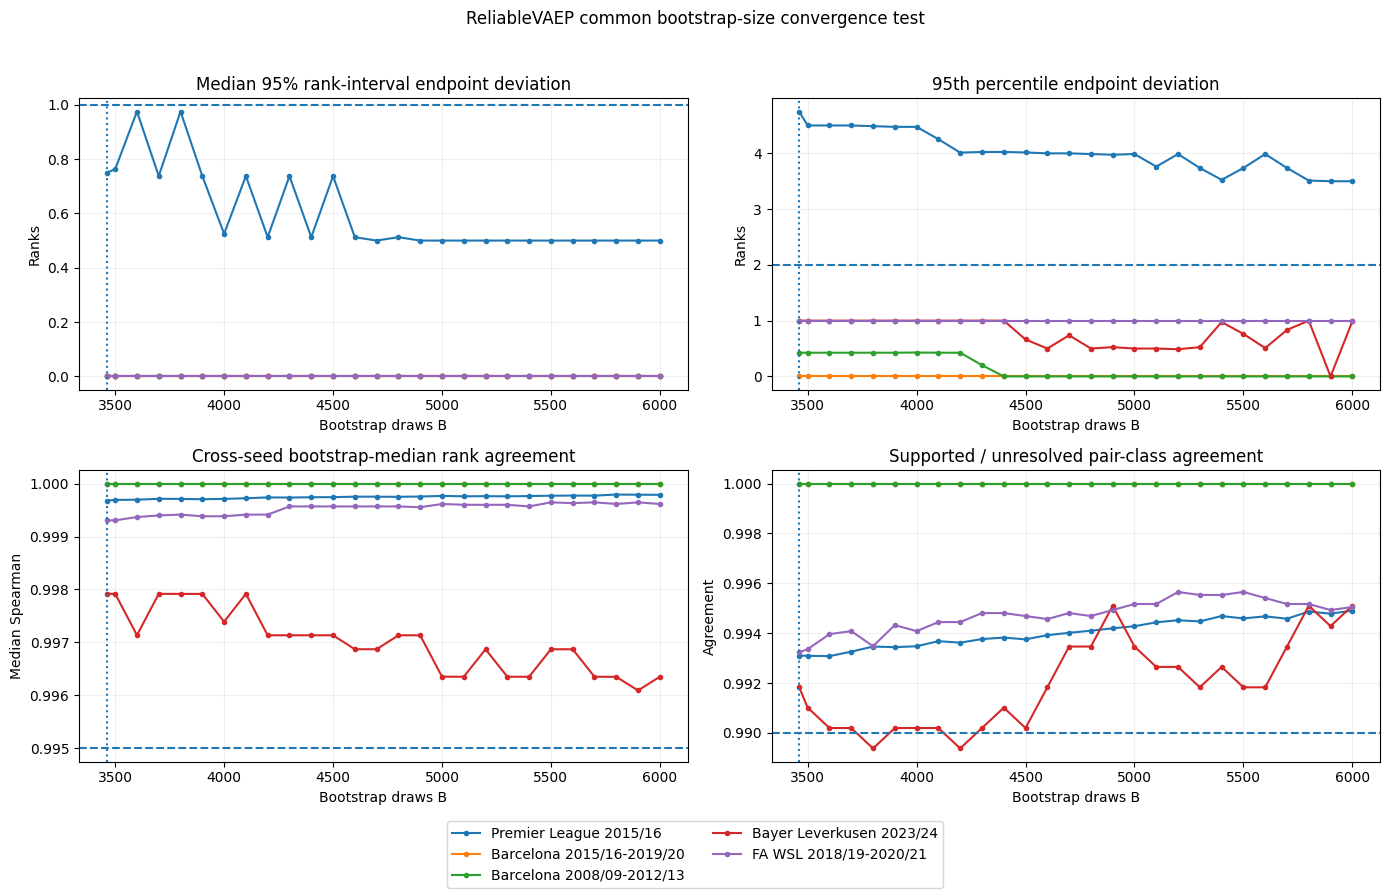

Saved: /kaggle/working/rv_bootstrap_minimum_results/05_bootstrap_minimum_convergence.png


In [29]:

# ================================================================
# CELL 13 — CONVERGENCE FIGURE
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for label, q in diagnostics.groupby("dataset", sort=False):
    axes[0, 0].plot(
        q["B"],
        q["median_endpoint_abs_dev"],
        marker="o",
        ms=3,
        label=label,
    )
    axes[0, 1].plot(
        q["B"],
        q["p95_endpoint_abs_dev"],
        marker="o",
        ms=3,
        label=label,
    )
    axes[1, 0].plot(
        q["B"],
        q["median_cross_seed_rank_spearman"],
        marker="o",
        ms=3,
        label=label,
    )
    axes[1, 1].plot(
        q["B"],
        q["pair_class_agreement"],
        marker="o",
        ms=3,
        label=label,
    )

axes[0, 0].axhline(
    MEDIAN_ENDPOINT_DEV_MAX,
    linestyle="--",
)
axes[0, 0].set_title(
    "Median 95% rank-interval endpoint deviation"
)
axes[0, 0].set_ylabel("Ranks")

axes[0, 1].axhline(
    P95_ENDPOINT_DEV_MAX,
    linestyle="--",
)
axes[0, 1].set_title(
    "95th percentile endpoint deviation"
)
axes[0, 1].set_ylabel("Ranks")

axes[1, 0].axhline(
    MEDIAN_RANK_SPEARMAN_MIN,
    linestyle="--",
)
axes[1, 0].set_title(
    "Cross-seed bootstrap-median rank agreement"
)
axes[1, 0].set_ylabel("Median Spearman")

axes[1, 1].axhline(
    PAIR_CLASS_AGREEMENT_MIN,
    linestyle="--",
)
axes[1, 1].set_title(
    "Supported / unresolved pair-class agreement"
)
axes[1, 1].set_ylabel("Agreement")

for ax in axes.flat:
    ax.set_xlabel("Bootstrap draws B")
    ax.grid(alpha=0.2)
    ax.axvline(
        B_MC,
        linestyle=":",
    )
    if FINAL_B is not None:
        ax.axvline(
            FINAL_B,
            linestyle="-.",
        )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
)
fig.suptitle(
    "ReliableVAEP common bootstrap-size convergence test",
    y=0.98,
)
fig.tight_layout(
    rect=[0, 0.08, 1, 0.96]
)

figure_path = (
    RESULT_ROOT
    / "05_bootstrap_minimum_convergence.png"
)
fig.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Saved:", figure_path)


In [30]:

# ================================================================
# CELL 14 — PAPER-READY STATEMENT + RESULTS ZIP
# ================================================================

import shutil

if FINAL_B is not None:
    method_statement = f"""
Bootstrap size was selected using a predeclared numerical-precision and
cross-seed convergence rule rather than an arbitrary round number. Because
ReliableVAEP classifies pairwise orderings as supported at P(i>j) >=
{PAIRWISE_SUPPORT:.2f} (or <= {1.0-PAIRWISE_SUPPORT:.2f}), we required the
{MC_CONFIDENCE:.0%} Monte Carlo Wilson half-width at the decision boundary
to be no greater than {MC_HALF_WIDTH_TARGET:.3f}. This yielded an analytical
lower bound of B={B_MC}. Starting from that bound, the player-preserving
match bootstrap was repeated under {N_REPLICATES} independent random seeds
for each study dataset. A candidate B was accepted only when 95% rank-interval
endpoints, bootstrap-median player ordering, and supported/unresolved pair
classifications satisfied the predeclared convergence criteria. To avoid an
isolated crossing, all criteria had to remain satisfied for
{SUSTAINED_B_POINTS} consecutive tested values. The smallest common value
meeting these requirements across all datasets was B={FINAL_B}, which was
therefore selected for the final analyses.
""".strip()

    print(method_statement)

    (
        RESULT_ROOT
        / "06_paper_ready_bootstrap_selection_statement.txt"
    ).write_text(
        method_statement,
        encoding="utf-8",
    )
else:
    print(
        "A paper-ready B cannot yet be reported because no universal "
        "sustained solution was found within the tested range."
    )

zip_path = shutil.make_archive(
    "/kaggle/working/ReliableVAEP_Bootstrap_Minimum_Test_Results",
    "zip",
    root_dir=RESULT_ROOT,
)

print("\nResults folder:", RESULT_ROOT)
print("Results ZIP:", zip_path)


A paper-ready B cannot yet be reported because no universal sustained solution was found within the tested range.

Results folder: /kaggle/working/rv_bootstrap_minimum_results
Results ZIP: /kaggle/working/ReliableVAEP_Bootstrap_Minimum_Test_Results.zip



## What to do with the result

If the notebook prints, for example,

```text
>>> UNIVERSAL MINIMUM B = 3900 <<<
```

then **3900** is the value to use in the final full-bootstrap ReliableVAEP analyses. Do not round it upward unless you explicitly decide to use a conservative operational round number and report that choice.

If it prints that no universal solution was found, increase `MAX_B` in Cell 2 and rerun. The notebook deliberately refuses to invent a value.

After \(B\) is established, rerun the final paper notebooks with the selected common full-bootstrap count so that the manuscript, figures, CSVs, and public repository are synchronized.
